# CASE 2025 Methodology
This notebook should be mainly executing code from modules from the package `rb_analysis`. Let's try and have no functions at all defined in here so we can more more easily export to a non-notebook use case (e.g. a robot online).

# Imports and Notebook setup

In [88]:
# import sys
# TODO Don't actually need this if in the same dir?
# Use a `pip install -e` for an editable install so we can just use absolute imports.
# sys.path.insert(0, "./rb_analysis")  # Import analysis code.

# Reload imports before every cell executes. This makes us able to edit imported
# modules and not have to rerun imports for changes to take effect.
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [89]:
import os
import time
from datetime import datetime
import logging
from math import pi
from pathlib import Path
from typing import Any, Generator, List, Optional


import matplotlib.pyplot as plt
from matplotlib.animation import FFMpegWriter
import matplotlib.ticker as ticker
import numpy as np
import pandas as pd
import PyKDL

# ROS2 imports
import rclpy
import tf2_geometry_msgs
import tf2_ros


# Ros2 message type imports
from control_msgs.msg import DynamicJointState
from geometry_msgs.msg import Pose, PoseStamped, TwistStamped, Vector3, Vector3Stamped
from pandas import DataFrame, Series
from scipy.spatial.transform import Rotation as R
from sensor_msgs.msg import Imu
from std_msgs.msg import Header, String
from tf2_msgs.msg import TFMessage
from tf2_ros import TransformStamped

# Custom module imports
import rb_analysis
from rb_analysis import bag_utils, ros_to_df


# Custom message imports
from motor_msgs.msg import MotorCurrents

In [90]:
# Set up some global plot styling.
plt.rcParams.update(
    {
        "axes.titlesize": 16,
        "axes.labelsize": 14,
        "xtick.labelsize": 12,
        "ytick.labelsize": 12,
        "legend.fontsize": 12,
        "figure.titlesize": 18,
    }
)

# Timestamp when this notebook was started
now = datetime.now().strftime("%Y_%m_%d_%H_%M_%S")


## Accept Parameters for Papermill
We can run this notebook as a script with papermill. The `parameters` tagged cell below tells papermill what parameters are available. Basically treats the whole notebook like a big ol' function.

In [91]:
# Papermill will insert a cell below with parameters overriding what we have in this cell!!
#######################################################

# Override this when runnig notebook as a script.


# MELAMINE
#######################################################################################
# Melamine 0.0Hz
bag_path = Path(
    "rosbags/2025_6_12_distance_rosbags/2025_6_12__17_15_31_distance_triangle_3.0base_0.01amp_0.3hz_7.0m_no_shutdown_board/2025_6_12__17_15_31_distance_triangle_3.0base_0.01amp_0.3hz_7.0m_no_shutdown_board.bag"
)

# Melamine 0.3Hz
# bag_path = Path(
#     "rosbags/2025_6_12_distance_rosbags/2025_6_12__17_17_01_distance_triangle_3.0base_3.0amp_0.3hz_7.0m_no_shutdown_board/2025_6_12__17_17_01_distance_triangle_3.0base_3.0amp_0.3hz_7.0m_no_shutdown_board.bag"
# )
# Melamine 0.8Hz
# bag_path = Path(
#     "rosbags/2025_6_12_distance_rosbags/2025_6_12__17_19_37_distance_triangle_3.0base_3.0amp_0.8hz_7.0m_no_shutdown_board/2025_6_12__17_19_37_distance_triangle_3.0base_3.0amp_0.8hz_7.0m_no_shutdown_board.bag"
# )

# Melamine 2Hz
# bag_path = Path(
#     "rosbags/2025_6_12_distance_rosbags/2025_6_12__17_26_56_distance_triangle_3.0base_3.0amp_2.0hz_7.0m_no_shutdown_board/2025_6_12__17_26_56_distance_triangle_3.0base_3.0amp_2.0hz_7.0m_no_shutdown_board.bag"
# )


# CONCRETE
###################################################################
# Concrete 0Hz
# bag_path = Path(
#     'rosbags/2025_6_12_distance_rosbags/2025_6_12__16_30_34_distance_triangle_3.0base_0.001amp_0.3hz_8.0m_no_shutdown_concrete/2025_6_12__16_30_34_distance_triangle_3.0base_0.001amp_0.3hz_8.0m_no_shutdown_concrete.bag'
# )
# Concrete 0.3Hz
# bag_path = Path(
#     "rosbags/2025_6_12_distance_rosbags/2025_6_12__16_34_09_distance_triangle_3.0base_3.0amp_0.3hz_8.0m_no_shutdown_concrete/2025_6_12__16_34_09_distance_triangle_3.0base_3.0amp_0.3hz_8.0m_no_shutdown_concrete.bag"
# )

# Concrete 0.8
# bag_path = Path(
#     'rosbags/2025_6_12_distance_rosbags/2025_6_12__16_38_09_distance_triangle_3.0base_3.0amp_0.8hz_8.0m_no_shutdown_concrete/2025_6_12__16_38_09_distance_triangle_3.0base_3.0amp_0.8hz_8.0m_no_shutdown_concrete.bag'
# )

# Concrete 2Hz
# bag_path = Path(
# 'rosbags/2025_6_12_distance_rosbags/2025_6_12__16_53_38_distance_triangle_3.0base_3.0amp_2.0hz_8.0m_no_shutdown_concrete/2025_6_12__16_53_38_distance_triangle_3.0base_3.0amp_2.0hz_8.0m_no_shutdown_concrete.bag'
# )


# VINYL
##############################################################
# Vinyl 0Hz
# bag_path = Path(
#     'rosbags/2025_6_12_distance_rosbags/2025_6_12__16_58_53_distance_triangle_3.0base_0.01amp_0.3hz_7.0m_no_shutdown_vinyl/2025_6_12__16_58_53_distance_triangle_3.0base_0.01amp_0.3hz_7.0m_no_shutdown_vinyl.bag'
# )

# Vinyl 0.3Hz
# bag_path = Path(
#     "rosbags/2025_6_12_distance_rosbags/2025_6_12__17_01_04_distance_triangle_3.0base_3.0amp_0.3hz_7.0m_no_shutdown_vinyl/2025_6_12__17_01_04_distance_triangle_3.0base_3.0amp_0.3hz_7.0m_no_shutdown_vinyl.bag"
# )

# 0.8Hz Vinyl
# bag_path = Path(
#     "rosbags/2025_6_12_distance_rosbags/2025_6_12__17_03_47_distance_triangle_3.0base_3.0amp_0.8hz_7.0m_no_shutdown_vinyl/2025_6_12__17_03_47_distance_triangle_3.0base_3.0amp_0.8hz_7.0m_no_shutdown_vinyl.bag"
# )
# bag_path = Path(
#     'rosbags/2025_6_12_distance_rosbags/2025_6_12__17_10_07_distance_triangle_3.0base_3.0amp_1.8hz_7.0m_no_shutdown_vinyl/2025_6_12__17_10_07_distance_triangle_3.0base_3.0amp_1.8hz_7.0m_no_shutdown_vinyl.bag'
# )
# 2hz Vinyl
# bag_path = Path('rosbags/2025_6_12_distance_rosbags/2025_6_12__17_12_50_distance_triangle_3.0base_3.0amp_2.0hz_7.0m_no_shutdown_vinyl/2025_6_12__17_12_50_distance_triangle_3.0base_3.0amp_2.0hz_7.0m_no_shutdown_vinyl.bag')


log_level = "INFO"

# Save all our plots and videos here.
artifact_dir = Path(f'artifacts/{now}_artifacts_{str(bag_path.name)}/')
artifact_dir.mkdir(parents=True, exist_ok=True)
artifact_dir = str(artifact_dir)

# concrete, vinyl, melamine, etc.
surface_name = ""

plot_subtitle = None

owner_dir = None
# Papermill will insert a cell below with parameters overriding what we have in this cell!!
#######################################################

In [92]:
# Setup a logger object to use the log_level.
lvl = getattr(logging, log_level.upper(), logging.INFO)
logging.basicConfig(
    force=True, level=lvl, format="%(asctime)s %(levelname)s: %(message)s", datefmt="%H:%M:%S"
)
logger = logging.getLogger("my_notebook")

# Can conditionally run code depending on log level with `if logger.isEnabledFor(logging.INFO):`
print(f"Logging is now at {logging.getLevelName(lvl)}")
logger.info("Logging is now at INFO level")

# Put final values in this dict to be pickled out.
final_vals = {}



04:08:48 INFO: Logging is now at INFO level


Logging is now at INFO


# Analysis Steps
* Load ROSbag and set meta_info dict for naming purposes.
* Convert ROSbags into `raw_msgs` dict {topic:message}.
* Capture static TF tree and add to `raw_msgs`
* Convert `raw_msgs` to DataFrames in `raw_data` dict.
* Create `proc_data` Preprocess data  (remove outlers, filter)
* Create derived data products (vicon_vel, wheel_vel, etc)
* 
* Capture TF tree (vicon, odom, )

When do we transform spatial data? Before use or after? Just transform data to vicon, odom, and base_link straight off? How about each wheel? For the size of data we have we could just use the vicon pose to get poses for base_link, right__front_wheel, left_front_wheel, etc. This is redundant but it makes it convenient.

For each datafame log manipulations in that dataframe with parameters and function calls.

# Read ROSbag data.
We're going to use a global dict `results` to hold all the data for a run of the analysis pipeline. The contents will be of the type `pandas.DataFrame` and will be one-to-one conversions from the ros2 message message objects. The conversion will be handled by the `rb_analysis.ros_to_df` module.

Hungarian naming will differentiate between `raw`, `cleaned`, and `derived` data. Dataframes like `encoder_count_raw` are the literal conversion from an encoder topic. Dataframes named like `encoder_data_cleaned` are the same data but with preprocessing applied to them like removing outliers, removing empty indices, smoothing, etc. The preprocessing steps applied to a dataframe will be recorded in the `DataFrame.attrs` dictionary under the key `processing_steps`. Each message type will have a module associated with it that has functions to perform the cleaning steps.

For now prefer to keep data which is exactly time-syncrhonized in the same dataframe. We will do interpolation later.

In [93]:
"""
Try to open the rosbag and copy some of the metadata into the `metadata` global dict.
"""
# Turn the bag_path into a Path object here since we can't pass in non JSON
# serializable objects as papermill params. So basically any non primitive type?
bag_path = Path(bag_path)
# Try to open our rosbag dir and error out if we can't find it.
logger.info(f"Opening: {bag_path=}")
logger.info(f"Looking for rosbag in {os.getcwd()}/")
if not bag_path.is_dir():
    raise IOError("Can't find bagfile!")
logger.info("Found bagfile!")

# Keeps information about what data we've used and what we've done.
metadata: dict[str, Any] = {}
metadata = {
    "bag_path": bag_path.name,
    "analysis_timestamp": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
    "log_level": logging.getLevelName(lvl),
    'owner_dir': None,
}

04:08:48 INFO: Opening: bag_path=PosixPath('rosbags/2025_6_12_distance_rosbags/2025_6_12__17_15_31_distance_triangle_3.0base_0.01amp_0.3hz_7.0m_no_shutdown_board/2025_6_12__17_15_31_distance_triangle_3.0base_0.01amp_0.3hz_7.0m_no_shutdown_board.bag')
04:08:48 INFO: Looking for rosbag in /home/rb/retail-bot/analysis/
04:08:48 INFO: Found bagfile!


In [94]:
"""
Copy out the ros message from the rosbag. Hack in the static_tf Transforms for now.
"""

bag_meta = bag_utils.get_metadata(input_bag=str(bag_path))

# Create subtitle automatically.
if not plot_subtitle:
    metadata["plot_subtitle"] = str(bag_path.name)

metadata["start_time"] = bag_meta.starting_time
metadata["artifact_dir"] = artifact_dir # Save plots and pkl here.
metadata["duration"] = bag_meta.duration
metadata["topics_with_message_count"] = bag_meta.topics_with_message_count
metadata["bag_meta"] = bag_meta
metadata['surface_name'] = surface_name

if owner_dir: # If this is set then save the pkl or anything else that should be together for a batch job.
    metadata['owner_dir'] = owner_dir # Usually ../

# Get a dict of ros message objects for each topic.
ros_msgs: dict[str, list[type]]
ros_msgs = bag_utils.read_bag(bag_path=bag_path)

# Hack in the static transforms from the URDF. Ignore type error.
ros_msgs["/tf_static"] = rb_analysis.make_static_tf.make_static_tf()  # type: ignore


if logger.getEffectiveLevel() <= logging.INFO:
    # # Let's peek at the raw tf_static message. There's only one here since we made it manually.
    print(ros_msgs["/tf_static"])
    print(metadata)

# ── quick throughput table straight from the bag metadata ────────────────
# (no need to touch the messages themselves)

dur_s = bag_meta.duration.nanoseconds * 1e-9                  # seconds
print(f"\nBag duration ≈ {dur_s:.2f} s\n")

hdr = f"{'topic':<50} {'msgs':>8} {'Hz≈':>10}"
print(hdr)
print("-"*len(hdr))

for topic_info in bag_meta.topics_with_message_count:
    name  = topic_info.topic_metadata.name
    n_msg = topic_info.message_count
    hz    = n_msg / dur_s if dur_s > 0 else float("nan")
    print(f"{name:<50} {n_msg:>8} {hz:>10.1f}")


/home/rb/retail-bot/analysis
rosbags/2025_6_12_distance_rosbags/2025_6_12__17_15_31_distance_triangle_3.0base_0.01amp_0.3hz_7.0m_no_shutdown_board/2025_6_12__17_15_31_distance_triangle_3.0base_0.01amp_0.3hz_7.0m_no_shutdown_board.bag
tf2_msgs.msg.TFMessage(transforms=[geometry_msgs.msg.TransformStamped(header=std_msgs.msg.Header(stamp=builtin_interfaces.msg.Time(sec=0, nanosec=0), frame_id='bl_wheel'), child_frame_id='bl_patch', transform=geometry_msgs.msg.Transform(translation=geometry_msgs.msg.Vector3(x=4.85722573273506e-17, y=5.551115123125783e-17, z=-0.1337945000000001), rotation=geometry_msgs.msg.Quaternion(x=-7.216449660051615e-16, y=3.885780586188474e-16, z=-2.775557561553138e-16, w=1.0))), geometry_msgs.msg.TransformStamped(header=std_msgs.msg.Header(stamp=builtin_interfaces.msg.Time(sec=0, nanosec=0), frame_id='br_wheel'), child_frame_id='br_patch', transform=geometry_msgs.msg.Transform(translation=geometry_msgs.msg.Vector3(x=6.938893903907228e-18, y=0.0, z=-0.1337945000000001

In [95]:
"""Convert the messages into DataFrames.

Most messages can be automatically flattened out into dataframe columns with our
`ros_to_df.extract_tf_dataframes` func. For tf_static we use another function
just for that.

TODO merge the `extract_tf_dataframes` behaviour into read_bag.
"""

# Store each topic's list of ros messages as a dataframe.
raw_data = dict[str, DataFrame]()

# Convert tf to DataFrames seperately for now and add to rest of dataframes in raw_data.
tf_data = ros_to_df.extract_tf_dataframes(ros_msgs)
raw_data.update(tf_data)

# For each topic read through all it's messages and convert to a DataFrame.
for topic_name, messages in ros_msgs.items():
    # Skip tf or tf_static messages.
    if topic_name == "/tf" or topic_name == "/tf_static":
        continue
    if not messages:
        logger.info(f"No messages on {topic_name=}")
        continue
    try:
        # Save converted messages as a df in a dict.
        raw_data[topic_name] = ros_to_df.ros_message_to_df(messages)
    except Exception as e:
        logger.info(f"Error converting: {topic_name=}, {e=}")

# Print all topic dataframes, row counts, and earliest message's timestamp.
if logger.getEffectiveLevel() <= logging.INFO:
    for name, df in raw_data.items():
        print(f"{name=:<30} {type(df)}: {len(df)=:10} \t {df.index.min()}")

04:08:49 INFO: No messages on topic_name='/events/write_split'
04:08:49 INFO: No messages on topic_name='/parameter_events'
04:08:49 INFO: No messages on topic_name='/vrpn_mocap/Go2_test/twist'
04:08:49 INFO: No messages on topic_name='/vrpn_mocap/melamine_sheet/pose'
04:08:49 INFO: No messages on topic_name='/vrpn_mocap/vinyl_sheet/pose'
04:08:49 INFO: No messages on topic_name='/vrpn_mocap/vinyl_sheet/accel'
04:08:49 INFO: No messages on topic_name='/vrpn_mocap/Go2_test/accel'
04:08:49 INFO: No messages on topic_name='/joint_state_broadcaster/transition_event'
04:08:49 INFO: No messages on topic_name='/vrpn_mocap/melamine_sheet/accel'
04:08:49 INFO: No messages on topic_name='/vrpn_mocap/melamine_sheet/twist'
04:08:49 INFO: No messages on topic_name='/vrpn_mocap/vinyl_sheet/twist'
04:08:49 INFO: No messages on topic_name='/rb/cmd_vel'
04:08:49 INFO: No messages on topic_name='/vrpn_mocap/Go2_test/pose'
04:08:49 INFO: No messages on topic_name='/rb_slip_controller/transition_event'
04

name=/tf_static                     <class 'pandas.core.frame.DataFrame'>: len(df)=         9 	 1970-01-01 00:00:00
name=/tf                            <class 'pandas.core.frame.DataFrame'>: len(df)=      3401 	 2025-06-12 21:15:33.563421440
name=/dynamic_joint_states          <class 'pandas.core.frame.DataFrame'>: len(df)=      1135 	 2025-06-12 21:15:33.563421488
name=/left_motor_currents           <class 'pandas.core.frame.DataFrame'>: len(df)=      6809 	 2025-06-12 21:15:32.950862646
name=/right_motor_currents          <class 'pandas.core.frame.DataFrame'>: len(df)=      6527 	 2025-06-12 21:15:32.929126501
name=/rb_slip_controller/cmd_vel    <class 'pandas.core.frame.DataFrame'>: len(df)=      4268 	 2025-06-12 21:15:32.660066843
name=/vrpn_mocap/rb1/accel          <class 'pandas.core.frame.DataFrame'>: len(df)=      4118 	 2025-06-12 21:15:33.564753532
name=/vrpn_mocap/rb1/pose           <class 'pandas.core.frame.DataFrame'>: len(df)=      4119 	 2025-06-12 21:15:33.564678431
na

# Clean Raw Data
Make a seperate copy of `raw_data` called `cleaned_data`. Make all modifications **in place** to `cleaned_data`!

Depending on the type of data and the topic we need to:
* Rename column names to be more semantically meaningful and concise.
* Set epoch to t=0 by subtracting Unix epoch.
* remove outliers 
* filter out noise

In [96]:
import copy

"""
Make a copy of the raw_data dict named cleaned_data which we will mutate and add to.
"""

# Make a deep copy of raw_data so we can keep the original.
raw_data_copy: dict[str, DataFrame] = copy.deepcopy(raw_data)

# Sanity check the message topics and message counts again.
if logger.getEffectiveLevel() <= logging.INFO:
    for name, val in raw_data_copy.items():
        logger.debug(f"{name=:<30} {type(val)=}: {len(val)=:20}")

## Rename DataFrame Columns
Make them more meaningful if not already so.

In [97]:
""" Rename the columns of the dataframe to be more manageable and semantically meaningful.

# TODO Rename more topic column names
"""


def rename_cols(data: dict) -> dict:
    """For each dataframe rename the column names.

    Args:
        df (dict): Dictionary of dataframes.

    Returns:
        dict: Renamed dataframes.
    """
    # Rename left motor currents.
    data["/left_motor_currents"].rename(
        columns={
            "data.0": "left_front_amps",
            "data.1": "left_back_amps",
        },
        inplace=True,
    )
    logger.debug(data["/left_motor_currents"].columns)

    # Rename right motor currents.
    data["/right_motor_currents"].rename(
        columns={
            "data.0": "right_front_amps",
            "data.1": "right_back_amps",
        },
        inplace=True,
    )
    logger.debug(data["/right_motor_currents"].columns)

    # Rename encoders.
    data["/dynamic_joint_states"].rename(
        columns={
            "joint.fr_wheel_joint.position": "fr_wheel_position",
            "joint.fr_wheel_joint.velocity": "fr_wheel_velocity",
            "joint.fr_wheel_joint.encoder_count": "fr_wheel_encoder_count",
            "joint.fr_wheel_joint.current": "fr_wheel_current",
            "joint.br_wheel_joint.position": "br_wheel_position",
            "joint.br_wheel_joint.velocity": "br_wheel_velocity",
            "joint.br_wheel_joint.encoder_count": "br_wheel_encoder_count",
            "joint.br_wheel_joint.current": "br_wheel_current",
            "joint.fl_wheel_joint.position": "fl_wheel_position",
            "joint.fl_wheel_joint.velocity": "fl_wheel_velocity",
            "joint.fl_wheel_joint.encoder_count": "fl_wheel_encoder_count",
            "joint.fl_wheel_joint.current": "fl_wheel_current",
            "joint.bl_wheel_joint.position": "bl_wheel_position",
            "joint.bl_wheel_joint.velocity": "bl_wheel_velocity",
            "joint.bl_wheel_joint.encoder_count": "bl_wheel_encoder_count",
            "joint.bl_wheel_joint.current": "bl_wheel_current",
        },
        inplace=True,
    )
    logger.debug(data["/dynamic_joint_states"].columns)

    # Rename Vicon pose.
    data["/vrpn_mocap/rb1/pose"].rename(
        columns={
            "header.stamp.sec": "sec",
            "header.stamp.nanosec": "nanosec",
            "header._frame_id": "frame_id",
            "pose.position.x": "x",
            "pose.position.y": "y",
            "pose.position.z": "z",
            "pose.orientation.x": "qx",
            "pose.orientation.y": "qy",
            "pose.orientation.z": "qz",
            "pose.orientation.w": "qw",
        },
        inplace=True,
    )
    logger.debug(data["/vrpn_mocap/rb1/pose"].columns)

    return data


cleaned_data = rename_cols(data=raw_data_copy)

## Plot Data Before Cleaning

In [98]:
import matplotlib
from matplotlib.figure import Figure

"""
Plot all the dataframes prior to any modifications.
"""


def plot_cleaned(data) -> list[Figure]:
    figs = []

    # Left motor currents
    cleaned_data["/left_motor_currents"][["left_front_amps", "left_back_amps"]].plot(
        title=f"Raw Left Motor Current Data \n{metadata['plot_subtitle']}",
        xlabel="Seconds",
        ylabel="Amperes",
        subplots=True,
        grid=True,
    )
    figs.append(plt.gcf())

    # Right motor currents
    cleaned_data["/right_motor_currents"][["right_front_amps", "right_back_amps"]].plot(
        title=f"Raw Right Motor Current Data\n{metadata['plot_subtitle']}",
        xlabel="Seconds",
        ylabel="Amperes",
        subplots=True,
        grid=True,
    )
    figs.append(plt.gcf())

    # Right motor currents
    cleaned_data["/vrpn_mocap/rb1/pose"][
        [
            "x",
            "y",
            "z",
        ]
    ].plot(
        title=f"Raw Vicon-frame Marker Position Data\n{metadata['plot_subtitle']}",
        xlabel="Seconds",
        ylabel="Meters",
        subplots=True,
        grid=True,
    )
    figs.append(plt.gcf())
    # Right motor currents
    cleaned_data["/vrpn_mocap/rb1/pose"][["qx", "qy", "qz", "qw"]].plot(
        title=f"Raw Vicon-frame Marker Orientation Data\n{metadata['plot_subtitle']}",
        xlabel="Seconds",
        ylabel="Meters",
        subplots=True,
        grid=True,
    )
    figs.append(plt.gcf())
    # Encoder Counts
    cleaned_data["/dynamic_joint_states"][
        [
            "fr_wheel_encoder_count",
            "fl_wheel_encoder_count",
            "br_wheel_encoder_count",
            "bl_wheel_encoder_count",
        ]
    ].plot(
        title=f"Raw Encoder Counts\n{metadata['plot_subtitle']}",
        xlabel="Seconds",
        ylabel="Count",
        subplots=True,
        grid=True,
    )
    figs.append(plt.gcf())
    return figs


if logger.getEffectiveLevel() <= logging.DEBUG:
    figs = plot_cleaned(data=cleaned_data)

    for i, fig in enumerate(figs, 1):
        fig.savefig(f"test_fig_out/plot_{i}.png", dpi=300, bbox_inches="tight")

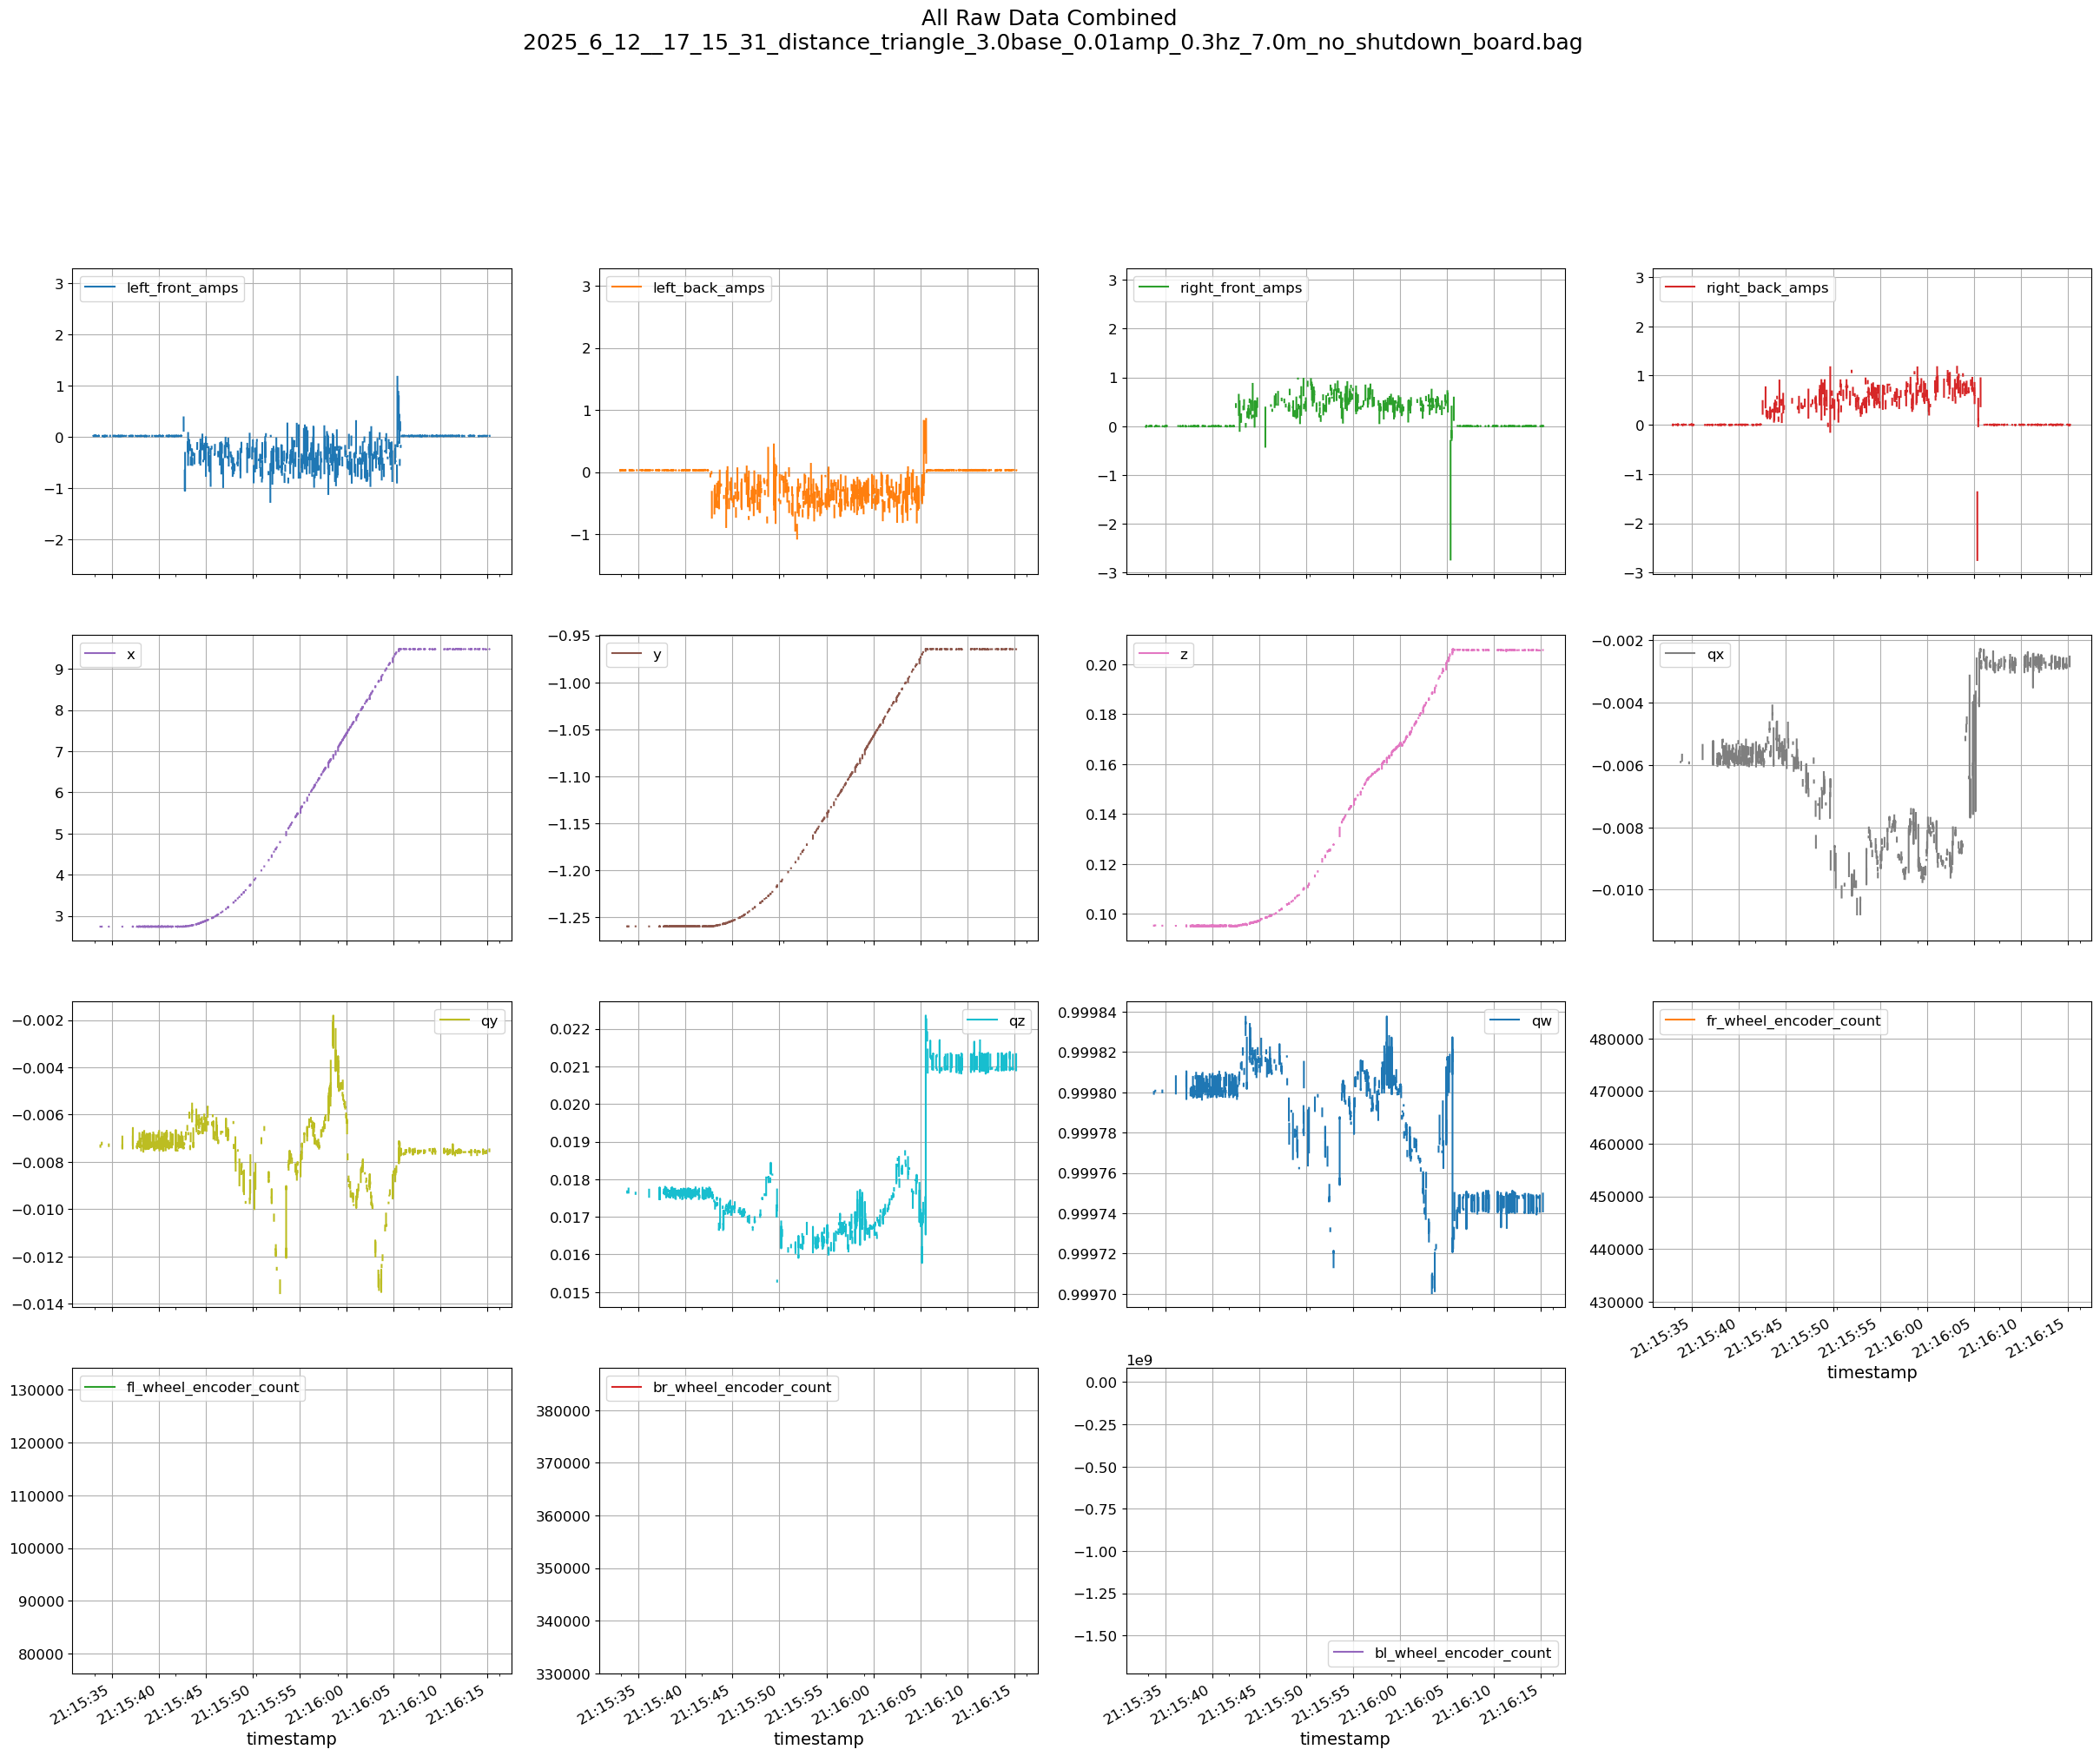

In [99]:
# Grab all cols to plot.
init_cleaned_data_df = [
    cleaned_data["/left_motor_currents"][
        [
            "left_front_amps",
            "left_back_amps",
        ]
    ],
    cleaned_data["/right_motor_currents"][
        [
            "right_front_amps",
            "right_back_amps",
        ]
    ],
    cleaned_data["/vrpn_mocap/rb1/pose"][
        [
            "x",
            "y",
            "z",
        ]
    ],
    cleaned_data["/vrpn_mocap/rb1/pose"][
        [
            "qx",
            "qy",
            "qz",
            "qw",
        ]
    ],
    cleaned_data["/dynamic_joint_states"][
        [
            "fr_wheel_encoder_count",
            "fl_wheel_encoder_count",
            "br_wheel_encoder_count",
            "bl_wheel_encoder_count",
        ]
    ],
]

# Put into one big dataframe we plot.
big_df = pd.concat(init_cleaned_data_df, axis=1)
combined_plot = big_df.plot(
    title=f"All Raw Data Combined\n {metadata['plot_subtitle']}",
    subplots=True,
    layout=(5, max(len(df.columns) for df in init_cleaned_data_df)),
    figsize=(30, 30),
    grid=True,
    sharex=True,
)
plt.savefig(f'{metadata["artifact_dir"]}/all_raw_data_combined.png', dpi=200, bbox_inches="tight")

## Change Timestamps to be in "Trial Epoch" Instead of Unix Epoch.
Makes it easier to work with the numerbs. Keep nidex type as Timestamp for precision.

In [100]:
from rb_analysis import data_cleaning

""" Change timestamps to begin from 0 when trial started.

Find the earliest timestamped message and subtract that from all the other
messages. The tf_static timestamps will be a bit weird since they are persistent
across trials.

TODO tf_static is odd because it persists between launches.

"""

# Get earliest Unix epoch timestamp of trial.
epoch_topic, epoch_time = data_cleaning.get_trial_epoch(raw_data)
logger.info(msg=f"Trial epoch: {epoch_topic=}, {epoch_time=}")

# Offset all timeindices by UNix timestamp to have them all be in "trial epoch".
data_cleaning.reset_trial_epoch(list(cleaned_data.values()), epoch_time)

# Print earliest timestamps in seconds for each dataframe (topic).
if logger.getEffectiveLevel() <= logging.DEBUG:
    for topic, df in cleaned_data.items():
        logging.info(f"{topic:<30}\t EARLIEST TIME (seconds): {df.index.min():>} (seconds)")


for name, df in cleaned_data.items():
    idx_ok  = (df.index.dtype == "float64")
    sorted_ = df.index.is_monotonic_increasing
    dupes   = df.index.has_duplicates

    if not idx_ok:
        print(f"⚠️  {name}: index dtype is {df.index.dtype} (expected float64)")
    elif (not sorted_) or dupes:
        print(f"⚠️  {name}: bad index (sorted={sorted_}, dups={dupes})")



04:08:52 INFO: Trial epoch: epoch_topic='/rb_slip_controller/cmd_vel', epoch_time=Timestamp('2025-06-12 21:15:32.660066843')


⚠️  /tf_static: bad index (sorted=True, dups=True)
⚠️  /tf: bad index (sorted=True, dups=True)
⚠️  /rosout: index dtype is int64 (expected float64)
⚠️  /robot_description: index dtype is int64 (expected float64)


## Setup Static Transforms
This should be the same for every trial since we're hard coding it and not actually reading from the */tf_static* topic.

In [101]:
from rb_analysis import plot_utils

if logger.getEffectiveLevel() <= logging.DEBUG:
    # Let's have a peek at the static transforms values.
    # print(cleaned_data["/tf_static"].to_string())

    # Sanity check frame arrangement.
    plot_utils.plot_static_tf_frames_3d(cleaned_data["/tf_static"])

In [102]:
from rb_analysis import transform_utils

""" Create direct vicon_ball->XX_patch transforms as PyKDL frames.

Calculate the four vicon_ball -> XX_patch transforms so we can use them later
when transforming the Pose and Twist of the vicon_ball.
"""

# Get the static transforms as KDL frames and find the direct xform from vicon_ball->XX_patch.
kdl_xforms = transform_utils.df_static_to_kdl_transforms(cleaned_data["/tf_static"])
patch_names = ["bl_patch", "br_patch", "fl_patch", "fr_patch"]
patch_xforms = {
    p: transform_utils.get_kdl_chain(kdl_xforms, source="vicon_ball", target=p)
    for p in patch_names
}

# Print out the transform values.
for name, T in patch_xforms.items():
    x, y, z = T.p.x(), T.p.y(), T.p.z()
    qx, qy, qz, qw = T.M.GetQuaternion()
    print(
        f"{name}: trans=({x:.4f}, {y:.4f}, {z:.4f}), quat=({qx:.3e}, {qy:.3e}, {qz:.3e}, {qw:.3f})"
    )

# Hack into a df and put in cleaned_data
cleaned_data["patch_xforms"] = pd.DataFrame(data=patch_xforms, index=[0])
# type(cleaned_data['patch_xforms'].br_patch[0])


bl_patch: trans=(-0.3302, -0.0819, -0.1338), quat=(-1.150e-15, 9.313e-16, 1.126e-16, 1.000)
br_patch: trans=(-0.3302, -0.5963, -0.1338), quat=(2.935e-16, 3.862e-16, 1.109e-16, 1.000)
fl_patch: trans=(0.3302, -0.0819, -0.1338), quat=(-3.170e-16, 5.427e-16, 3.902e-16, 1.000)
fr_patch: trans=(0.3302, -0.5963, -0.1338), quat=(-5.063e-16, 5.427e-16, 3.902e-16, 1.000)


## Check Marker Pose Trajectory


In [103]:
from rb_analysis import tf_plot_utils

""" Animate raw vicon_frame_marker_pose
"""

if logger.getEffectiveLevel() <= logging.DEBUG:
    # Look at the trajectory of the vicon_marker.
    ani = tf_plot_utils.ViconPoseAnimator(
        raw_data["/vrpn_mocap/rb1/pose"],
        dpi=60,
        azim=0,
        interval=30,
        elev=100,
    )
    # ani.run()

## Remove Outliers
Any rows with missing data or outliers. The current data especially suffers from this.


### Remove Encoder Outliers

[{'orig_nans': fr_wheel_encoder_count    0
br_wheel_encoder_count    0
fl_wheel_encoder_count    0
bl_wheel_encoder_count    0
dtype: int64, 'new_nans': fr_wheel_encoder_count    0
br_wheel_encoder_count    0
fl_wheel_encoder_count    0
bl_wheel_encoder_count    1
dtype: int64, 'removed': fr_wheel_encoder_count    0
br_wheel_encoder_count    0
fl_wheel_encoder_count    0
bl_wheel_encoder_count    1
dtype: int64}]


array([<AxesSubplot: xlabel='Seconds', ylabel='Count'>,
       <AxesSubplot: xlabel='Seconds', ylabel='Count'>,
       <AxesSubplot: xlabel='Seconds', ylabel='Count'>,
       <AxesSubplot: xlabel='Seconds', ylabel='Count'>], dtype=object)

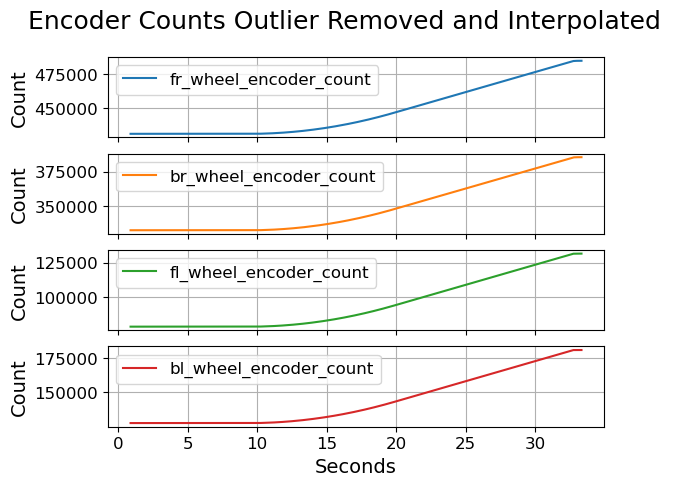

In [104]:
from rb_analysis import encoders
from rb_analysis import outliers_and_interp

# from data_analysis.utils.encoder_utils import remove_encoder_outliers

"""Strip obvious outliers.

The encoder data is prone to spikes to 1e12 which are fairly easy to remove.
"""


def remove_encoder_outliers(df: pd.DataFrame) -> pd.DataFrame:
    # Replace outliers with NaNs.
    encoder_counts_outliers_removed, *stats = outliers_and_interp.remove_outliers(
        df=df, window=51, z_thresh=2
    )
    print(stats)

    # Interpolate to fill NaNs.
    encoder_counts_outliers_removed = outliers_and_interp.interpolate_data(
        df=encoder_counts_outliers_removed
    )
    return encoder_counts_outliers_removed


# Get just the encoder counts.
encoder_counts = cleaned_data["/dynamic_joint_states"].loc[
    :,
    [
        "fr_wheel_encoder_count",
        "br_wheel_encoder_count",
        "fl_wheel_encoder_count",
        "bl_wheel_encoder_count",
    ],
]
# Remove the outliers
encoder_counts_outliers_removed = remove_encoder_outliers(encoder_counts)

# Store in global dict.
cleaned_data["encoder_counts_outliers_removed"] = encoder_counts_outliers_removed

# And plot the result
encoder_counts_outliers_removed.plot(
    title="Encoder Counts Outlier Removed and Interpolated ",
    xlabel="Seconds",
    ylabel="Count",
    subplots=True,
    grid=True,
)

### Remove Current Outliers

{'orig_nans': left_front_amps    0
left_back_amps     0
dtype: int64, 'new_nans': left_front_amps    1274
left_back_amps     1162
dtype: int64, 'removed': left_front_amps    1274
left_back_amps     1162
dtype: int64}


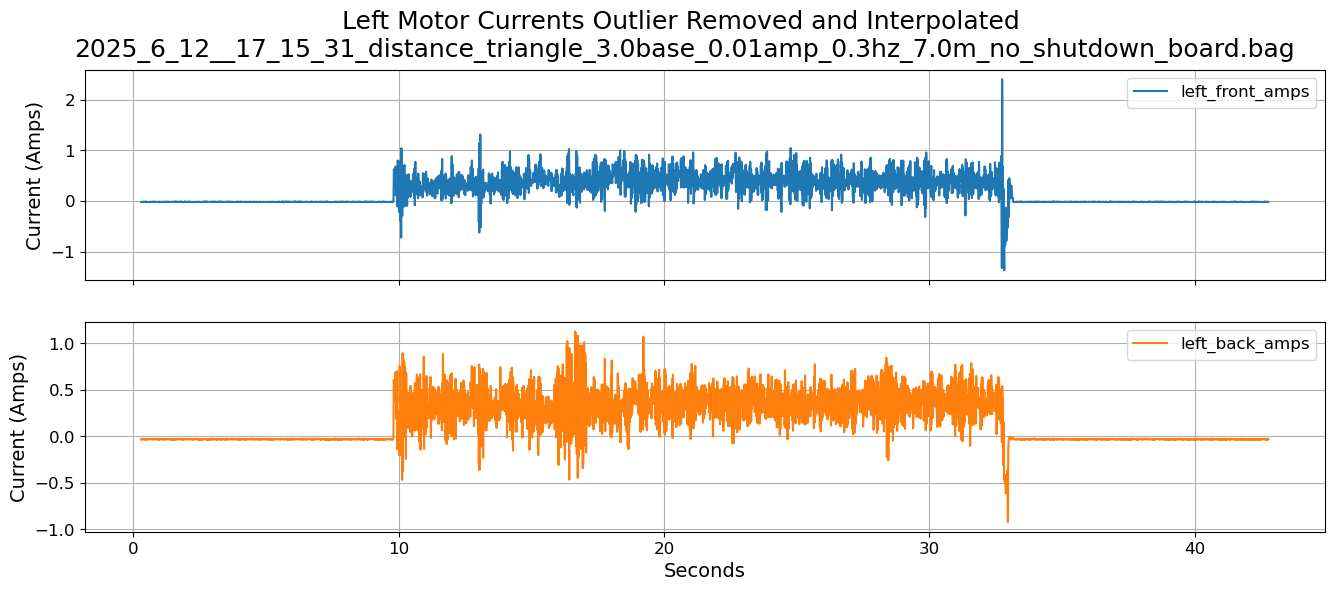

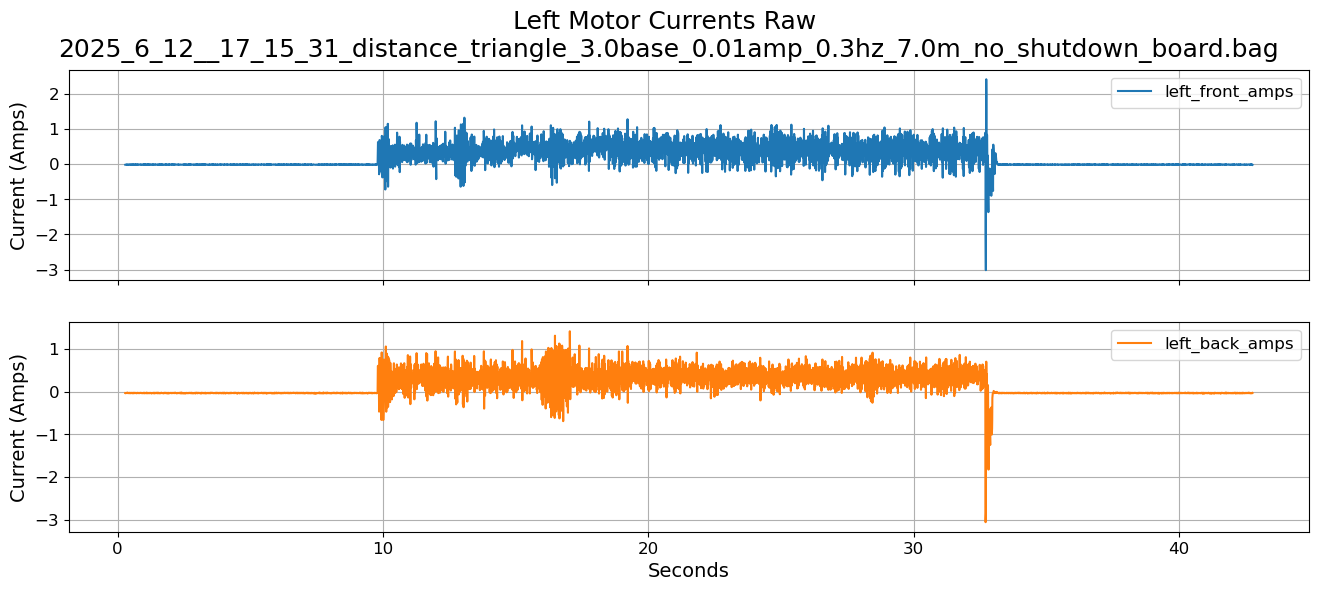

{'orig_nans': right_front_amps    0
right_back_amps     0
dtype: int64, 'new_nans': right_front_amps    1262
right_back_amps     1239
dtype: int64, 'removed': right_front_amps    1262
right_back_amps     1239
dtype: int64}


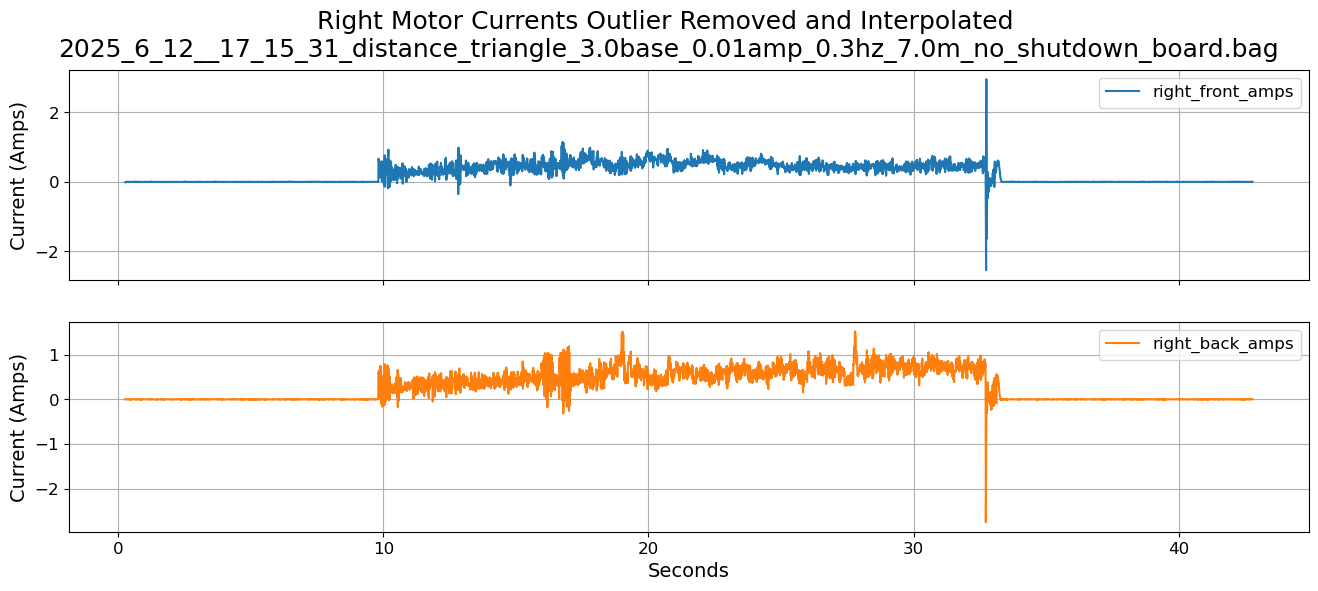

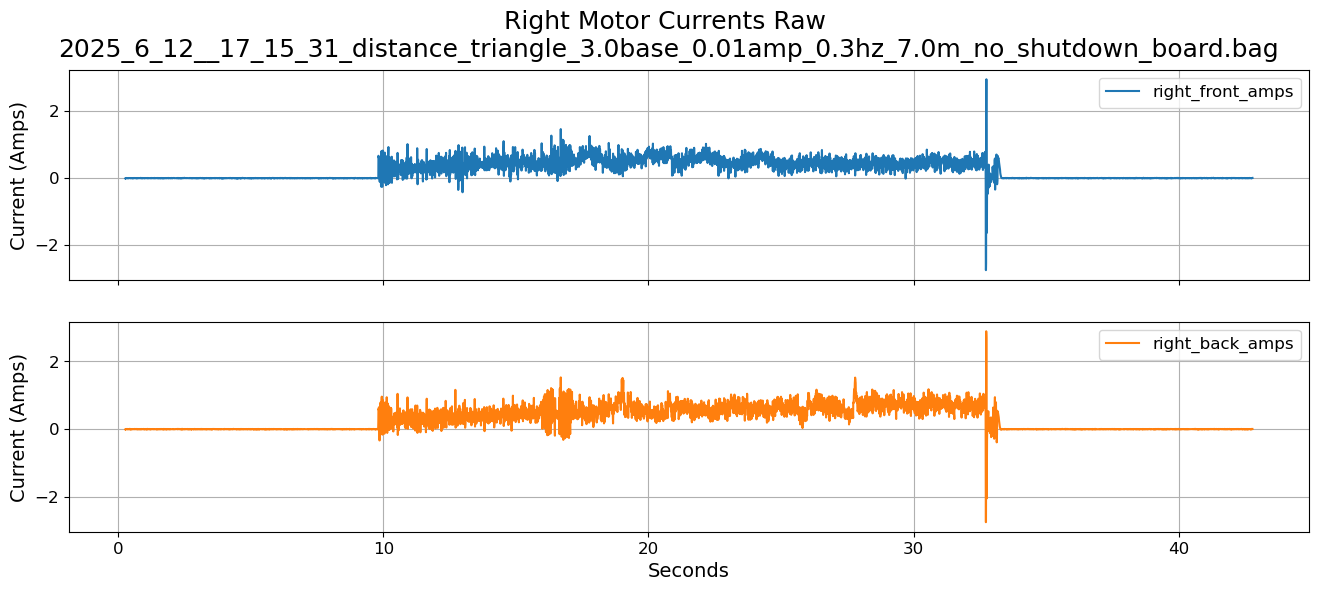

In [105]:
from rb_analysis.generic_plotting import plot_currents

""" Remove outliers from current data.

Same approach as encoders.
"""


def remove_current_outliers(df: pd.DataFrame) -> pd.DataFrame:
    # Remove outliers and interp.
    motor_currents_outliers_removed = outliers_and_interp.remove_outlier_and_interp(
        df=df, window=11, z_thresh=2
    )

    return motor_currents_outliers_removed


# Left currents.
# TODO FIX HACKY -1 SCALING!
left_motor_currents = (
    -1
    * cleaned_data["/left_motor_currents"].loc[
        :,
        [
            "left_front_amps",
            "left_back_amps",
        ],
    ]
)

# Remove outliers from left motor currents.
############################################################
left_motor_currents_outliers_removed = remove_current_outliers(left_motor_currents)
cleaned_data["left_motor_currents_outliers_removed"] = left_motor_currents_outliers_removed

# Plot before and after.
plot_left = plot_currents(
    left_motor_currents_outliers_removed,
    metadata=metadata,
    title="Left Motor Currents Outlier Removed and Interpolated ",
)
display(plot_left)

plot_left_raw = plot_currents(
    left_motor_currents,
    metadata=metadata,
    title="Left Motor Currents Raw ",
)
display(plot_left_raw)


# Left currents.
##############################################################
right_motor_currents = cleaned_data["/right_motor_currents"].loc[
    :,
    [
        "right_front_amps",
        "right_back_amps",
    ],
]
# Remove outliers from right motor currents.
right_motor_currents_outliers_removed = remove_current_outliers(right_motor_currents)
cleaned_data["right_motor_currents_outliers_removed"] = right_motor_currents_outliers_removed

# Plot before and after.
plot_right = plot_currents(
    right_motor_currents_outliers_removed,
    metadata=metadata,
    title="Right Motor Currents Outlier Removed and Interpolated ",
)
display(plot_right)
plot_right_raw = plot_currents(
    right_motor_currents,
    metadata=metadata,
    title="Right Motor Currents Raw ",
)
display(plot_right_raw)

### Remove IMU Outliers

In [106]:
""" Remove IMU outliers
Let's also remove bias from the linear acceleration values here as well.
"""
from rb_analysis.outliers_and_interp import remove_outlier_and_interp


def remove_imu_bias(accel_df: pd.DataFrame, window_size: int = 101) -> pd.DataFrame:
    """Remove just linear acceleration bias.
    Estimate and remove bias from IMU acceleration data by subtracting
    a centered rolling‐mean bias estimate.

    Parameters
    ----------
    accel_df : pd.DataFrame
        DataFrame containing one or more acceleration columns,
        indexed by time (numeric or datetime).
    window_size : int
        Window size (in samples) for the rolling‐mean bias estimate.

    Returns
    -------
    pd.DataFrame
        A new DataFrame of the same shape/index, with slow‐varying bias removed.
    """
    bias = accel_df.rolling(window=window_size, center=True, min_periods=1).mean()
    return accel_df - bias


def remove_imu_outliers(imu_df: pd.DataFrame) -> pd.DataFrame:
    """Remove outliers from IMU data. Just linear acceleration.

    Args:
        imu_df (pd.DataFrame): _description_

    Returns:
        pd.DataFrame: _description_
    """
    imu_outliers_removed = pd.DataFrame()
    return imu_outliers_removed


imu_cols = [
    "angular_velocity.x",
    "angular_velocity.y",
    "angular_velocity.z",
    "linear_acceleration.x",
    "linear_acceleration.y",
    "linear_acceleration.z",
]

# Remove IMU Bias.
###########################################
imu_df = pd.DataFrame(cleaned_data["/pico_imu"][imu_cols])
display(imu_df)
imu_unbiased = remove_imu_bias(imu_df, window_size=101)
cleaned_data["imu_unbiased"] = imu_unbiased


# Remove IMU outliers
##############################################
imu_outliers_removed = remove_outlier_and_interp(imu_unbiased, window=99, z_thresh=3)
cleaned_data["imu_outliers_removed"] = imu_outliers_removed


if logger.getEffectiveLevel() <= logging.DEBUG:
    imu_df.plot(title="IMU Before Bias and Outlier Removal", subplots=True)
    imu_outliers_removed.plot(title="IMU After Bias and Outlier Removal", subplots=True)

,angular_velocity.x,angular_velocity.y,angular_velocity.z,linear_acceleration.x,linear_acceleration.y,linear_acceleration.z
seconds_since_start,,,,,,
0.141447,-0.002094,0.005585,-0.000349,0.228005,-0.078453,9.924330
0.149350,-0.002094,-0.000349,0.005934,0.230456,-0.061292,9.929234
0.157385,-0.006632,0.004189,-0.001047,0.235360,-0.056388,9.912071
0.165377,-0.001745,0.001047,-0.003142,0.210843,-0.083357,9.865490
0.173107,-0.003840,0.004887,0.001047,0.242715,-0.071098,9.863038
...,...,...,...,...,...,...
42.740821,0.006981,-0.006981,0.002094,0.193681,-0.076002,9.855683
42.748895,0.002443,0.005585,-0.003491,0.240263,-0.112776,9.880199
42.757164,-0.004538,0.002443,-0.002793,0.232908,-0.076002,9.833618


{'orig_nans': angular_velocity.x       0
angular_velocity.y       0
angular_velocity.z       0
linear_acceleration.x    0
linear_acceleration.y    0
linear_acceleration.z    0
dtype: int64, 'new_nans': angular_velocity.x       303
angular_velocity.y       199
angular_velocity.z       254
linear_acceleration.x    259
linear_acceleration.y    272
linear_acceleration.z    240
dtype: int64, 'removed': angular_velocity.x       303
angular_velocity.y       199
angular_velocity.z       254
linear_acceleration.x    259
linear_acceleration.y    272
linear_acceleration.z    240
dtype: int64}


### Remove Vicon Pose Outliers


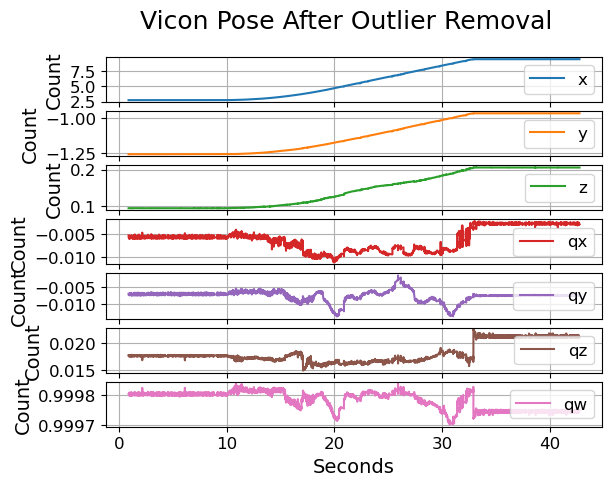

In [107]:
from rb_analysis import filtering
from rb_analysis.generic_plotting import plot_pose

""" Remove vicon pose outliers

This is a bit more complicated since the vicon pose has quaternions which can't
be interpolated as they don't live in a linear space. Can use SLERP for that.
"""

# Get the raw pose data.
vicon_pose_raw = cleaned_data["/vrpn_mocap/rb1/pose"].loc[
    :,
    [
        "x",
        "y",
        "z",
        "qx",
        "qy",
        "qz",
        "qw",
    ],
]


# TODO See if this is worth doing
# Maybe this is causing the weird ringing effect on the vicon with interpolating quats?
# vicon_pose_outliers_removed = outliers_and_interp.remove_spike_diff(vicon_pose_raw, 4)

# Seperate out the linear and angular components to deal with seperately.
# lin_cols = ["x", "y", "z"]
# ang_cols = ["qx", "qy", "qz", "qw"]
# big_df = pd.concat(
#     [vicon_pose_outliers_removed.loc[:, lin_cols], vicon_pose_outliers_removed.loc[:, ang_cols]],
#     axis=1,
# )
# vicon_pose_outliers_removed = vicon_pose_outliers_removed.dropna()
# display(vicon_pose_outliers_removed)
# cleaned_data["vicon_pose_outliers_removed"] = vicon_pose_outliers_removed

# TODO Try not removing outliers for the vicon pose.
cleaned_data["vicon_pose_outliers_removed"] = vicon_pose_raw
plot_pose(vicon_pose_raw, metadata=metadata, title='Vicon Pose Before Outlier Removal')
cleaned_data['vicon_frame_marker_pose_filtered'] = vicon_pose_raw
# Plot diff spike outlier removed.



if logger.getEffectiveLevel() <= logging.INFO:
    vicon_pose_raw.plot(
        title="Vicon Pose After Outlier Removal",
        xlabel="Seconds",
        ylabel="Count",
        subplots=True,
        # figsize=(20,10),
        grid=True,
    )

# # Plot original
# big_df = pd.concat(
#     [
#         cleaned_data["/vrpn_mocap/rb1/pose"].loc[:, lin_cols],
#         cleaned_data["/vrpn_mocap/rb1/pose"].loc[:, ang_cols],
#     ],
#     axis=1,
# )
# big_df.plot(
#     title="Vicon Pose Before Outlier Removal",
#     xlabel="Seconds",
#     ylabel="Count",
#     subplots=True,
#     grid=True,
# )

In [108]:
# # Remove outliers and interp.
# vicon_pose_raw = cleaned_data["/vrpn_mocap/rb1/pose"].loc[
#     :,
#     [
#         "x",
#         "y",
#         "z",
#         "qx",
#         "qy",
#         "qz",
#         "qw",
#     ],
# ]
# # display(vicon_pose_raw)

# # output_col_names = [
# #     "x",
# #     "y",
# #     "z",
# #     "qx",
# #     "qy",
# #     "qz",
# #     "qw",
# # ]


# vicon_pose_outliers_removed, stats = outliers_and_interp.remove_outliers(
#     df=vicon_pose_raw, window=11, z_thresh=2
# )
# vicon_pose_outliers_removed = vicon_pose_outliers_removed.dropna()
# cleaned_data["vicon_pose_outliers_removed"] = vicon_pose_outliers_removed
# # display(vicon_pose_outliers_removed)


# # Plotting.
# lin_cols = ["x", "y", "z"]
# ang_cols = ["qx", "qy", "qz", "qw"]
# big_df = pd.concat(
#     [vicon_pose_outliers_removed.loc[:, lin_cols], vicon_pose_outliers_removed.loc[:, ang_cols]],
#     axis=1,
# )

# big_df.plot(
#     title="Vicon Pose After Outlier Removal",
#     xlabel="Seconds",
#     ylabel="Count",
#     subplots=True,
#     grid=True,
# )

# # Plot original

# big_ddf = pd.concat(
#     [
#         cleaned_data["/vrpn_mocap/rb1/pose"].loc[:, lin_cols],
#         cleaned_data["/vrpn_mocap/rb1/pose"].loc[:, ang_cols],
#     ],
#     axis=1,
# )
# big_df.plot(
#     title="Vicon Pose Before Outlier Removal",
#     xlabel="Seconds",
#     ylabel="Count",
#     subplots=True,
#     grid=True,
# )



## Apply noise filters
Filter *after* we remove biases. If we remove a bias using stationary data then we're going to be subtracting the DC signal anyhow. 

The vicon PoseStamped data is especially noisy. Ideally we would fuse this with our IMU and odometry to get a very good pose estimate. But we can also treat the vicon pose an oversampling and do windowed averages. This will improve accuracy and precision assuming gaussian noise at the expense of a lower sample rate and subsequent loss of information about higher frequency motion. If we apply a low pass filter of 30Hz what velocities do we lose? Or is it accelerations? How to quantify the loss of information? Could check this by looking at the PSD before filtering and choosing filter params that leave 95% of the spectral power.


### Filter Vicon Data

In [109]:
# from rb_analysis.generic_plotting import plot_twist

# """
# Filter and/or differentiate the vicon pose. Maybe skip on removing outliers
# prior to this unless we do it with SLERP. To differentiate we need to be aware
# of the quaternions. Could use np.grad or savgol. Savgol removes noise for free
# but to what degree exactly?

# """


# def low_pass_vicon(pose_df: pd.DataFrame):
#     # Try a butter low pass
#     pose_filtered = filtering.lowpass_pose(pose_df, fs=10, fc=30, order=4)

#     # Interp the already filtered pose uniform mesh to decrease differentiation noise (quat aware).
#     pose_filtered_interp = filtering.interpolate_pose_uniform(pose_filtered)

#     # Save result
#     return pose_filtered_interp


# # Apply a low pass filter to pose data.
# #####################################################################
# # Actually, dont. This makes a bunch of ringing, even with SLERP.
# vicon_pose_outliers_removed = cleaned_data["vicon_pose_outliers_removed"]
# cleaned_data['vicon_frame_marker_pose'] = vicon_pose_outliers_removed
# # vicon_pose_lowpass_butter = low_pass_vicon(vicon_pose_outliers_removed)
# # cleaned_data["vicon_frame_marker_pose_filtered_butter"] = vicon_pose_lowpass_butter





In [110]:
def reject_spikes(series: pd.Series, z_thresh=5.0):
    median = series.median()
    mad = np.median(np.abs(series - median))
    z_scores = 0.6745 * (series - median) / mad
    out = series.copy()
    spikes = z_scores.abs() > z_thresh
    out[spikes] = np.nan
    return out.interpolate(method="linear", limit_direction="both")

def check_nans(df, label):
    n_total = df.isna().any(axis=1).sum()
    print(f"[NaN Check] {label}: {n_total} NaN rows")
    # print(df.isna().sum())  # Uncomment if you want per-column NaNs
    return n_total

fs=100.06928797498732


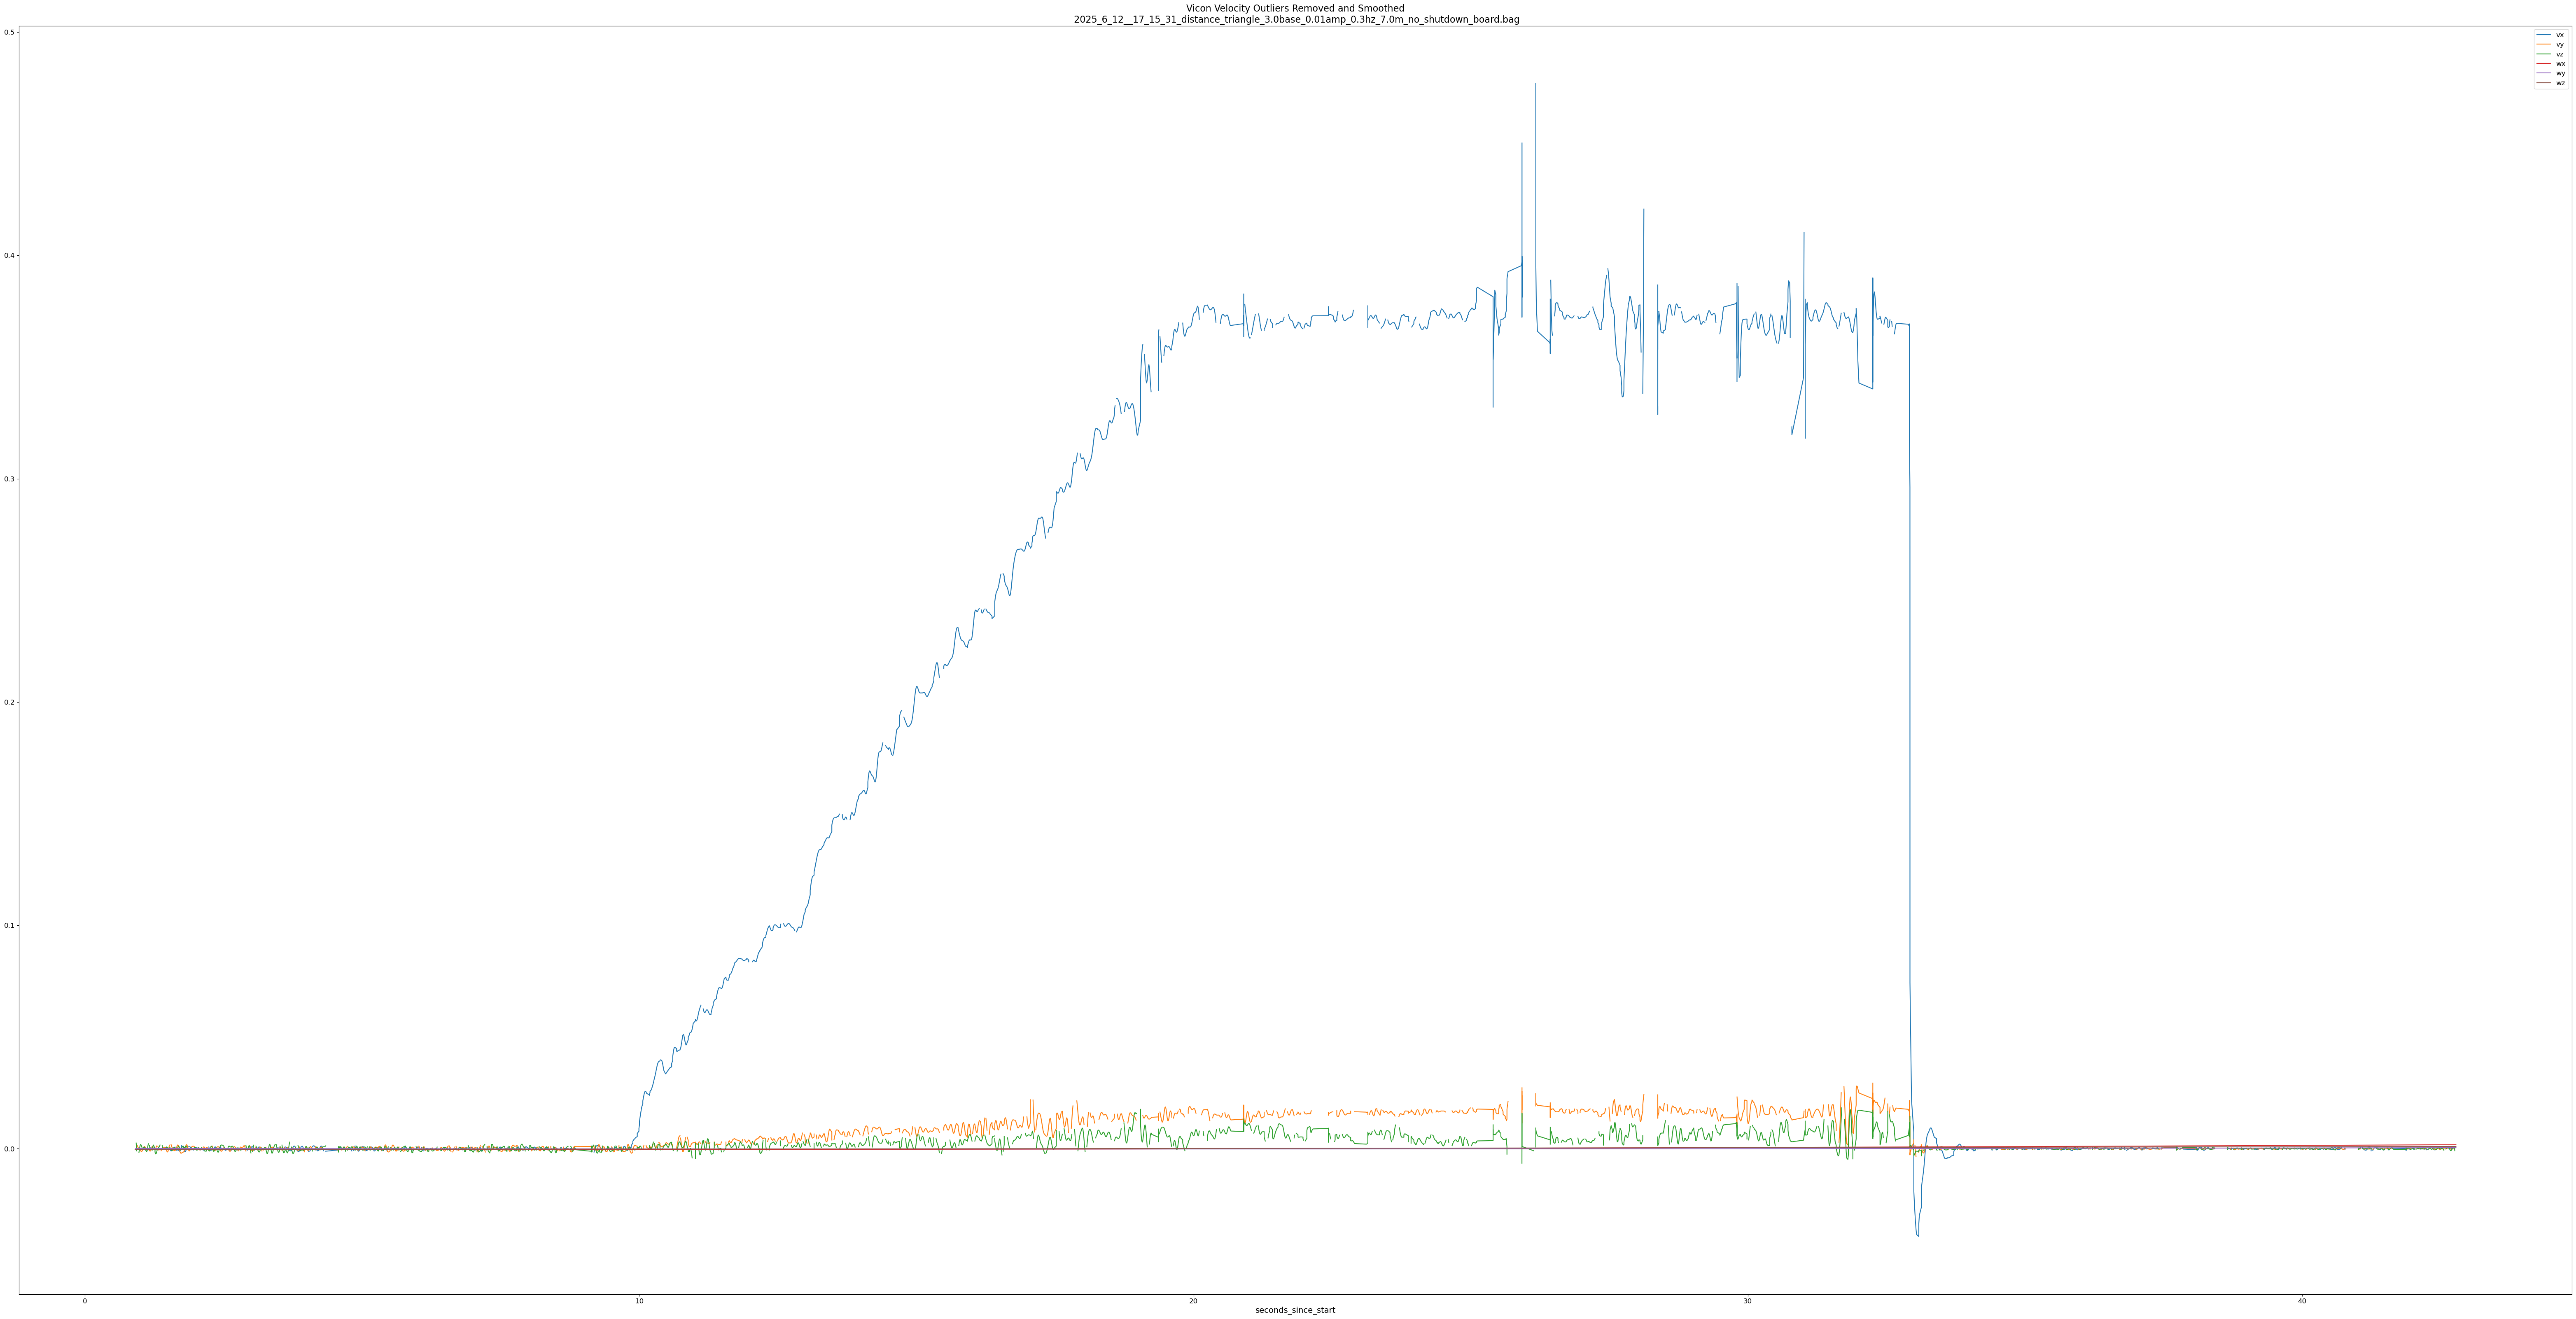

In [111]:
from rb_analysis.generic_plotting import plot_twist
from rb_analysis.filtering import low_pass_filter, smooth_pose_spline, low_pass_regular
from rb_analysis.outliers_and_interp import remove_spike_diff, remove_outliers
from scipy.signal import savgol_filter

# Differentiate vicon pose. Better to use just savgol on raw pose.
#########################################################################
vicon_pose_outliers_removed = cleaned_data["vicon_pose_outliers_removed"]
# print(vicon_pose_outliers_removed.isna().sum())

# Try fitting a spline to pose before diff.
# vicon_pose_outliers_removed = smooth_pose_spline(vicon_pose_outliers_removed, spline_s=0.1)
# vicon_pose_outliers_removed.plot(title='Spline smoothed pose')


# Savgol diff with optional spline on twist output.
vicon_frame_marker_twist_smoothed = filtering.diff_pose_savgol(
    vicon_pose_outliers_removed,
    sg_window=11,
    sg_order=3,
    # use_sg_deriv='spline',
    # use_sg_deriv=True,
    spline_s=.5,
)
if logger.getEffectiveLevel() <= logging.DEBUG:
    vicon_frame_marker_twist_smoothed.plot()


# Smooth one last time using my savgol wrapper func for dataframes.
# vicon_frame_marker_twist_smoothed = low_pass_filter(vicon_frame_marker_twist_smoothed, window_size=11,poly_order=3)

vicon_frame_marker_twist_smoothed = low_pass_regular(vicon_frame_marker_twist_smoothed, cutoff=10, order=3)

cleaned_data["vicon_frame_marker_twist_filtered"] = vicon_frame_marker_twist_smoothed
vx_filt = vicon_frame_marker_twist_smoothed["vx"]


if logger.getEffectiveLevel() <= logging.DEBUG:
    pd.DataFrame(vx_filt).plot(title="Using my savgol",figsize=(14,7))

    bx = cleaned_data["/vrpn_mocap/rb1/twist"]["twist.linear.x"]
    pd.DataFrame(bx).plot(title="raw Vx")


cleaned_data["vicon_frame_marker_twist_filtered"], stats= remove_outliers(vicon_frame_marker_twist_smoothed, window=33, z_thresh=2)
cleaned_data["vicon_frame_marker_twist_filtered"].plot(title=f"Vicon Velocity Outliers Removed and Smoothed\n {metadata['bag_path']}",figsize=(80
,40))

plt.gcf().savefig(f'{metadata["artifact_dir"]}/vicon_frame_marker_twist_filtered.png', dpi=200, bbox_inches="tight")

In [112]:
""" Remove outliers from vicon twist
While we're here let's remove any outliers from the velocity.
"""
# from rb_analysis.outliers_and_interp import remove_outlier_and_interp, remove_outliers
# from rb_analysis.generic_plotting import plot_twist


# def remove_vicon_twist_outliers(vicon_twist_df: pd.DataFrame) -> pd.DataFrame:
#     vicon_twist_outliers_removed, *stats = remove_outliers(vicon_twist_df, window=55, z_thresh=2)
#     print(stats)
#     return vicon_twist_outliers_removed


# vicon_frame_marker_twist_nofilt = cleaned_data["vicon_frame_marker_twist_nofilt"]
# vicon_twist_outliers_removed = remove_vicon_twist_outliers(vicon_frame_marker_twist_nofilt)
# cleaned_data["vicon_twist_outliers_removed"] = vicon_twist_outliers_removed


# plot = plot_twist(
#     vicon_twist_outliers_removed, metadata=metadata, title="Outlier Removed Vicon Frame Twist"
# )
# display(plot)
# plot = plot_twist(
#     vicon_frame_marker_twist_nofilt,
#     metadata=metadata,
#     title="No Outliers Removed Vicon Frame Twist",
# )
# display(plot)


# vicon_frame_marker_twist_filtered

" Remove outliers from vicon twist\nWhile we're here let's remove any outliers from the velocity.\n"

In [113]:
""" Now let's try a low pass on the vicon twist data.
"""
from rb_analysis.filtering import low_pass_regular
from rb_analysis.generic_plotting import plot_twist


def vicon_twist_filter(twist_df: pd.DataFrame) -> pd.DataFrame:
    vicon_twist_filtered = low_pass_regular(twist_df, cutoff=10, order=4)

    return vicon_twist_filtered


# # Remove outliers and save.
# vicon_twist_outliers_removed = cleaned_data["vicon_twist_outliers_removed"]
# vicon_frame_marker_twist_filtered = vicon_twist_filter(vicon_twist_outliers_removed)
# cleaned_data['vicon_frame_marker_twist_filtered'] = vicon_frame_marker_twist_filtered

# Try no low pass here
# cleaned_data["vicon_frame_marker_twist_filtered"] = vicon_twist_outliers_removed


# Plot filtered and unfiltered.
# plot = plot_twist(
#     cleaned_data["vicon_frame_marker_twist_filtered"],
#     metadata=metadata,
#     title="Vicon Frame Marker Twist Low Pass Filtered",
# )
# display(plot)


# plot = plot_twist(
#     vicon_twist_outliers_removed, metadata=metadata, title="Vicon Frame Marker Twist No Filtering"
# )
# display(plot)


### Filter IMU

In [114]:
""" Filter noise from IMU.
"""
from matplotlib.pyplot import subplot
from rb_analysis.filtering import low_pass_regular

imu_outliers_removed = cleaned_data['imu_outliers_removed']

imu_filtered = low_pass_regular(imu_outliers_removed,cutoff=10, order=4)
cleaned_data['imu_filtered'] = imu_filtered

if logger.getEffectiveLevel() <= logging.DEBUG:
    imu_filtered.plot(title="IMU Filtered", subplots=True,figsize=(8,8))
    imu_outliers_removed.plot(title="IMU Not Filtered", subplots=True,figsize=(8,8))

fs=124.83418898847746


### Filter Current Data

fs=194.29320068036463


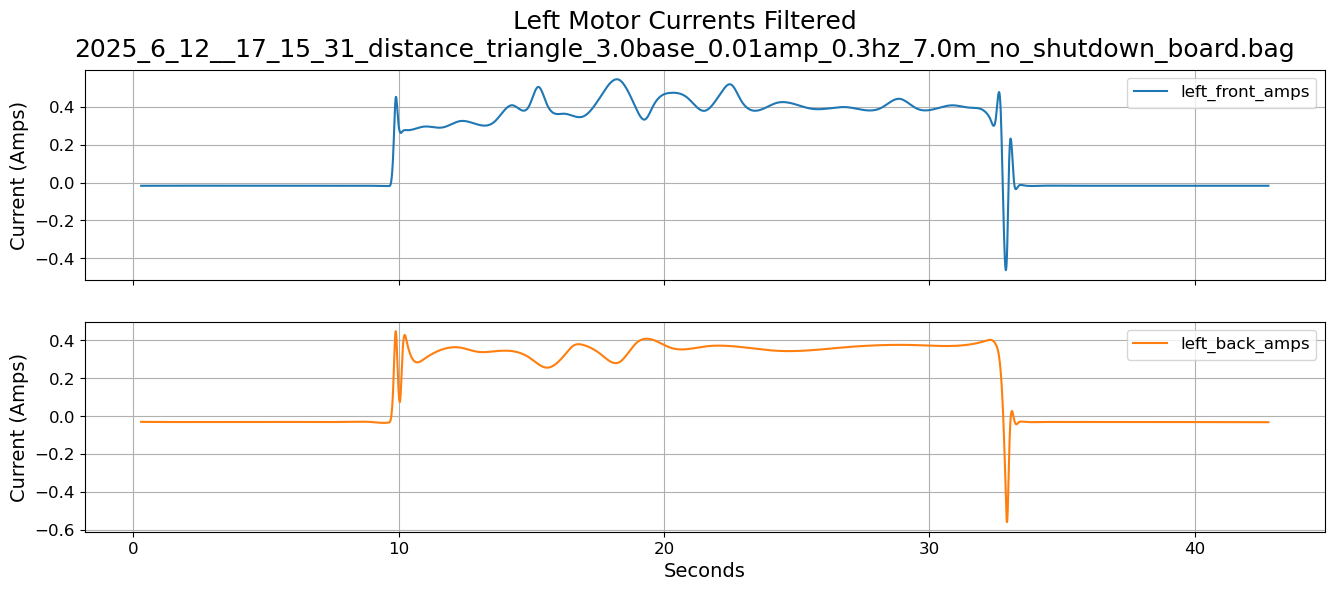

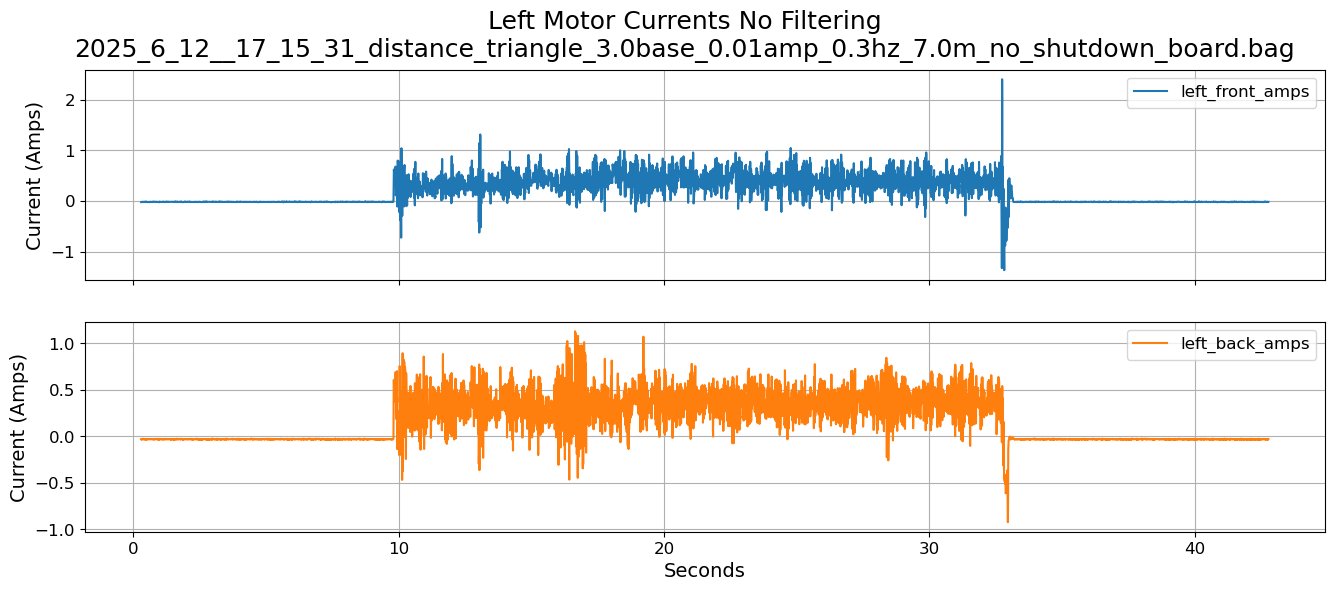

fs=178.62544682034738


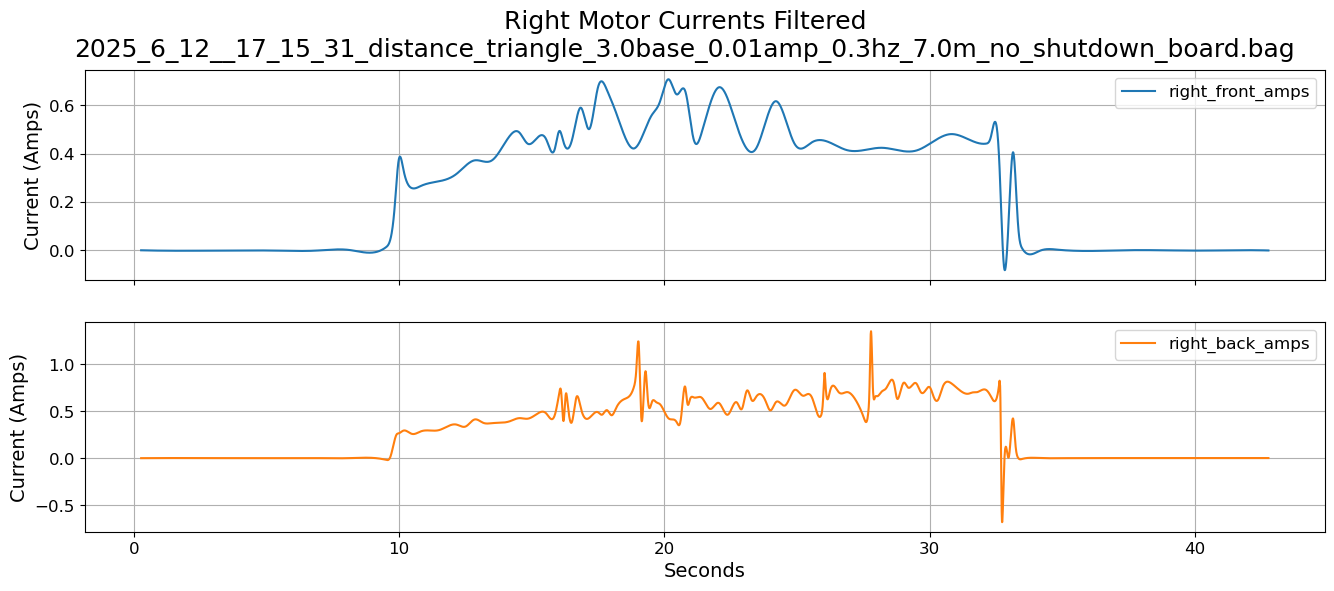

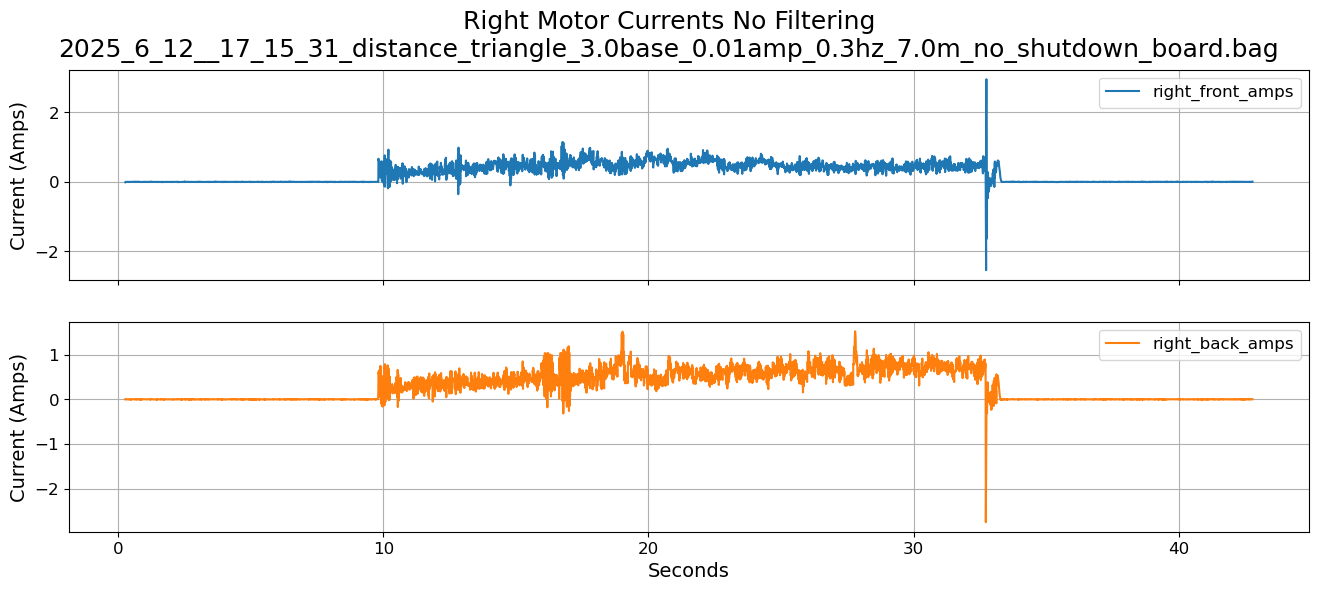

In [115]:
""" Filter motor current data to remove noise.
"""

from rb_analysis.generic_plotting import plot_currents
from rb_analysis.filtering import spline_smooth

# Filter right currents.
left_currents = cleaned_data["left_motor_currents_outliers_removed"]
left_currents = left_currents.sort_index()
# left_currents_filtered = filtering.low_pass_filter(
#     left_currents,
#     window_size=33,
#     poly_order=3,
# )
left_currents_filtered = filtering.low_pass_regular(left_currents,cutoff=10, order=4)
left_currents_filtered = spline_smooth(left_currents_filtered, s=12.5)

cleaned_data["left_motor_currents_filtered"] = left_currents_filtered

# Plot Before and after.
plot = plot_currents(
    left_currents_filtered, metadata=metadata, title="Left Motor Currents Filtered"
)
# plt.gcf().savefig(fname=f'{metadata["artifact_dir"]}/left_motor_currents_filtered.png', dpi=200, bbox_inches="tight")



display(plot)
plot = plot_currents(
    left_currents, metadata=metadata, title="Left Motor Currents No Filtering"
)
display(plot)




# And right currents
################################################3
right_motor_currents = cleaned_data["right_motor_currents_outliers_removed"]
right_motor_currents = right_motor_currents.sort_index()

# right_motor_currents_filtered = filtering.low_pass_filter(
#     right_motor_currents,
#     window_size=33,
#     poly_order=3,
# )
right_motor_currents_filtered = filtering.low_pass_regular(right_motor_currents,cutoff=10, order=4)
right_motor_currents_filtered = spline_smooth(right_motor_currents_filtered, s=12.5)


cleaned_data["right_motor_currents_filtered"] = right_motor_currents_filtered

# Plot and save right currents.
plot = plot_currents(
    right_motor_currents_filtered, metadata=metadata, title="Right Motor Currents Filtered",
)
# plt.gcf().savefig(fname=f'{metadata["artifact_dir"]}/right_motor_currents_filtered.png', dpi=200, bbox_inches="tight")
display(plot)



plot = plot_currents(
    right_motor_currents, metadata=metadata, title="Right Motor Currents No Filtering"
)
display(plot)


### Filter Encoder Data

fs=27.77877935709973


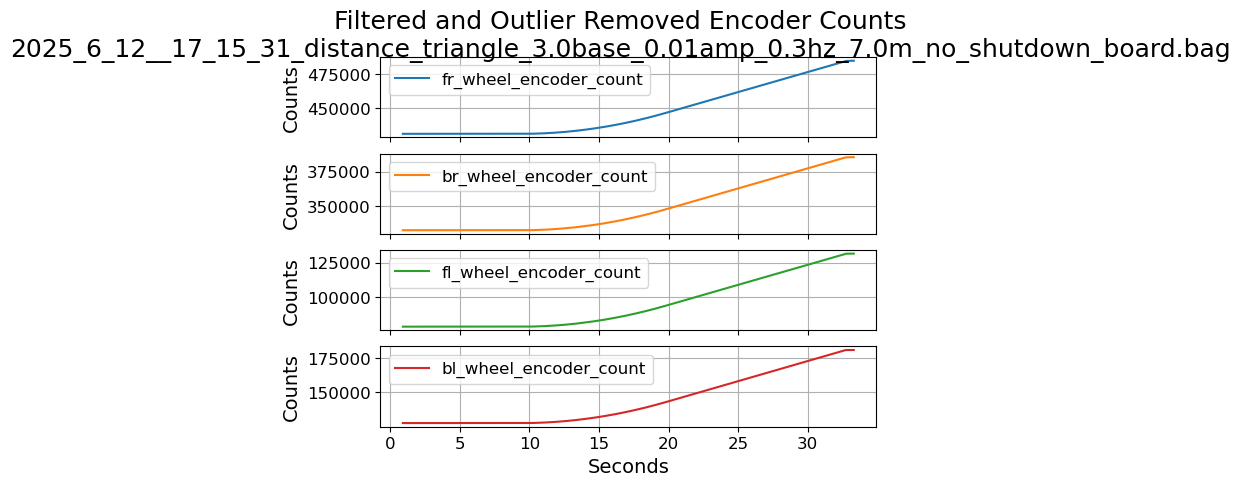

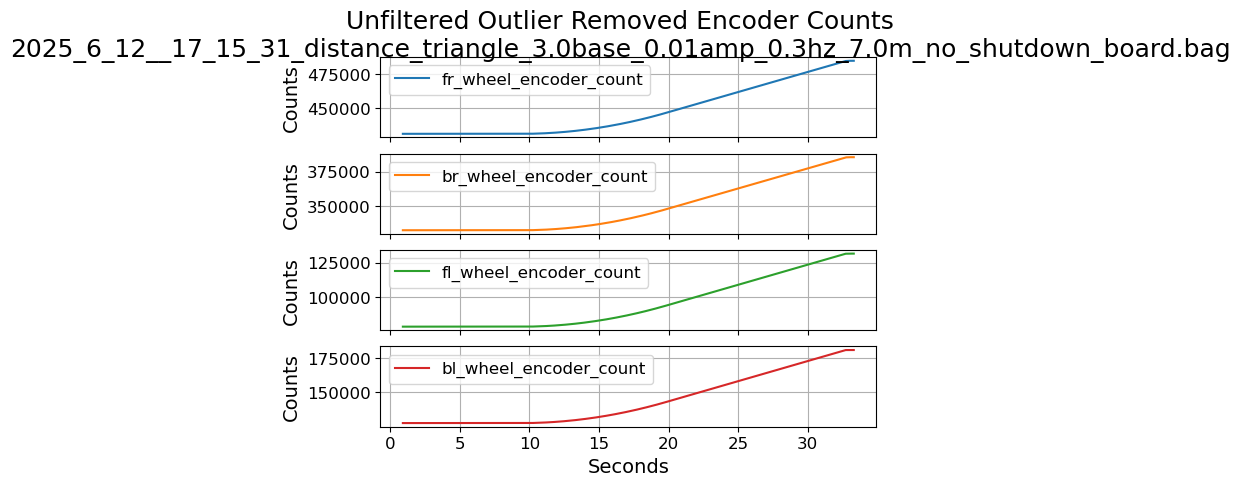

In [116]:
""" Filter encoder data.
"""

from rb_analysis.generic_plotting import plot_encoder_counts

encoder_data = cleaned_data["encoder_counts_outliers_removed"]

# encoder_filtered = filtering.low_pass_filter(encoder_data, window_size=11, poly_order=3)
# Try normal low pass filter.
encoder_filtered = filtering.low_pass_regular(encoder_data, cutoff=10, order=4)

cleaned_data["encoder_filtered"] = encoder_filtered

plot = plot_encoder_counts(
    cleaned_data["encoder_filtered"],
    metadata,
    title="Filtered and Outlier Removed Encoder Counts",
)
display(plot)


plot_before = plot_encoder_counts(
    cleaned_data["encoder_counts_outliers_removed"],
    metadata,
    title="Unfiltered Outlier Removed Encoder Counts",
    save=False,
)
display(plot_before)



# Fuse Data
Make a dirty complementary filter for the vicon linear vel and IMU linear acceleration.

In [117]:
# from rb_analysis.filtering import diff_pose, diff_pose_savgol, low_pass_filter, low_pass_regular

# # 0) Build raw velocity series
# pos_x = cleaned_data["vicon_pose_outliers_removed"]
# vel_x = diff_pose_savgol(pos_x, sg_window=5, sg_order=3)
# vel_x = pd.DataFrame(vel_x["vx"], index=pos_x.index)

# # See what accelerations we're losing (approx).
# # 1) pick your cutoff
# cutoff = 10.0         # Hz

# # 2) compute the RMS (or peak) of your raw velocity
# v_std  = vel_x["vx"].std()            # σ of velocity
# # or use v_peak = vel_x["vx"].abs().max()

# # 3) angular frequency
# omega = 2 * np.pi * cutoff            # rad/s

# # 4) equivalent acceleration amplitude for a sinusoid: a = ω·v
# a_equiv = omega * v_std

# print(f"Velocity σ = {v_std:.3f} m/s")
# print(f"Equivalent accel amplitude @ {cutoff} Hz ≃ {a_equiv:.3f} m/s²")


In [118]:
# import numpy as np
# import matplotlib.pyplot as plt
# from scipy.signal import welch, butter, filtfilt
# from rb_analysis.filtering import diff_pose, diff_pose_savgol, low_pass_filter, low_pass_regular

# """
# Look at spectral power loss in more detail. Should do this for all filtered data.
# """

# vicon_twist_filtered = cleaned_data["vicon_twist_filtered"]
# vicon_twist_outliers_removed = cleaned_data['vicon_twist_outliers_removed']
# # 1) Sampling setup
# t        = vicon_twist_outliers_removed.index.to_numpy(dtype=float)
# dt       = np.median(np.diff(t))
# fs       = 1.0 / dt
# nyq      = fs / 2.0

# # 2) PSD of raw velocity
# f_raw, Pxx_raw = welch(vicon_twist_outliers_removed["vx"], fs=fs, nperseg=1024)
# f_lp, Pxx_lp = welch(vicon_twist_filtered, fs=fs, nperseg=1024)


# # # 3) Design & apply Butterworth low-pass @ 2 Hz
# # cutoff = 2.0
# # b, a   = butter(4, cutoff/nyq, btype="low")
# # vx_lp  = filtfilt(b, a, vel_x["vx"].to_numpy())

# # # 4) PSD of filtered velocity
# # f_lp, Pxx_lp = welch(vx_lp, fs=fs, nperseg=1024)

# # 5) Compute band powers
# passband = f_raw <= cutoff
# stopband = f_raw >= cutoff

# power_raw_pass   = np.trapz(Pxx_raw[passband], f_raw[passband])
# power_raw_stop   = np.trapz(Pxx_raw[stopband], f_raw[stopband])
# power_filt_pass  = np.trapz(Pxx_lp[passband], f_lp[passband])
# power_filt_stop  = np.trapz(Pxx_lp[stopband], f_lp[stopband])

# # 6) Time‐domain variances
# std_raw = np.std(vicon_twist_outliers_removed["vx"])
# std_lp  = np.std(vicon_twist_filtered)

# # 7) Print stats
# print(f"--- PSD Band Powers ---")
# print(f"Raw power ≤{cutoff} Hz:     {power_raw_pass:.3e}")
# print(f"Raw power ≥{cutoff} Hz:     {power_raw_stop:.3e}")
# print(f"Filt power ≤{cutoff} Hz:    {power_filt_pass:.3e}")
# print(f"Filt power ≥{cutoff} Hz:    {power_filt_stop:.3e}")
# print(f"Passband retention:        {100*power_filt_pass/power_raw_pass:.1f}%")
# print(f"Stopband attenuation:      {100*(1 - power_filt_stop/power_raw_stop):.1f}%\n")

# print(f"--- Time‐Domain Noise Reduction ---")
# print(f"Raw σ:                     {std_raw:.3e}")
# print(f"Filtered σ:                {std_lp:.3e}")
# print(f"Std reduction:             {100*(1 - std_lp/std_raw):.1f}%\n")

# # 8) Plot PSDs
# plt.figure(figsize=(8,4))
# plt.semilogy(f_raw, Pxx_raw, label="Raw vx PSD")
# plt.semilogy(f_lp,  Pxx_lp,  label=f"LP @ {cutoff} Hz PSD")
# plt.axvline(cutoff, color="k", linestyle="--", alpha=0.5)
# plt.xlabel("Frequency (Hz)")
# plt.ylabel("PSD")
# plt.title("Velocity PSD: Before vs. After Low-Pass")
# plt.legend()
# plt.grid(True)
# plt.show()



# vicon_twist_outliers_removed.plot(title="vicon_twist_outliers_removed")
# pd.DataFrame(vicon_twist_filtered).plot(title="Lowpass vicon_twist_outliers_removed")

In [119]:
# # Try a quick and dirty complementary filter with union‐reindex‐interpolate alignment
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# from rb_analysis.filtering import diff_pose, diff_pose_savgol, low_pass_filter, low_pass_regular
# from scipy.signal import butter, filtfilt

# # Linear vel.
# vicon_pose_outliers_removed = cleaned_data["vicon_pose_outliers_removed"]
# # simple_vicon_vel_x = pd.DataFrame(diff_pose(vicon_pose_outliers_removed)["vx"])
# # vel_x = diff_pose_savgol(vicon_pose_outliers_removed, sg_window=11, sg_order=3)
# # vel_x = pd.DataFrame(vel_x['vx'])
# # vel_x = low_pass_regular(vel_x, cutoff=10 )
# vel_x = pd.DataFrame(cleaned_data['vicon_frame_marker_twist_filtered']['vx'])

# # Linear accel.
# # x_accel = pd.DataFrame(cleaned_data['imu_outliers_removed'])
# x_accel = pd.DataFrame(cleaned_data['imu_filtered']['linear_acceleration.x'])
# # imu_outlier_removed = outliers_and_interp.remove_outlier_and_interp(x_accel,window=11,z_thresh=5)
# # x_accel = filtering.low_pass_filter(imu_outlier_removed,window_size=11,poly_order=3)

# x_accel.plot(title="x_accel")
# vel_x.plot(title="vel_x")

# # 1) Align both series to the velocity timestamps
# master_idx = vel_x.index
# subset = {
#     "v_pos":   vel_x,
#     "x_accel": x_accel
# }

# display(subset['x_accel'])
# display(subset['v_pos'])

# aligned = {}
# for name, df in subset.items():
#     df_num    = df.apply(pd.to_numeric, errors="coerce").sort_index()
#     idx_union = df_num.index.union(master_idx)
#     df_union  = df_num.reindex(idx_union)
#     df_interp = df_union.interpolate(method="index")
#     # display(df_interp)
#     aligned[name] = df_interp.loc[master_idx]
# # display(aligned['v_pos'])

# # Deal with NaNs
# #####################
# # after your alignment loop, before extracting numpy arrays:
# # v_df = aligned["v_pos"].copy()
# # a_df = aligned["x_accel"].copy()

# # # fill any NaNs at the start or end
# # v_df["vx"].fillna(method="bfill", inplace=True)
# # v_df["vx"].fillna(method="ffill", inplace=True)
# # a_df.iloc[:, 0].fillna(method="bfill", inplace=True)
# # a_df.iloc[:, 0].fillna(method="ffill", inplace=True)

# # v_pos_aligned = v_df["vx"].to_numpy()
# # a_aligned     = a_df.iloc[:, 0].to_numpy()
# ############
# aligned_df = pd.concat([
#     aligned["v_pos"]["vx"].rename("v_pos"),
#     aligned["x_accel"].iloc[:, 0].rename("a_meas")
# ], axis=1)

# aligned_df = aligned_df.dropna()

# # 2) Extract the two aligned, NaN-free arrays
# master_idx2   = aligned_df.index
# v_pos_aligned = aligned_df["v_pos"].to_numpy()
# a_aligned     = aligned_df["a_meas"].to_numpy()

# # 3) Compute dt on the new, shorter index
# t2 = master_idx2.to_numpy(dtype=float)
# dt = np.median(np.diff(t2))


# # v_pos_aligned = aligned["v_pos"]["vx"].to_numpy()
# # a_aligned     = aligned["x_accel"]['linear_acceleration.x'].to_numpy()


# # 2) Compute dt
# # t  = master_idx.to_numpy(dtype=float)
# # dt = np.median(np.diff(t))

# if np.isnan(v_pos_aligned[0]):
#     v_pos_aligned[0] = a_aligned[0] * dt

# # 3) Run complementary filter
# alpha   = .90
# v_fused = np.empty_like(v_pos_aligned)
# v_fused[0] = v_pos_aligned[0]
# for i in range(1, len(v_fused)):
#     v_acc_pred  = v_fused[i-1] + a_aligned[i] * dt
#     v_fused[i]  = alpha * v_acc_pred + (1 - alpha) * v_pos_aligned[i]

# # Save the fused Twist.
# # cleaned_data['vicon_frame_marker_twist_fused']


# # 4) Pack and plot fused velocity
# fused_vel = pd.DataFrame({"v_fused": v_fused}, index=master_idx2)
# print("Length of fused_vel:", len(fused_vel))
# ax = fused_vel.plot(
#     title="Fused Velocity (Complementary Filter)",
#     xlabel="Seconds",
#     ylabel="Velocity (m/s)",
#     legend=False
# )
# plt.show()


In [120]:
# # Try with a full twist.
# import numpy as np
# import pandas as pd


# def fuse_twist(
#     vicon_twist_df: pd.DataFrame,
#     imu_df: pd.DataFrame,
#     alpha_lin: float = 0.9,
#     alpha_ang: float = 0.9,
# ) -> pd.DataFrame:
#     """
#     Fuse Vicon twist (linear+angular velocity) with IMU (acceleration+gyro) via complementary filter.
#     - Linear velocities: integrate acceleration and fuse with Vicon velocity.
#     - Angular velocities: fuse gyro rate with Vicon angular velocity.

#     Parameters
#     ----------
#     vicon_twist_df : pd.DataFrame
#         Columns ['vx','vy','vz','wx','wy','wz'], indexed by time (sec).
#     imu_df : pd.DataFrame
#         Columns ['ax','ay','az','gx','gy','gz'], acceleration & gyro,
#         same units, indexed by time.
#     alpha_lin : float
#         CF weight on IMU-derived linear velocity (0–1).
#     alpha_ang : float
#         CF weight on IMU gyro (0–1).

#     Returns
#     -------
#     pd.DataFrame
#         Fused twist with same index & columns ['vx','vy','vz','wx','wy','wz'].
#     """
#     # 1) Align on vicon index
#     master_idx = vicon_twist_df.index
#     imu_num = imu_df.apply(pd.to_numeric, errors="coerce").sort_index()
#     idx_union = imu_num.index.union(master_idx)
#     imu_union = imu_num.reindex(idx_union).interpolate(method="index")
#     # imu_aligned = imu_union.loc[master_idx]
#     imu_aligned = imu_union.interpolate(method="index") \
#                          .fillna(method="bfill") \
#                          .fillna(method="ffill") \
#                          .loc[master_idx]

#     # 2) Extract arrays
#     # linear accel -> axes ax,ay,az
#     a = imu_aligned[["ax", "ay", "az"]].to_numpy()
#     # gyro rates -> gx,gy,gz
#     w_imu = imu_aligned[["gx", "gy", "gz"]].to_numpy()
#     # vicon velocities
#     v_vicon = vicon_twist_df[["vx", "vy", "vz"]].to_numpy()
#     w_vicon = vicon_twist_df[["wx", "wy", "wz"]].to_numpy()

#     # 3) time step
#     t = master_idx.to_numpy(dtype=float)
#     dt = np.median(np.diff(t))

#     # 3) Inside fuse_twist, after aligning and before integrating:
#     print(imu_aligned[["ax", "ay", "az"]].head())
#     print(vicon_twist_df[["vx", "vy", "vz"]].head())

#     # 4) integrate accel for velocity predictions
#     v_pred = np.zeros_like(v_vicon)
#     v_pred[0] = v_vicon[0]  # init from vicon
#     for i in range(1, len(v_pred)):
#         v_pred[i] = v_pred[i - 1] + a[i] * dt

#     v_pred = np.zeros_like(a)
#     v_pred[0] = v_vicon[0]
#     for i in range(1, len(a)):
#         v_pred[i] = v_pred[i-1] + 0.5*(a[i-1] + a[i]) * dt

#     # 5) complementary fuse linear
#     v_fused = alpha_lin * v_pred + (1 - alpha_lin) * v_vicon

#     # 6) complementary fuse angular
#     w_fused = alpha_ang * w_imu + (1 - alpha_ang) * w_vicon

#     print("\nv_pred head:", v_pred[:5])
#     print("v_fused head:", v_fused[:5])

#     # 7) assemble DataFrame
#     fused = np.hstack([v_fused, w_fused])
#     cols = ["vx", "vy", "vz", "wx", "wy", "wz"]
#     return pd.DataFrame(fused, index=master_idx, columns=cols)


# # Example usage:
# vicon = cleaned_data["vicon_frame_marker_twist_filtered"][["vx", "vy", "vz", "wx", "wy", "wz"]]
# imu = cleaned_data["imu_unbiased"][
#     [
#         "linear_acceleration.x",
#         "linear_acceleration.y",
#         "linear_acceleration.z",
#         "angular_velocity.x",
#         "angular_velocity.y",
#         "angular_velocity.z",
#     ]
# ]
# imu.columns = ["ax", "ay", "az", "gx", "gy", "gz"]


# # 1) Inspect Vicon linear velocities
# print("Vicon 'vx','vy','vz' stats:")
# print(vicon[["vx", "vy", "vz"]].describe())

# # 2) Inspect IMU accel
# print("\nIMU 'ax','ay','az' stats before fusion:")
# print(imu[["ax", "ay", "az"]].describe())

# # 3) Inside fuse_twist, after aligning and before integrating:
# #    print(imu_aligned[['ax','ay','az']].head())
# #    print(vicon_twist_df[['vx','vy','vz']].head())


# fused_twist = fuse_twist(vicon, imu, alpha_lin=0.7, alpha_ang=0.9)
# fused_twist.plot(subplots=True, figsize=(10, 10))


In [121]:
# from curses import meta
# import numpy as np
# import pandas as pd
# from scipy.interpolate import interp1d
# import matplotlib.pyplot as plt

# def fuse_twist_upsampled(
#     vicon_twist_df: pd.DataFrame,
#     imu_df: pd.DataFrame,
#     alpha_lin: float = 0.9,
#     alpha_ang: float = 0.9
# ) -> pd.DataFrame:
#     """
#     Fuse Vicon twist with IMU by upsampling IMU accel to its native rate,
#     integrating with trapezoidal rule, then downsampling to Vicon time for
#     complementary filtering. Includes extrapolation to cover mismatched time ranges.
#     """
#     # 1) Prepare indices
#     vidx = vicon_twist_df.index.to_numpy(dtype=float)
#     iidx = imu_df.index.to_numpy(dtype=float)
#     dt_imu = np.median(np.diff(iidx))
#     fs_imu = 1.0 / dt_imu
#     print(f"IMU sampling dt: {dt_imu:.4f}s (~{fs_imu:.1f}Hz), Vicon starts at {vidx[0]:.3f}s, IMU starts at {iidx[0]:.3f}s")

#     # 2) Interpolate IMU accel onto uniform grid
#     t_fine = np.arange(min(iidx[0], vidx[0]), max(iidx[-1], vidx[-1]), dt_imu)
#     a_raw = imu_df[['ax','ay','az']].to_numpy()
#     accel_interp = interp1d(iidx, a_raw, axis=0, kind='linear', 
#                             bounds_error=False, fill_value='extrapolate')
#     a_fine = accel_interp(t_fine)
#     print("a_fine head:", a_fine[:5])

#     # 3) Integrate accel via trapezoidal on fine grid
#     v_pred_fine = np.zeros_like(a_fine)
#     # initialize from Vicon at first fine time
#     init_v = np.interp(t_fine[0], vidx, vicon_twist_df['vx'])
#     v_pred_fine[0] = init_v
#     for i in range(1, len(t_fine)):
#         v_pred_fine[i] = v_pred_fine[i-1] + 0.5*(a_fine[i-1] + a_fine[i])*dt_imu
#     print("v_pred_fine head:", v_pred_fine[:5])

#     # 4) Downsample to Vicon times with extrapolation
#     pred_interp = interp1d(t_fine, v_pred_fine, axis=0, kind='linear',
#                            bounds_error=False, fill_value='extrapolate')
#     v_pred = pred_interp(vidx)
#     print("v_pred at vicon head:", v_pred[:5])

#     # 5) Extract Vicon and IMU gyro (extrapolate gyro similarly)
#     v_vicon = vicon_twist_df[['vx','vy','vz']].to_numpy()
#     w_vicon = vicon_twist_df[['wx','wy','wz']].to_numpy()
#     gyro_interp = interp1d(iidx, imu_df[['gx','gy','gz']].to_numpy(),
#                            axis=0, kind='linear',
#                            bounds_error=False, fill_value='extrapolate')
#     w_imu   = gyro_interp(vidx)

#     # 6) Complementary filter
#     v_fused = alpha_lin*v_pred + (1-alpha_lin)*v_vicon
#     w_fused = alpha_ang*w_imu + (1-alpha_ang)*w_vicon

#     # 7) Assemble
#     fused = np.hstack([v_fused, w_fused])
#     cols = ['vx','vy','vz','wx','wy','wz']
#     return pd.DataFrame(fused, index=vicon_twist_df.index, columns=cols)

# # Example usage (adjust variables as needed):
# # fused = fuse_twist_upsampled(vicon, imu, alpha_lin=0.7, alpha_ang=0.9)
# # fused.plot(subplots=True, figsize=(10,10), title='Fused Twist Upsampled')


# # Example usage
# vicon = cleaned_data['vicon_frame_marker_twist_filtered'][['vx','vy','vz','wx','wy','wz']]
# imu = cleaned_data['imu_unbiased'][[
#     'linear_acceleration.x','linear_acceleration.y','linear_acceleration.z',
#     'angular_velocity.x','angular_velocity.y','angular_velocity.z'
# ]].rename(columns={
#     'linear_acceleration.x':'ax','linear_acceleration.y':'ay','linear_acceleration.z':'az',
#     'angular_velocity.x':'gx','angular_velocity.y':'gy','angular_velocity.z':'gz'
# })

# fused_twist = fuse_twist_upsampled(vicon, imu, alpha_lin=0.7, alpha_ang=0.9)
# fused_twist.plot(subplots=True, figsize=(10,10), title='Fused Twist Upsampled')

# plot_twist(vicon, metadata=metadata, title="Unfused")


In [122]:
# import numpy as np
# import pandas as pd
# from scipy.interpolate import interp1d
# import matplotlib.pyplot as plt


# def fuse_twist_upsampled(
#     vicon_twist_df: pd.DataFrame,
#     imu_df: pd.DataFrame,
#     alpha_lin: float = 0.9,
#     alpha_ang: float = 0.9,
#     bias_window_sec: float = 1.0
# ) -> pd.DataFrame:
#     """
#     Fuse Vicon twist with IMU by:
#     1) static bias removal on IMU accel
#     2) upsampling accel to its native rate
#     3) trapezoidal integration
#     4) downsampling to Vicon times
#     5) complementary filter on linear & angular velocities
#     """
#     # 1) Time axes
#     vidx = vicon_twist_df.index.to_numpy(dtype=float)
#     iidx = imu_df.index.to_numpy(dtype=float)
#     dt_imu = np.median(np.diff(iidx))
#     fs_imu = 1.0 / dt_imu
#     print(f"IMU dt: {dt_imu:.4f}s (~{fs_imu:.1f}Hz)")

#     # 2) Static bias estimation (first bias_window_sec)
#     N_bias = int(bias_window_sec / dt_imu)
#     bias_vec = imu_df[['ax','ay','az']].iloc[:N_bias].mean().to_numpy()
#     print("Estimated accel bias (ax,ay,az):", bias_vec)
#     a_raw = imu_df[['ax','ay','az']].to_numpy() - bias_vec

#     # 3) Upsample accel
#     t_start = iidx[0]
#     t_end   = iidx[-1]
#     t_fine  = np.arange(t_start, t_end, dt_imu)
#     accel_interp = interp1d(
#         iidx, a_raw, axis=0, kind='linear',
#         bounds_error=False, fill_value='extrapolate'
#     )
#     a_fine = accel_interp(t_fine)
#     print("a_fine head:", a_fine[:5])

#     # 4) Trapezoidal integration, init from Vicon first sample
#     v_pred_fine = np.zeros_like(a_fine)
#     v0 = vicon_twist_df[['vx','vy','vz']].iloc[0].to_numpy()
#     v_pred_fine[0] = v0
#     for i in range(1, len(t_fine)):
#         v_pred_fine[i] = v_pred_fine[i-1] + 0.5*(a_fine[i-1] + a_fine[i])*dt_imu
#     print("v_pred_fine head:", v_pred_fine[:5])

#     # 5) Downsample to Vicon times
#     pred_interp = interp1d(
#         t_fine, v_pred_fine, axis=0, kind='linear',
#         bounds_error=False, fill_value='extrapolate'
#     )
#     v_pred = pred_interp(vidx)
#     print("v_pred at vicon head:", v_pred[:5])

#     # 6) Gyro alignment
#     gyro_interp = interp1d(
#         iidx, imu_df[['gx','gy','gz']].to_numpy(),
#         axis=0, kind='linear',
#         bounds_error=False, fill_value='extrapolate'
#     )
#     w_imu = gyro_interp(vidx)

#     # 7) Vicon arrays
#     v_vicon = vicon_twist_df[['vx','vy','vz']].to_numpy()
#     w_vicon = vicon_twist_df[['wx','wy','wz']].to_numpy()

#     # 8) Complementary fusion
#     v_fused = alpha_lin*v_pred + (1-alpha_lin)*v_vicon
#     w_fused = alpha_ang*w_imu  + (1-alpha_ang)*w_vicon

#     # 9) Assemble output
#     fused = np.hstack([v_fused, w_fused])
#     cols  = ['vx','vy','vz','wx','wy','wz']
#     return pd.DataFrame(fused, index=vicon_twist_df.index, columns=cols)

# # Example usage
# vicon = cleaned_data['vicon_frame_marker_twist_filtered'][['vx','vy','vz','wx','wy','wz']]
# imu = cleaned_data['imu_unbiased'][[
#     'linear_acceleration.x','linear_acceleration.y','linear_acceleration.z',
#     'angular_velocity.x','angular_velocity.y','angular_velocity.z'
# ]].rename(columns={
#     'linear_acceleration.x':'ax','linear_acceleration.y':'ay','linear_acceleration.z':'az',
#     'angular_velocity.x':'gx','angular_velocity.y':'gy','angular_velocity.z':'gz'
# })

# fused_twist = fuse_twist_upsampled(vicon, imu, alpha_lin=0.7, alpha_ang=0.9, bias_window_sec=1.0)
# fused_twist.plot(subplots=True, figsize=(10,10), title='Fused Twist Upsampled')
# plot_twist(vicon, metadata=metadata, title="Unfused Filtered Vicon Twist")

# Derived Data
We need to create our own TwistStamped data from the Vicon provided PoseStamped. We should filter the pose data *before* we make our Twist data. We get the Twist of the vicon_marker in the vicon (inertial frame). Then we get it's local frame twist. Then we displace that twist to the contact patches of the robot since they are all part of the same rigid body.

## Patch Poses and Patch Twists from Vicon Data
Transform the `vicon_marker` PoseStamped ${}^{V}p_{M}(t)$ to get 4 PoseStamped for each contact patch.

We then differentiate the vicon-frame marker Pose to get the vicon-frame marker Twist ${}^V\xi_M (t)$

Then transform vicon-frame marker Twist to it's own local-frame so we have ${}^M\xi_M (t)$. 

<!-- Finally do a *displacement transform* on the marker-frame marker twist ${}^M\xi_M (t)$ to get the four local-frame contact patch twists ${}^{FL}\xi_{FL} (t)$ -->

Get Vicon-frame Pose of 

### Transform Vicon-frame marker Pose to Vicon-frame Patch Poses.
Transform the `vicon_marker` PoseStamped ${}^{V}T_{M}(t)$ to get 4 PoseStamped for each contact patch.

$$
{}^{V}T_{M}(t)
= \begin{bmatrix}
{}^{V}R_{M}(t) & {}^{V}p_{M}(t)\\[4pt]
0 & 1
\end{bmatrix}
$$

For example the FL patch PoseStamped:
$$
{}^{V}T_\text{FL\_patch}(t)
= \begin{bmatrix}
{}^{V}R_\text{FL\_patch}(t) & {}^{V}p_\text{FL\_patch}(t)\\[4pt]
0 & 1
\end{bmatrix}
$$

In [123]:
import PyKDL as kdl

"""
Transform the vicon-frame marker pose to make the four new xx_patch poses.
"""


# Transform this into four vicon_frame_XX_patch pose dataframes.
# vicon_frame_marker_pose = cleaned_data["vicon_frame_marker_pose_filtered"]
# patch_xforms:pd.DataFrame = cleaned_data["patch_xforms"]

def create_kdl_xforms(patch_xforms: pd.DataFrame ,vicon_frame_marker_pose:pd.DataFrame)->dict:
    """Create KDL transforms from a dataframe of pose data.

    Returns:
        dict: patch_name:df
    """
    vicon_frame_patch_poses = {}

    for patch_name in patch_xforms.columns:
        static_frame = patch_xforms[patch_name].iloc[0]  # existing KDL Frame

        def to_patch_pose(row):
            # build the marker frame in Vicon coords
            mark_F = kdl.Frame(
                kdl.Rotation.Quaternion(row["qx"], row["qy"], row["qz"], row["qw"]),
                kdl.Vector(row["x"], row["y"], row["z"]),
            )
            # compose with your existing patch frame
            patch_F = mark_F * static_frame

            t = patch_F.p
            qx, qy, qz, qw = patch_F.M.GetQuaternion()
            return pd.Series(
                {
                    "x": t[0],
                    "y": t[1],
                    "z": t[2],
                    "qx": qx,
                    "qy": qy,
                    "qz": qz,
                    "qw": qw,
                }
            )

        df_patch = vicon_frame_marker_pose.apply(to_patch_pose, axis=1)
        vicon_frame_patch_poses[patch_name] = df_patch
    return vicon_frame_patch_poses


# Get transforms and the pose to be transformed.
patch_xforms = cleaned_data["patch_xforms"]
vicon_frame_marker_pose = cleaned_data["vicon_frame_marker_pose_filtered"]




# Create the vicon_frame patch poses.
vicon_frame_patch_poses = create_kdl_xforms(patch_xforms, vicon_frame_marker_pose)


# Combine all 5 poses into one dictionary
all_poses = dict(vicon_frame_patch_poses)
all_poses["marker"] = cleaned_data["vicon_frame_marker_pose_filtered"]

# And shove it in the global dict.
for name, df in all_poses.items():
    print(f"{name } NaNs: ",df.isna().sum())

    print(f"vicon_frame_{name}_pose")
    cleaned_data[f"vicon_frame_{name}_pose"] = df

# Look at the trajectory of the vicon_marker.
# ani = tf_plot_utils.ViconPoseAnimator(
#     all_poses,
#     dpi=60,
#     azim=0,
#     interval=30,
#     elev=100,
#     pose_cols=["x", "y", "z", "qx", "qy", "qz", "qw"],
# )
# ani.run()


bl_patch NaNs:  x     0
y     0
z     0
qx    0
qy    0
qz    0
qw    0
dtype: int64
vicon_frame_bl_patch_pose
br_patch NaNs:  x     0
y     0
z     0
qx    0
qy    0
qz    0
qw    0
dtype: int64
vicon_frame_br_patch_pose
fl_patch NaNs:  x     0
y     0
z     0
qx    0
qy    0
qz    0
qw    0
dtype: int64
vicon_frame_fl_patch_pose
fr_patch NaNs:  x     0
y     0
z     0
qx    0
qy    0
qz    0
qw    0
dtype: int64
vicon_frame_fr_patch_pose
marker NaNs:  x     0
y     0
z     0
qx    0
qy    0
qz    0
qw    0
dtype: int64
vicon_frame_marker_pose


### Get Vicon-frame Twist of Marker ${}^V\xi_M$
Using Lynch's "*Modern Robotics*" here. I'm pretty sure I have not screwed (hah) this up.

For the vicon frame $\{V\}$ and marker frame $\{M\}$ we are given the vicon-frame pose of the marker as ${}^VT_M$ which we numerically differentiate to get the vicon-frame twist ${}^V\xi_M$. From here we want to find the marker-frame (local) twist, ${}^M\xi_M$. Since we just doing a "change of basis" transformation we don't need to do the weird cross product of the distance and angular velocity we do for a "displacement transform" of a twist?

The pose of the marker is:

$$
{}^{V}T_{M}(t)
= \begin{bmatrix}
{}^{V}R_{M}(t) & {}^{V}p_{M}(t)\\[4pt]
0 & 1
\end{bmatrix}
$$

We get the vicon-frame twist of the marker:
$$
{}^{V}\xi_{M}  (t)
= \begin{bmatrix}
{}^{V}\omega_{M} (t)\\[4pt]
{}^{V}v_{M} (t)
\end{bmatrix},\quad
{}^{V}\omega_{M} (t)
=\bigl(\dot R_{VM}(t)\,R_{MV}(t)\bigr)^{\vee},
\quad
{}^{V}v_{M}(t)={}^V\dot p_{M}(t).
$$


<!-- Where the $\vee$ operator superscript is the inverse of the skew-symmetric operator. Don't quite get this one to be honest but it's something about turning cross products into regular products? I think it's just a notational convenience. I've seen $[]_\times$, $[]$, and $\hat{}$ all as notation for skew-symmetric matrices. -->


In [124]:
# from rb_analysis import transform_utils

# """
#  Pose of the body frame in the inertial (vicon) frame.
#  index column is Timestamp named "seconds_since_start".
#  sec	nanosec	frame_id	x	y	z	qx	qy	qz	qw
#  """
# # display(cleaned_data["/vrpn_mocap/rb1/pose"])

# # Get Twist of the marker in the vicon frame.
# vicon_frame_marker_twist = transform_utils.compute_vicon_twist(
#     df_pose=cleaned_data["/vrpn_mocap/rb1/pose"]
# )
# cleaned_data["vicon_frame_marker_twist"] = vicon_frame_marker_twist
# # display(body_frame_marker_twist)

# # Look the vicon-frame marker twist.
# cleaned_data["vicon_frame_marker_twist"][["vx", "vy", "vz", "wx", "wy", "wz"]].plot(
#     title="Vicon Frame Marker Twist",
#     subplots=True,
#     xlabel="Time(seconds)",
#     ylabel="m/s and RAD/s"
# )


### Calculate Vicon-frame Patch Twists
Useful to compare and check the local_frame twists.

In [125]:
# from rb_analysis.transform_utils import transform_twist_displacement_only
from rb_analysis import transform_utils

"""
This is still a *displacement* transform but we want to keep the basis in the
original vicon frame from the vicon_frame_marker_twist we are displacing. This
get's us the vicon_frame_XX_patch_twist.
"""

# Get the 4 four transforms.
patch_xforms = cleaned_data["patch_xforms"]
display(patch_xforms)
# display(cleaned_data["marker_frame_marker_twist"])

print("NaNs: ",cleaned_data["vicon_frame_marker_twist_filtered"].isna().sum())

# Don't do this...
# valid_twist = cleaned_data["vicon_frame_marker_twist_filtered"].dropna()
# valid_pose  = cleaned_data["vicon_frame_marker_pose_filtered"].loc[valid_twist.index]

for patch_name in patch_xforms.columns:
    static_frame = patch_xforms[patch_name].iloc[0]  # existing KDL Frame
    print(f"Units {patch_name}: {static_frame.p}")
    cleaned_data[f"vicon_frame_{patch_name}_twist"] = (
        transform_utils.transform_twist_displacement_only(
            df_twist=cleaned_data["vicon_frame_marker_twist_filtered"],
            df_pose=cleaned_data["vicon_frame_marker_pose_filtered"],
            static_frame=static_frame,
        )
    )

    # print("NaNs: ",cleaned_data[f"vicon_frame_{patch_name}_twist"].isna().sum())

if logger.getEffectiveLevel() <= logging.DEBUG:
    cleaned_data["vicon_frame_bl_patch_twist"]['vx'].plot()

,bl_patch,br_patch,fl_patch,fr_patch
0,"[[ 1,-2.25217e-16, 1.86257e-15;\n 2...","[[ 1,-2.21747e-16, 7.72386e-16;\n 2...","[[ 1,-7.80328e-16, 1.08542e-15;\n 7...","[[ 1,-7.80328e-16, 1.08542e-15;\n 7..."


NaNs:  vx    564
vy    808
vz    773
wx      3
wy      6
wz      0
dtype: int64
Units bl_patch: [     -0.3302,   -0.081915,   -0.133795]
[Transform] Exact timestamp matches: 4119 / 4119
[Transform] Mean Δt: 0.000000 s
[Transform] Max  Δt:  0.000000 s
Units br_patch: [     -0.3302,   -0.596265,   -0.133795]
[Transform] Exact timestamp matches: 4119 / 4119
[Transform] Mean Δt: 0.000000 s
[Transform] Max  Δt:  0.000000 s
Units fl_patch: [      0.3302,   -0.081915,   -0.133795]
[Transform] Exact timestamp matches: 4119 / 4119
[Transform] Mean Δt: 0.000000 s
[Transform] Max  Δt:  0.000000 s
Units fr_patch: [      0.3302,   -0.596265,   -0.133795]
[Transform] Exact timestamp matches: 4119 / 4119
[Transform] Mean Δt: 0.000000 s
[Transform] Max  Δt:  0.000000 s


### Calculate Marker-frame Twist of of Marker 


We organize the local-frame marker twist ${}^M\xi_M$ as the following (angular vel on top, linear vel on bottom):

$$
{}^M\xi_M(t) = \begin{bmatrix}
    {}^M\omega_M(t)\\
    {}^Mv_M(t)
\end{bmatrix}
$$

We can use the transpose of the vicon-frame marker's rotation matrix ($ \bigl(R_{VM}\bigr)^{\!\top} (t) $)to do this:

$$
{}^{M}\xi_{M}(t)
= \begin{bmatrix}
{}^{M}\omega_{M}(t)\\[4pt]
{}^{M}v_{M}(t)
\end{bmatrix},
\quad
\begin{aligned}
{}^{M}\omega_{M}(t) &= R_\text{VM}^\text{T}(t) {}^V\omega_M(t) ,\\
{}^{M}v_{M}(t)      &= R_\text{VM}^\text{T}(t) {}^{V}{v}_{M}(t).
\end{aligned}
$$

Turn into Transformation matrices and take derivative to get Twists. Then transform the vicon-frame Twist into a body-frame twist using the Rotation of the pose at each time matching the twist.


,vx,vy,vz,wx,wy,wz
seconds_since_start,,,,,,
0.904612,NaN,NaN,NaN,-0.000420,NaN,-0.000380
0.914442,NaN,NaN,NaN,-0.000420,0.000101,-0.000380
0.924445,NaN,NaN,0.002526,-0.000420,0.000101,-0.000380
0.934435,NaN,NaN,-0.000982,-0.000420,0.000101,-0.000380
0.944431,0.000165,0.001428,NaN,-0.000420,0.000100,-0.000379
...,...,...,...,...,...,...
42.734491,0.000164,0.000430,0.000993,0.001773,0.000446,0.001003
42.744468,0.000205,0.000346,0.000397,0.001774,0.000446,0.001003
42.754473,0.000301,-0.000057,-0.000890,0.001775,0.000447,0.001004


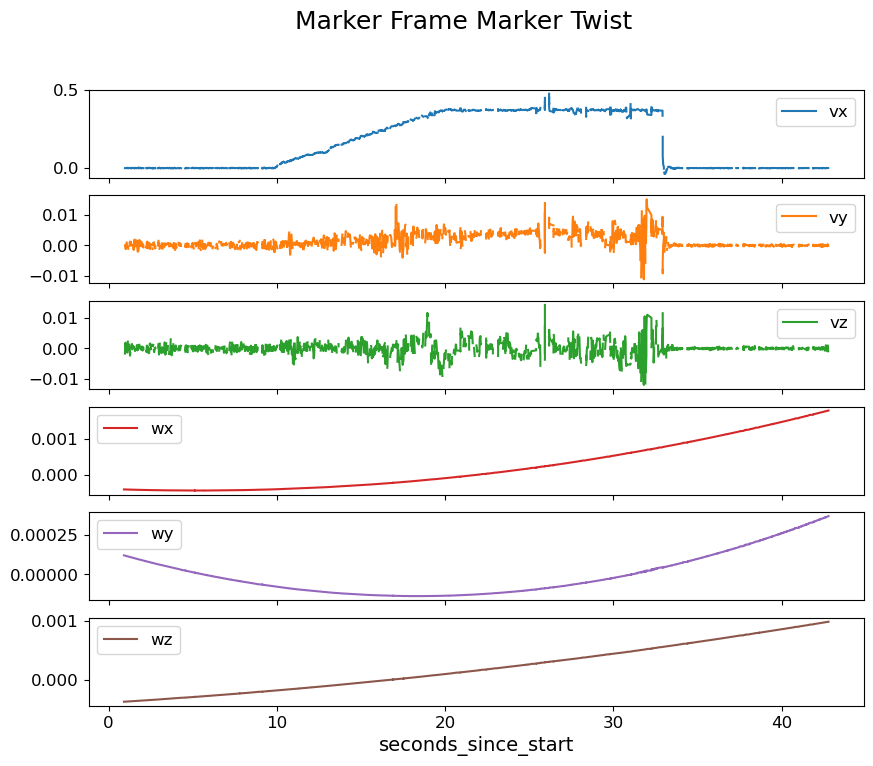

In [126]:
# Transform the vicon-frame body twist into the body-frame. Should just use rotation matrix since
# we aren't shifting anything.

vicon_frame_marker_twist_filtered = cleaned_data["vicon_frame_marker_twist_filtered"]
vicon_frame_marker_pose_filtered = cleaned_data["vicon_frame_marker_pose_filtered"]
display(vicon_frame_marker_twist_filtered)


cleaned_data["marker_frame_marker_twist"] = transform_utils.compute_body_twist(
    vicon_frame_marker_twist_filtered, vicon_frame_marker_pose_filtered
)
# display(body_frame_body_twist)

# Look the marker-frame marker twist.
cleaned_data["marker_frame_marker_twist"][["vx", "vy", "vz", "wx", "wy", "wz"]].plot(
    title="Marker Frame Marker Twist",
    subplots=True,
    figsize=(10,8)
)
plt.gcf().savefig(fname=f'{metadata["artifact_dir"]}/marker_frame_marker_twist.png', dpi=200, bbox_inches="tight")


In [127]:
from rb_analysis import tf_plot_utils
if logger.getEffectiveLevel() <= logging.DEBUG:

# Plot the marker pose and the vicon-frame marker twist and the marker-frame marker twist.
    ani = tf_plot_utils.ViconTwistAnimator(
        df_pose=cleaned_data["vicon_frame_marker_pose_filtered"],
        df_vicon_twist=cleaned_data["vicon_frame_marker_twist_filtered"],
        df_body_twist=cleaned_data["marker_frame_marker_twist"],
        interval=20,
        plot_step=20,
        twist_scale=5,
        axis_len=1,
    )

    # Generate video conditioned on logging level to save time.
    # if logger.getEffectiveLevel() <= logging.INFO:
    # ani.run()

### Get LOCAL-frame `<FL|BL|FR|BR>_patch` Twists
This is now a *displacement transform* meaning we have to account for the "record player edge" component of the new frames linear velocity. 

We have four new frames `<FL|BL|FR|BR>_patch` which are related to the marker through the transform `vicon_ball -> base_link -> <FL|BL|FR|BR>_patch`. We can use PyKDL to compute the static one step transform for us and apply that to the marker-frame marker twist.

$$
\bigl\{\,\xi_{\text{patch\_}i}\;\bigm|\;i\in\{\text{FR},\text{BR},\text{FL},\text{BL}\}\bigr\}
$$

Let's drop the back-superscript for the local-frame patch twist since it's a bit cumbersome. So 
$$
{}^{\text{patch\_}i}\xi_{\text{patch\_}i} \rightarrow \xi_{\text{patch\_}i}
$$


Lets say we are concerned with the Front-Left (FL) contact patch. We have it's local-frame twist as:

$$
\xi_{\mathrm{patch\_}i}(t) = \begin{bmatrix}
    {}^M\omega_M(t)\\
    {}^Mv_M(t)
\end{bmatrix}
$$

We can use the transpose of the vicon-frame marker's rotation matrix ($ \bigl(R_{VM}\bigr)^{\!\top} (t) $)to do this:

$$
{}^{M}\xi_{M}(t)
= \begin{bmatrix}
{}^{M}\omega_{M}(t)\\[4pt]
{}^{M}v_{M}(t)
\end{bmatrix},
\quad
\begin{aligned}
{}^{M}\omega_{M}(t) &= R_\text{VM}^\text{T}(t) {}^V\omega_M(t) ,\\
{}^{M}v_{M}(t)      &= R_\text{VM}^\text{T}(t) {}^{V}{v}_{M}(t).
\end{aligned}
$$


In [128]:
from rb_analysis import transform_utils

"""
Do a *displacement* transform which includes the change of basis to get
LOCAL_frame_XX_patch_twists.
"""
# Get pyKDL transforms from tf_static Df

# cleaned_data["patch_xforms"]

# Get the 4 four transforms.
patch_xforms = cleaned_data["patch_xforms"]
display(patch_xforms)
# display(cleaned_data["marker_frame_marker_twist"])


for patch_name in patch_xforms.columns:
    static_frame = patch_xforms[patch_name].iloc[0]  # existing KDL Frame
    # Take the marker‐frame twist and displace it.
    cleaned_data[f"local_frame_{patch_name}_twist"] = transform_utils.transform_twist_with_kdl(
        # df_twist=cleaned_data[f"local_frame_{patch_name}_twist"],
        df_twist=cleaned_data["marker_frame_marker_twist"],
        kdl_frame=static_frame,
        v_dims=("vx", "vy", "vz"),
        w_dims=("wx", "wy", "wz"),
        out_prefix="",
    )
    # display(cleaned_data[f"local_frame_{patch_name}_twist"])

,bl_patch,br_patch,fl_patch,fr_patch
0,"[[ 1,-2.25217e-16, 1.86257e-15;\n 2...","[[ 1,-2.21747e-16, 7.72386e-16;\n 2...","[[ 1,-7.80328e-16, 1.08542e-15;\n 7...","[[ 1,-7.80328e-16, 1.08542e-15;\n 7..."


/tmp/ipykernel_1588099/3100464962.py:14: UserWarning: To output multiple subplots, the figure containing the passed axes is being cleared.
  df_twist[v_cols].plot(
/tmp/ipykernel_1588099/3100464962.py:14: UserWarning: To output multiple subplots, the figure containing the passed axes is being cleared.
  df_twist[v_cols].plot(
/tmp/ipykernel_1588099/3100464962.py:14: UserWarning: To output multiple subplots, the figure containing the passed axes is being cleared.
  df_twist[v_cols].plot(
/tmp/ipykernel_1588099/3100464962.py:14: UserWarning: To output multiple subplots, the figure containing the passed axes is being cleared.
  df_twist[v_cols].plot(


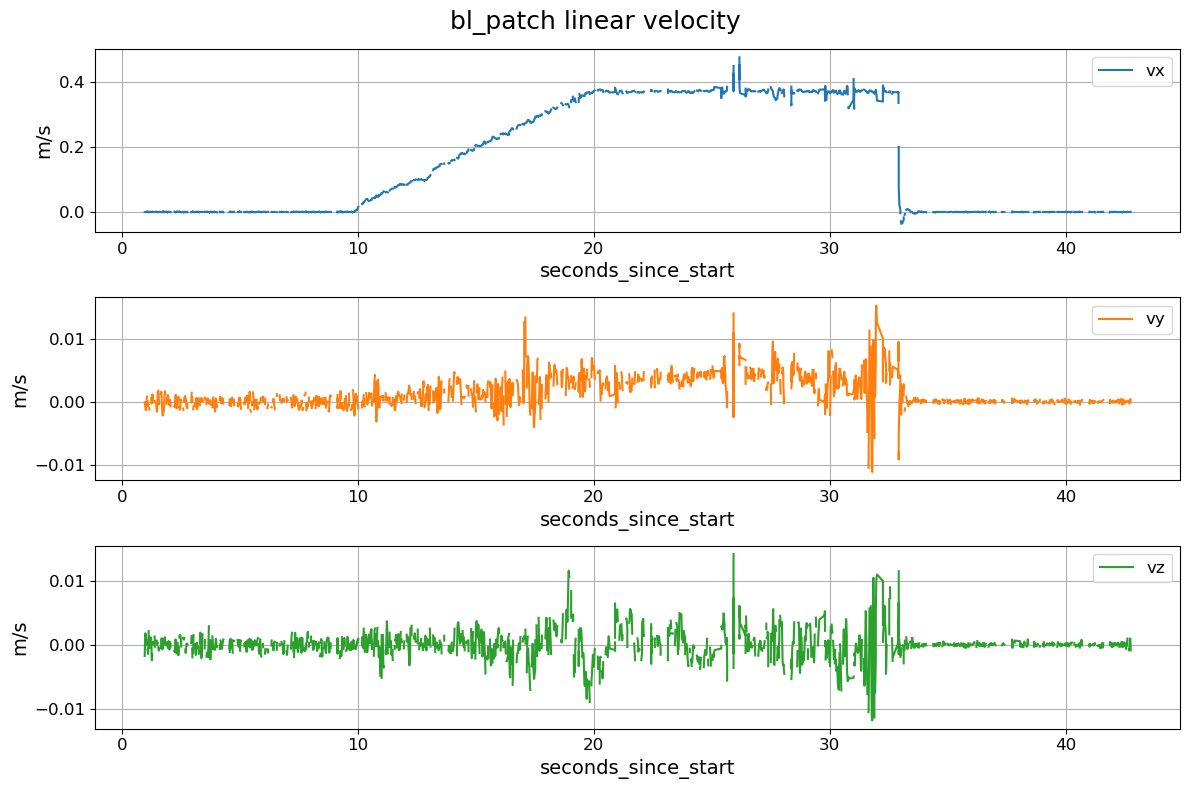

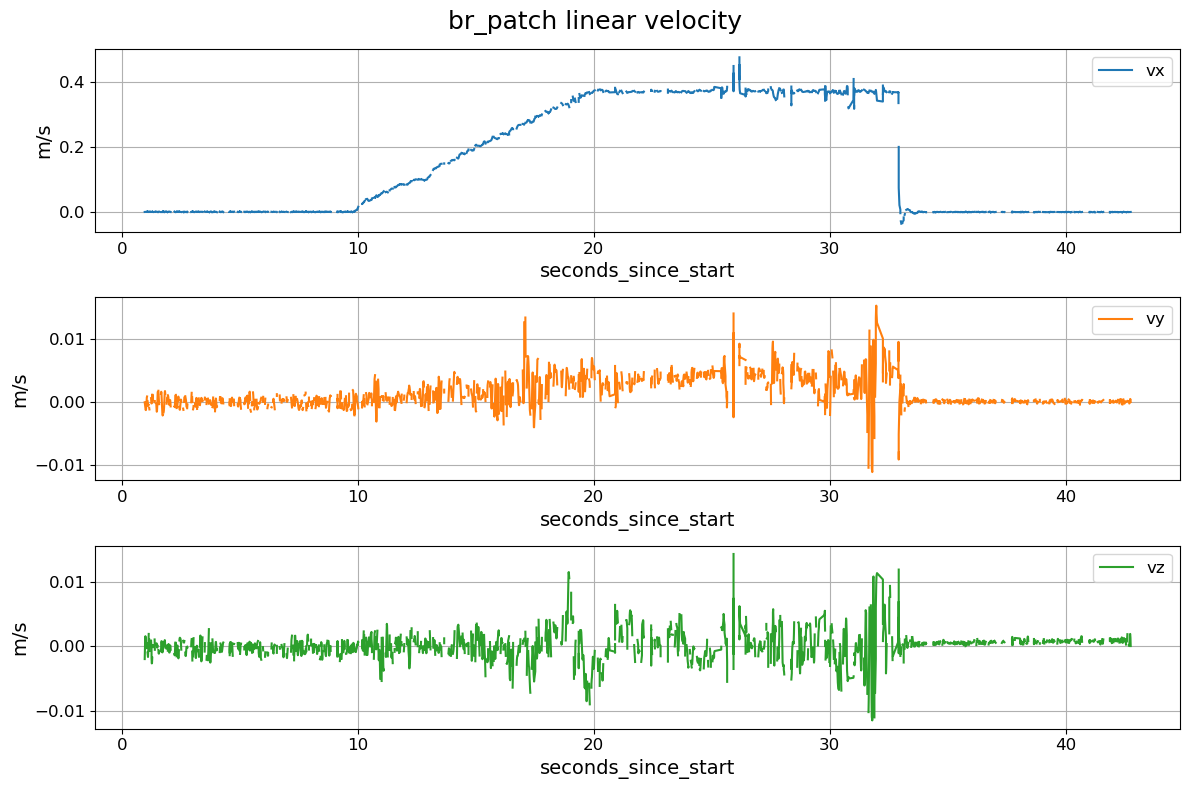

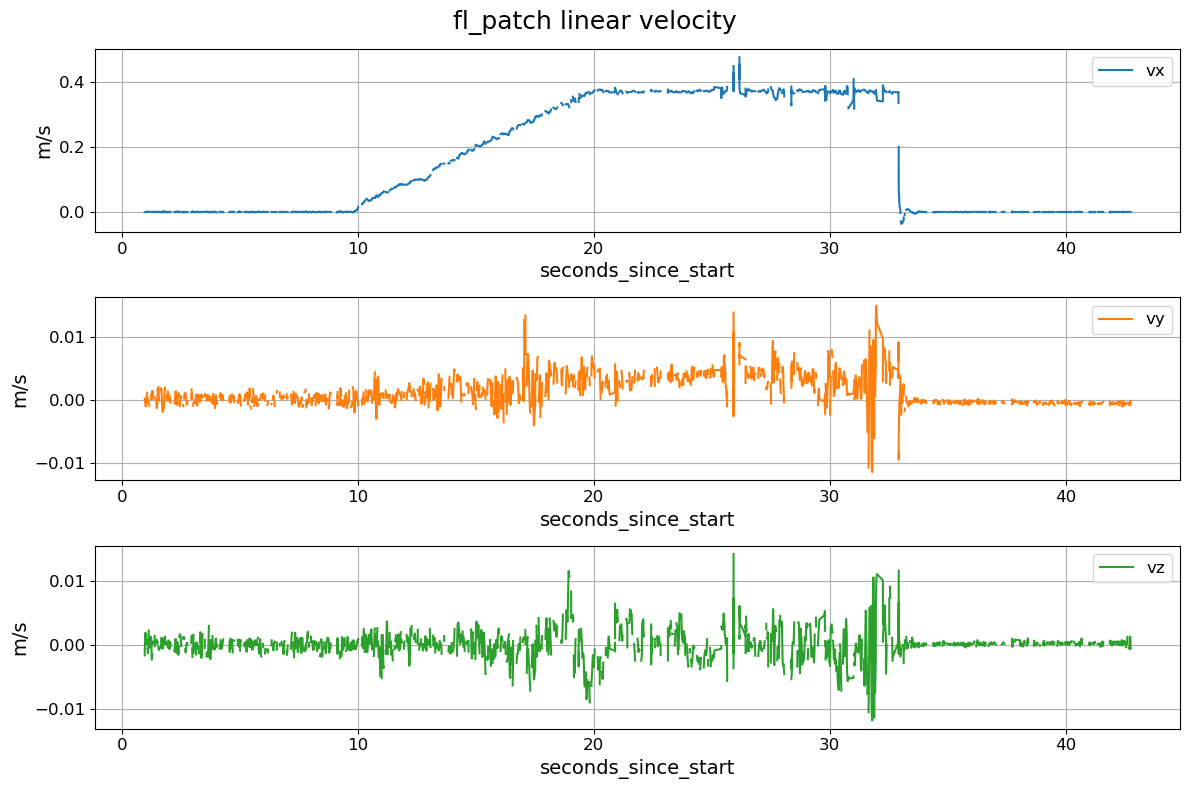

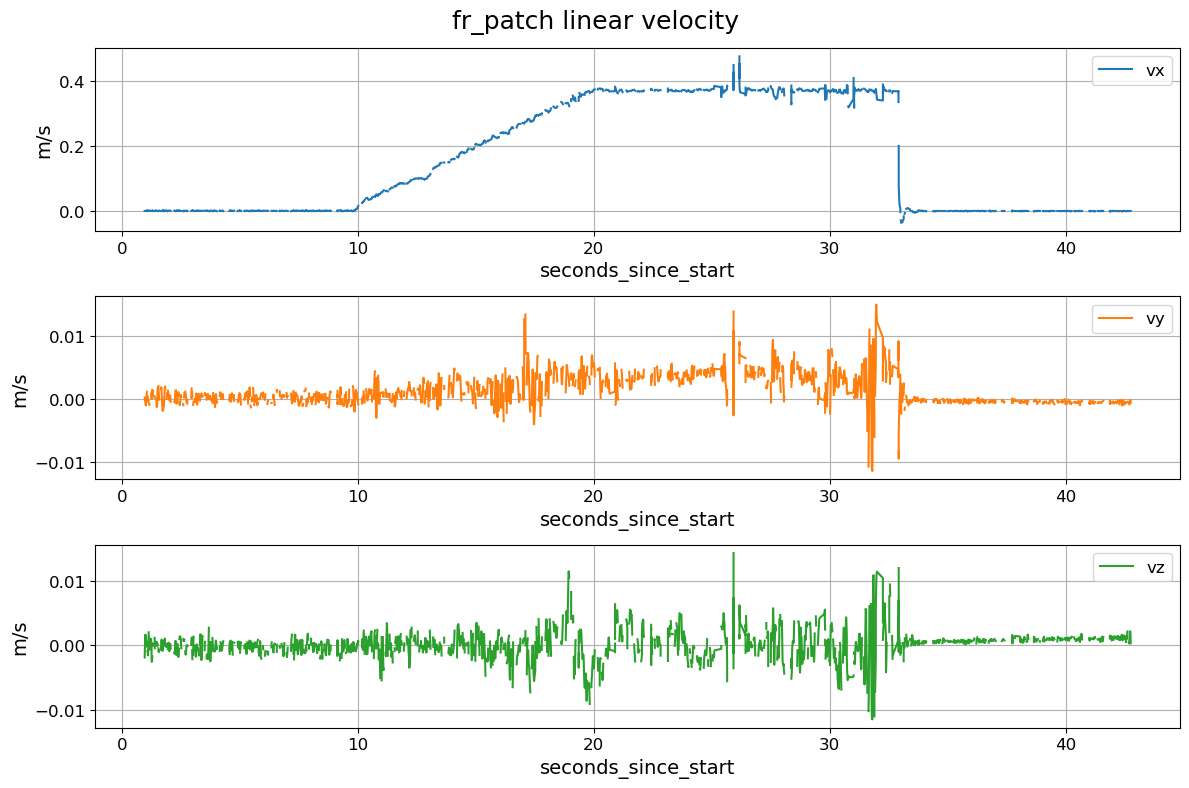

In [129]:
"""
Have a look at the local_frame_XX_patch_twists.
"""

# columns for linear and angular components
v_cols = ["vx", "vy", "vz"]
w_cols = ["wx", "wy", "wz"]

# assume `patch_xforms` and `cleaned_data` are already in scope
for patch_name in patch_xforms.columns:
    df_twist = cleaned_data[f"local_frame_{patch_name}_twist"]

    fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
    df_twist[v_cols].plot(
        ax=axes[0], title=f"{patch_name} linear velocity", xlabel=None, ylabel="m/s", grid=True, subplots=True
    )
    df_twist[w_cols].plot(
        ax=axes[1],
        title=f"{patch_name} angular velocity",
        xlabel="Time (s)",
        ylabel="rad/s",
        grid=True,
    )

    plt.tight_layout()
    # plt.show()

In [130]:
from rb_analysis import tf_plot_utils

"""
Animate all four vicon_frame_patch_poses and their attached local_frame_XX_patch_twists.
"""

# ani = tf_plot_utils.ViconTwistAnimator(
#     df_pose=cleaned_data["vicon_frame_bl_patch_pose"],
#     df_vicon_twist=cleaned_data["vicon_frame_bl_patch_twist"],
#     df_body_twist=cleaned_data["local_frame_bl_patch_twist"],
#     interval=10,
#     plot_step=10,
#     twist_scale=5,
#     axis_len=1,
#     elev=90,
#     azim=0,
# )
# ani.run()

'\nAnimate all four vicon_frame_patch_poses and their attached local_frame_XX_patch_twists.\n'

## Derive Wheel Angular Position and Angular Velocity from Encoder Counts

### Calculate Wheel Angle
Calc wheel angle from encoder counts and a known CPR.

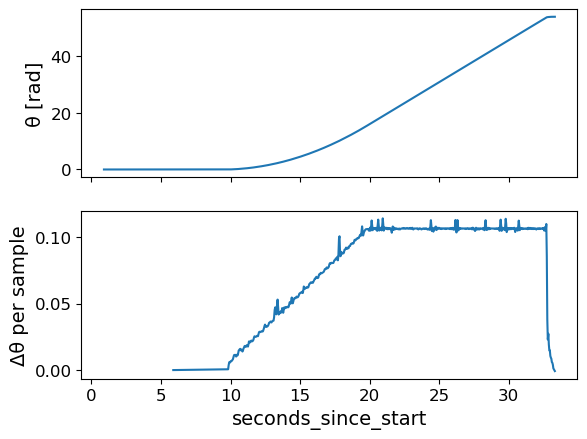

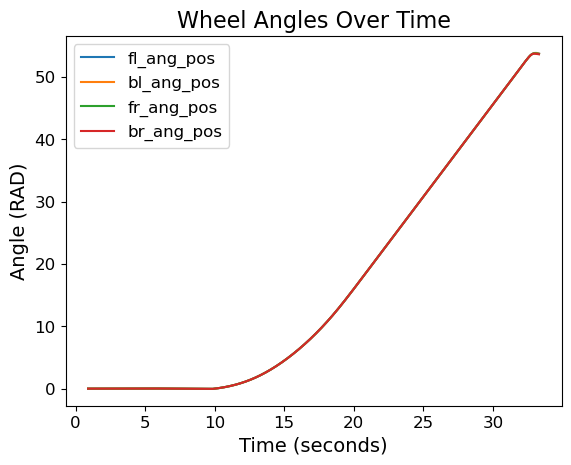

In [131]:
from rb_analysis.filtering import spline_smooth
from scipy.interpolate import UnivariateSpline
"""
Integrate the encoder counts to get wheel angles. This is done after outlier removal.
"""
# Get a view into the dynamic joint state DataFrame.
encoder_filtered = cleaned_data["encoder_filtered"].loc[
    :,
    [
        "fr_wheel_encoder_count",
        "br_wheel_encoder_count",
        "fl_wheel_encoder_count",
        "bl_wheel_encoder_count",
    ],
]

# Integrate wheel angles
wheel_ang_pos = encoders.angle_from_encoder_count(encoder_counts=encoder_filtered)


theta = encoders.angle_from_encoder_count(cleaned_data["encoder_filtered"]).iloc[:,0]   # one wheel
fig, ax = plt.subplots(2,1,sharex=True)
theta.plot(ax=ax[0]); ax[0].set_ylabel("θ [rad]")
theta.diff().plot(ax=ax[1]); ax[1].set_ylabel("Δθ per sample")



wheel_ang_pos = spline_smooth(wheel_ang_pos, s=.1)

# Visualize results.
wheel_ang_pos.plot(title="Wheel Angles Over Time", xlabel="Time (seconds)", ylabel="Angle (RAD)")

# Save in global dict.
cleaned_data["wheel_ang_pos"] = wheel_ang_pos




### Wheel Angular Velocity 
Differentiate wheel angles we just found.

,fl_ang_pos,bl_ang_pos,fr_ang_pos,br_ang_pos
seconds_since_start,,,,
0.903355,-0.761321,-0.775186,-0.728028,-0.754282
5.885709,-0.470414,-0.481766,-0.448918,-0.466227
9.830366,-0.223861,-0.232898,-0.211985,-0.221953
9.866411,-0.021665,-0.028583,-0.017231,-0.021459
9.908345,0.136175,0.131179,0.135345,0.135254
...,...,...,...,...
33.098404,-0.086745,-0.148391,-0.262292,-0.366770
33.134447,-0.360448,-0.368808,-0.427842,-0.438228
33.170427,-0.670963,-0.609709,-0.598222,-0.486676


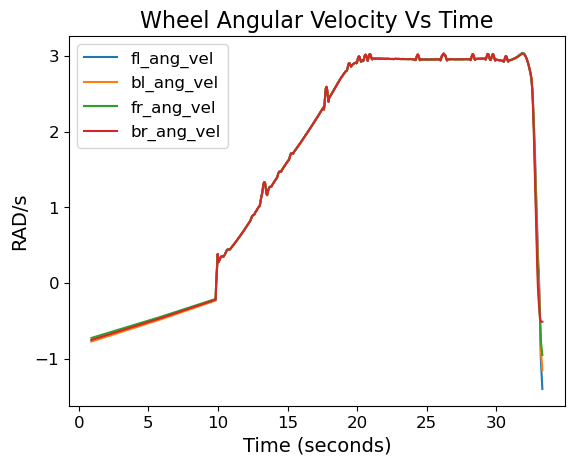

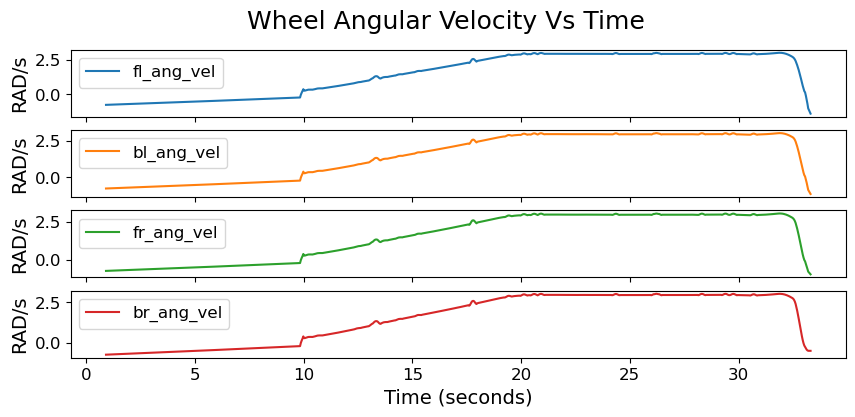

In [132]:
from rb_analysis import encoders

"""
Use a rough derivative to get angular velocity.
TODO compare this to np.grad and other available library functions.
"""


# Get a view into the dynamic joint state DataFrame.
wheel_ang_pos = cleaned_data["wheel_ang_pos"].loc[
    :,
    [
        "fl_ang_pos",
        "bl_ang_pos",
        "fr_ang_pos",
        "br_ang_pos",
    ],
]

# Calculate angular_vels. TODO drop NaNs or interp?
# wheel_ang_vel = encoders.angvel_from_angle(wheel_ang_pos).dropna()
wheel_ang_vel = filtering.diff_df_savgol(
    wheel_ang_pos, sg_window=11, sg_order=3, suffix=""
)
display(wheel_ang_vel)
wheel_ang_vel.rename(
    columns={
        "fl_ang_pos": "fl_ang_vel",
        "fr_ang_pos": "fr_ang_vel",
        "bl_ang_pos": "bl_ang_vel",
        "br_ang_pos": "br_ang_vel",
    },
    inplace=True,
)

wheel_ang_vel.plot(title="Wheel Angular Velocity Vs Time", xlabel="Time (seconds)", ylabel="RAD/s")

wheel_ang_vel.plot(
    title="Wheel Angular Velocity Vs Time",
    xlabel="Time (seconds)",
    ylabel="RAD/s",
    subplots=True,
    figsize=(10, 4),
)

cleaned_data["wheel_ang_vel"] = wheel_ang_vel


In [133]:
# # Calc wheel ang accel
# wheel_ang_pos = cleaned_data["wheel_ang_vel"].loc[
#     :,
#     [
#         "fl_ang_vel",
#         "bl_ang_vel",
#         "fr_ang_vel",
#         "br_ang_vel",
#     ],
# ]

# # Calculate angular_vels. TODO drop NaNs or interp?
# # wheel_ang_vel = encoders.angvel_from_angle(wheel_ang_pos).dropna()
# wheel_ang_accel = filtering.diff_df_savgol(
#     wheel_ang_pos, sg_window=11, sg_order=3, suffix=""
# ).dropna()
# display(wheel_ang_accel)
# wheel_ang_accel.rename(
#     columns={
#         "fl_ang_vel": "fl_ang_accel",
#         "fr_ang_vel": "fr_ang_accel",
#         "bl_ang_vel": "bl_ang_accel",
#         "br_ang_vel": "br_ang_accel",
#     },
#     inplace=True,
# )

# wheel_ang_accel.plot(
#     title="Wheel Angular Acceleration Vs Time", xlabel="Time (seconds)", ylabel="RAD/s^2"
# )

# wheel_ang_accel.plot(
#     title="Wheel Angular Acceleration Vs Time",
#     xlabel="Time (seconds)",
#     ylabel="RAD/s^2",
#     subplots=True,
# )

# # Encoder Counts
# cleaned_data["/dynamic_joint_states"][
#     [
#         "fr_wheel_encoder_count",
#         "fl_wheel_encoder_count",
#         "br_wheel_encoder_count",
#         "bl_wheel_encoder_count",
#     ]
# ].plot(
#     title="Raw Encoder Counts",
#     xlabel="Seconds",
#     ylabel="Count",
#     subplots=True,
#     grid=True,
# )

## Calculate Motor Torque

$$
\tau_\text{MOT} = K_T I_\text{MOT},\quad K_T = 3.89 \frac{A}{Nm}
$$



Left Nans: left_front_torque    0
left_back_torque     0
dtype: int64
Right Nans: right_front_torque    0
right_back_torque     0
dtype: int64


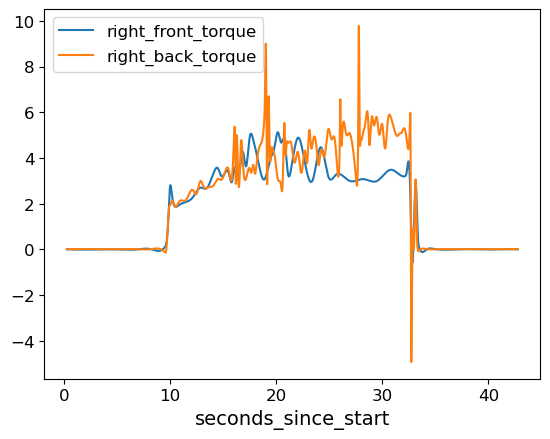

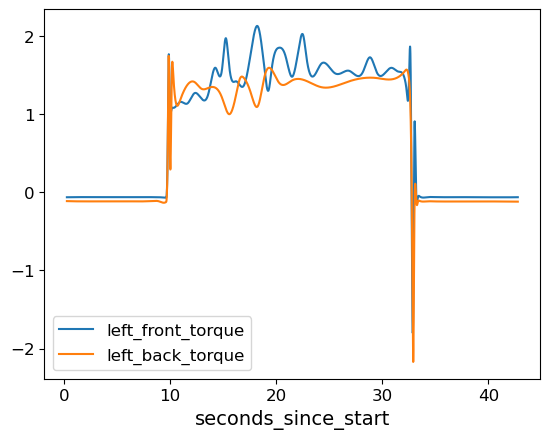

In [134]:
"""
Create a new time series of the motor torque for each wheel using the motor
currents for each wheel and our K_T constant.
"""

left_motor_currents = cleaned_data["left_motor_currents_filtered"]
right_motor_currents = cleaned_data["right_motor_currents_filtered"]

# Just multiply by K_T = 3.89(A/Nm) to get units of Torque.
left_motor_torques = left_motor_currents * 3.89
left_motor_torques = left_motor_torques.rename(
    columns={
        "left_front_amps": "left_front_torque",
        "left_back_amps": "left_back_torque",
    }
)

cleaned_data["left_motor_torques"] = left_motor_torques


# display(left_motor_torques)

right_motor_torques = right_motor_currents * 7.24
right_motor_torques = right_motor_torques.rename(
    columns={
        "right_front_amps": "right_front_torque",
        "right_back_amps": "right_back_torque",
    }
)
cleaned_data["right_motor_torques"] = right_motor_torques


right_motor_torques.plot()
left_motor_torques.plot()

# Check for NaNs
print('Left Nans:', cleaned_data["left_motor_torques"].isna().sum())
print('Right Nans:', cleaned_data["right_motor_torques"].isna().sum())


# Interpolate The Data
Our data is at different rates and phases so we need to do interpolation to work with them. Here I prefer to interpolate down to the lowest frequency data (our odometry oddly enough).

Interoplate the raw and transformed data. Then derive data products from the interpolated data so that the derived data aligns with each other and the original data.

The end result is all our time series data is aligned to the timestamps of the lowest publishing rate topic (~30Hz or something). This is our inertia poses, inertial twists, local twists, and currents.

Need to remember that to interp quaternions in the poses we can't do this normally, need to use SLERP. Borrow this from the tf library.

In [135]:
# We can concat all the resulting and time aligned dataframes into one final dataframe.
# """
# # Check which df has the least num of messages => lowest rate.
# # for name, df in cleaned_data.items():
# #     print(f"{name=:<30} {type(df)}: {len(df)=:10} \t {df.index.min()}")

# Interpolate all these to be at the same rate as the encoder_dfs
# Look at rates and dt.
for name, df in cleaned_data.items():
    print(f"{name}")

df_to_be_interped = [
    # "/vrpn_mocap/rb1/twist",
    "encoder_counts_outliers_removed",
    # "left_motor_currents_filtered",
    # "right_motor_currents_filtered",
    # "vicon_pose_final",
    "vicon_frame_marker_twist_final",
    "marker_frame_marker_twist",
    "vicon_frame_bl_patch_pose",
    "vicon_frame_br_patch_pose",
    "vicon_frame_fl_patch_pose",
    "vicon_frame_fr_patch_pose",
    "vicon_frame_bl_patch_twist",
    "vicon_frame_br_patch_twist",
    "vicon_frame_fl_patch_twist",
    "vicon_frame_fr_patch_twist",
    "local_frame_bl_patch_twist",
    "local_frame_br_patch_twist",
    "local_frame_fl_patch_twist",
    "local_frame_fr_patch_twist",
    "left_motor_torques",
    "right_motor_torques",
    "vicon_frame_marker_twist_filtered",
    "vicon_frame_marker_pose_filtered",
]

# Around 1122 rows.
encoder_dfs = [
    "encoder_counts_outliers_removed",
    "wheel_ang_pos",
    "wheel_ang_vel",
]

df_to_be_interped = df_to_be_interped + encoder_dfs

# df_to_be_interped = cleaned_data[df_to_be_interped]
subset = {k: cleaned_data[k] for k in df_to_be_interped if k in cleaned_data}


/tf_static
/tf
/dynamic_joint_states
/left_motor_currents
/right_motor_currents
/rb_slip_controller/cmd_vel
/vrpn_mocap/rb1/accel
/vrpn_mocap/rb1/pose
/vrpn_mocap/rb1/twist
/joint_states
/joy
/rb_slip_controller/odom
/diagnostics
/rosout
/robot_description
/pico_imu
patch_xforms
encoder_counts_outliers_removed
left_motor_currents_outliers_removed
right_motor_currents_outliers_removed
imu_unbiased
imu_outliers_removed
vicon_pose_outliers_removed
vicon_frame_marker_pose_filtered
vicon_frame_marker_twist_filtered
imu_filtered
left_motor_currents_filtered
right_motor_currents_filtered
encoder_filtered
vicon_frame_bl_patch_pose
vicon_frame_br_patch_pose
vicon_frame_fl_patch_pose
vicon_frame_fr_patch_pose
vicon_frame_marker_pose
vicon_frame_bl_patch_twist
vicon_frame_br_patch_twist
vicon_frame_fl_patch_twist
vicon_frame_fr_patch_twist
marker_frame_marker_twist
local_frame_bl_patch_twist
local_frame_br_patch_twist
local_frame_fl_patch_twist
local_frame_fr_patch_twist
wheel_ang_pos
wheel_ang_v

In [136]:
print(cleaned_data['local_frame_bl_patch_twist'].index == cleaned_data['local_frame_br_patch_twist'].index)

[ True  True  True ...  True  True  True]


Left Nans: left_front_torque    0
left_back_torque     0
dtype: int64
Right Nans: right_front_torque    0
right_back_torque     0
dtype: int64


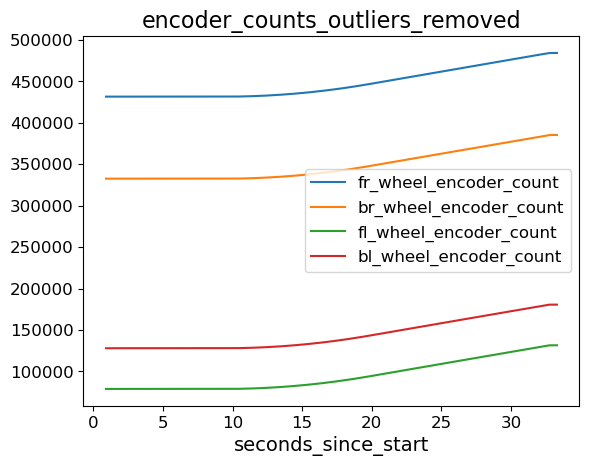

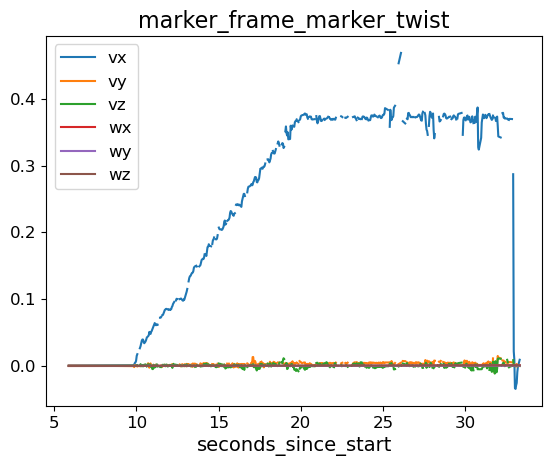

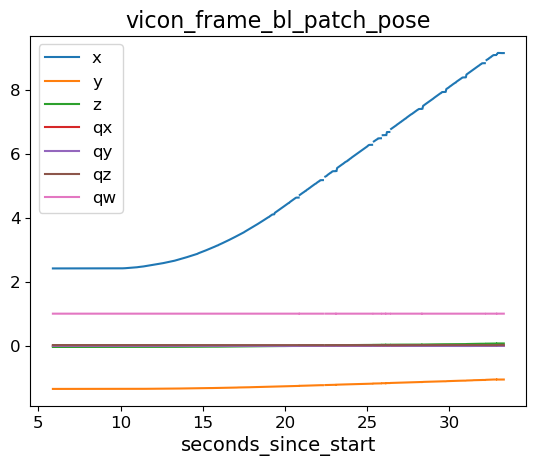

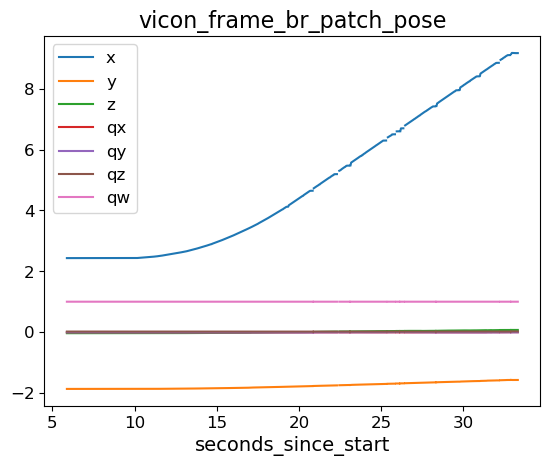

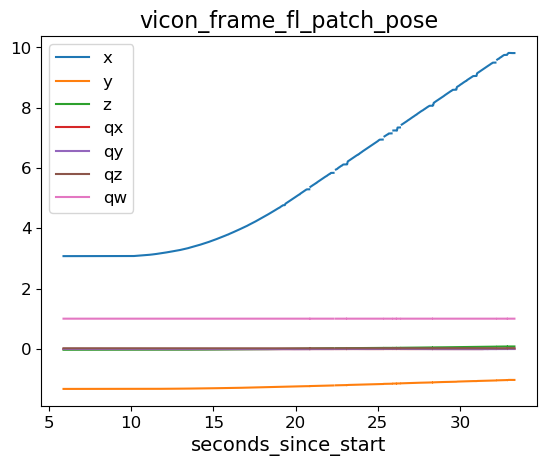

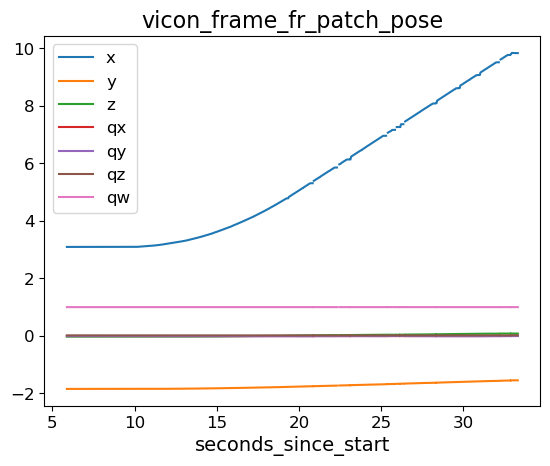

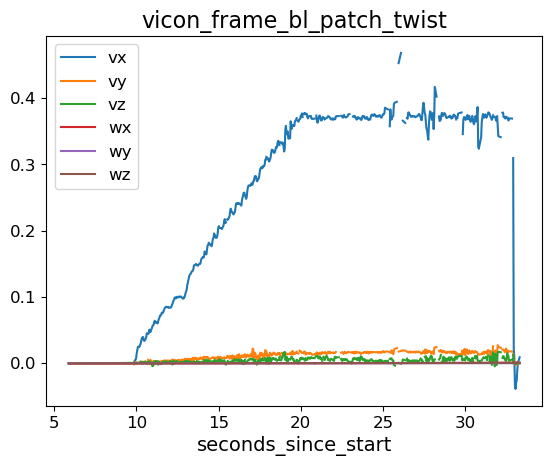

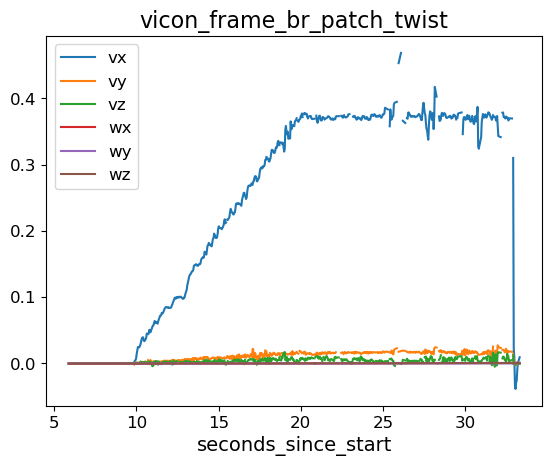

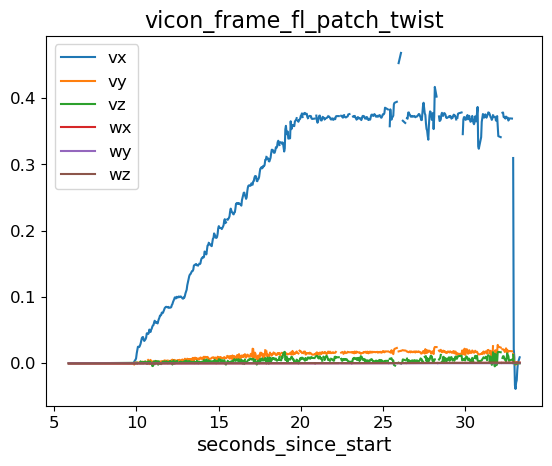

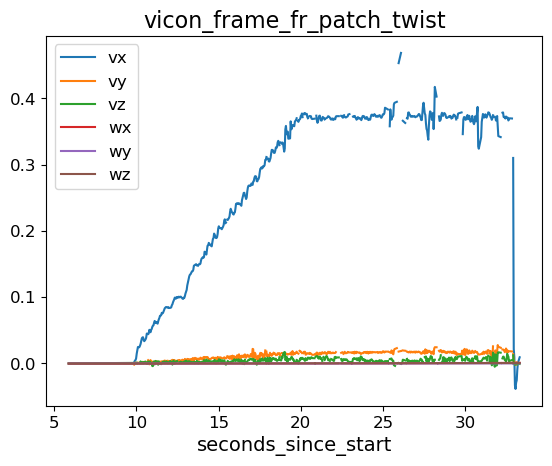

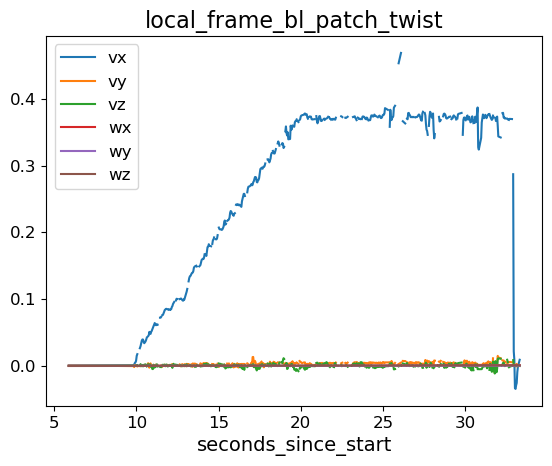

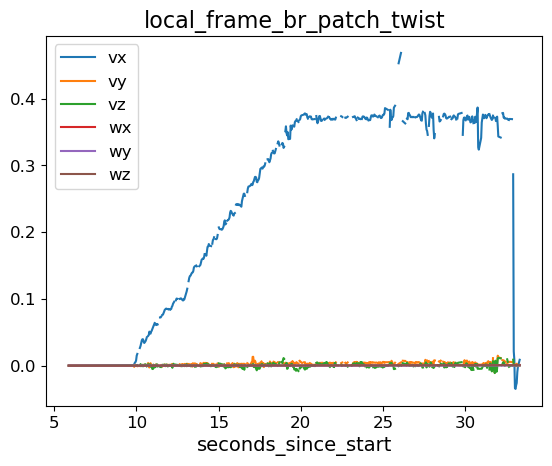

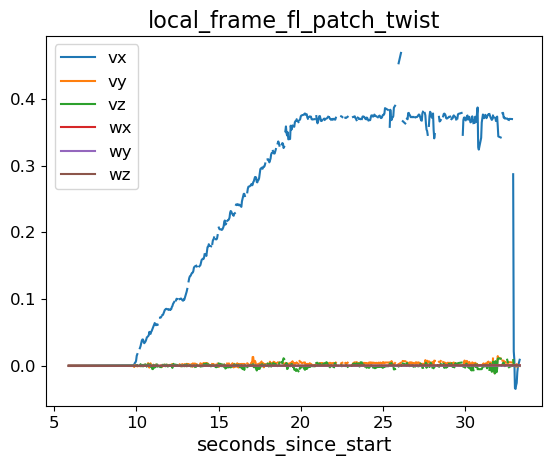

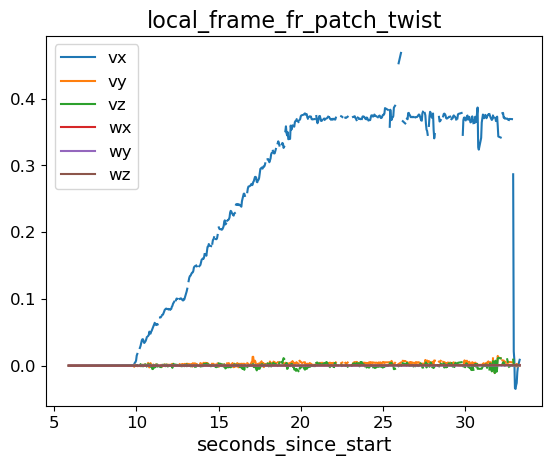

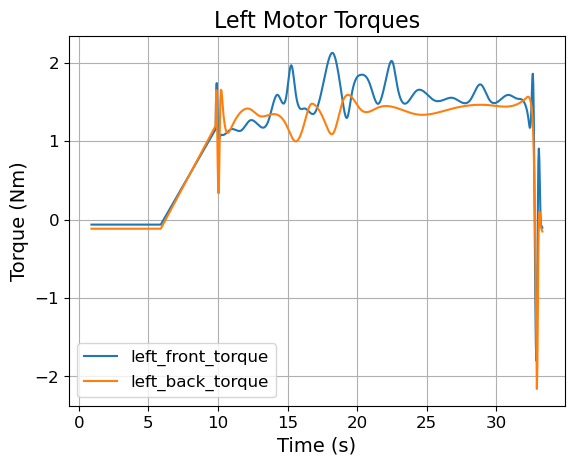

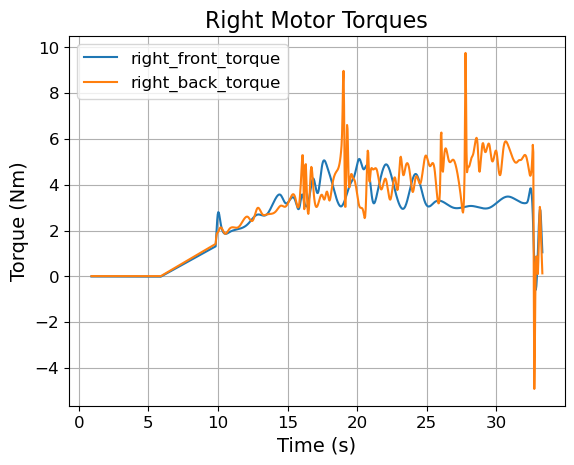

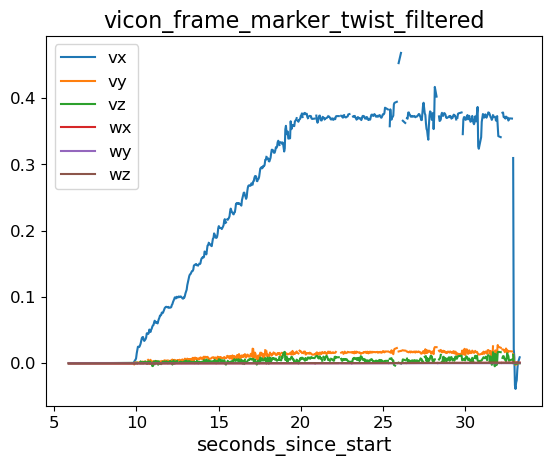

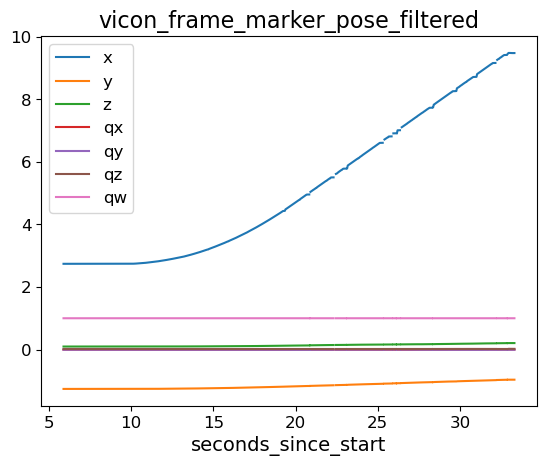

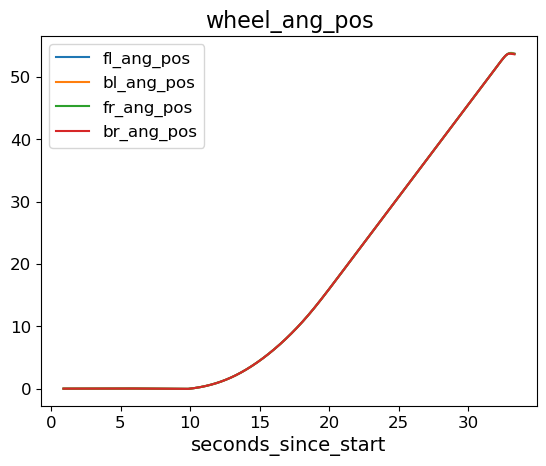

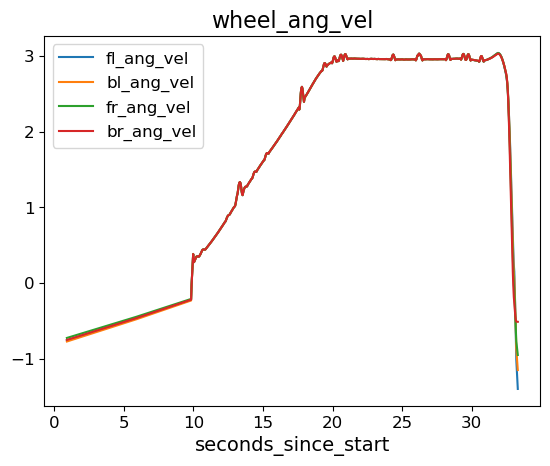

In [137]:
"""
Gather the data we need to be time synchronized into one thing. Use a multindex
for this? Well a multiindex would be if they didnt line up right? So Maybe use a
multiindex. But then for thing swhich must be aligned [torque, vicon_vx,
encoder_vx] these will share a common index.
"""
from rb_analysis.generic_plotting import plot_specs

# 1) Build your subset
df_to_be_interped = df_to_be_interped + encoder_dfs
subset = {k: cleaned_data[k] for k in df_to_be_interped if k in cleaned_data}

# 2) Master grid
encoder_index = cleaned_data["wheel_ang_pos"].index

# 3) Align & drop‐NaN per series
aligned = {}
for name, df in subset.items():
    df_num = df.apply(pd.to_numeric, errors="coerce").sort_index()

    # union anchors + encoder times
    idx_union = df_num.index.union(encoder_index)
    df_union = df_num.reindex(idx_union)

    # interpolate across that union
    df_interp = df_union.interpolate(method="index", limit=5)

    # back to encoder grid
    df_on_grid = df_interp.loc[encoder_index]

    # drop any rows that couldn’t be filled
    # df_clean = df_on_grid.dropna(how="any")
    df_clean = df_on_grid

    aligned[name] = df_clean

# final_df = pd.concat(aligned, axis=1, keys=aligned.keys())
# Drop inter-series NaNs as well.
final_df = pd.concat(aligned, axis=1, keys=aligned.keys(), join='inner')

# 5) Plot
for topic in final_df.columns.levels[0]:
    df_topic = final_df[topic]
    spec = plot_specs.get(topic)
    kwargs = spec.plot_kwargs if spec else {"title": topic}
    df_topic.plot(**kwargs)

print('Left Nans:', final_df["left_motor_torques"].isna().sum())
print('Right Nans:', final_df["right_motor_torques"].isna().sum())


In [138]:
# # Backup

# """
# Interpolate all the data to a common mesh.
# """

# df_to_be_interped = df_to_be_interped + encoder_dfs

# #All df in cleaned_data we want to bring for the final analysis.
# subset = {k: cleaned_data[k] for k in df_to_be_interped if k in cleaned_data}
# # Use the encoder index for the commmon grid.
# encoder_index = cleaned_data["wheel_ang_pos"].index

# # Align the dataframes.
# aligned = {}
# for name, df in subset.items():
#     df_num = df.apply(pd.to_numeric, errors="coerce").sort_index()

#     idx_union = df_num.index.union(encoder_index)
#     # idx_union = df_num.inter
#     # common_idx = encoder_index.intersection(df_num.index)

#     df_union = df_num.reindex(idx_union)
#     df_interp = df_union.interpolate(method="index")
#     aligned[name] = df_interp.loc[encoder_index]

# # Combine the df into one big df.
# final_df = pd.concat(aligned, axis=1, keys=aligned.keys())

# # final_df = final_df.drop(columns=["header.stamp.sec", "header.stamp.nanosec"], level=1)

# # for name in final_df.columns.levels[0]:
# #     df = final_df[name]
# #     df.plot(
# #         title=name,
# #         **plot_kwargs,
# #     )

# for topic in final_df.columns.levels[0]:
#     df_topic = final_df[topic]
#     spec = plot_specs.get(topic)
#     kwargs = spec.plot_kwargs if spec else {"title": topic}
#     df_topic.plot(**kwargs)

## Combine interpolated Motor Torques


In [139]:
from scipy.signal import butter, filtfilt

def low_pass_regular_keep_nans(df: pd.DataFrame, cutoff: float, order: int, fs: float = 1.0):
    """
    Low-pass every numeric column but preserve NaNs exactly where they were.

    Steps
    -----
    1.  Record the NaN mask.
    2.  Temporarily fill gaps with linear interpolation (end-point padded).
    3.  Butterworth + filtfilt on the filled series.
    4.  Re-insert NaNs at their original positions.
    """
    b, a = butter(order, cutoff / (0.5 * fs), btype="low")
    out = pd.DataFrame(index=df.index, columns=df.columns, dtype=float)

    for col in df:
        x = df[col]
        isnan = x.isna()
        if isnan.all():
            out[col] = x              # column is entirely NaN -> leave it
            continue

        # 1 & 2  interpolate inside gaps; pad ends with nearest good value
        filled = x.interpolate("linear", limit_direction="both")

        # 3   filtfilt
        y = filtfilt(b, a, filled.to_numpy())

        # 4   restore original NaNs
        y[isnan.to_numpy()] = np.nan
        out[col] = y

    return out

Left Nans: left_front_torque    0
left_back_torque     0
dtype: int64
Right Nans: right_front_torque    0
right_back_torque     0
dtype: int64


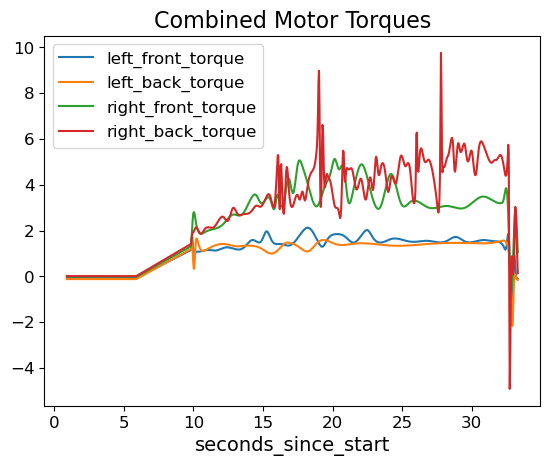

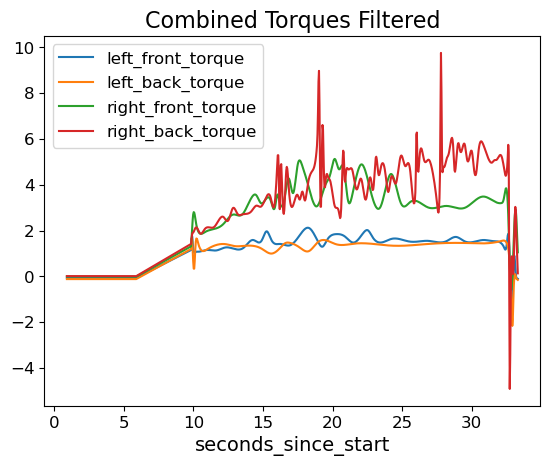

In [140]:
from rb_analysis.filtering import low_pass_regular

# robot & patch parameters
mass = 40.0  # kg
F_N_net = 9.81 * mass  # total normal force (N)
F_N = F_N_net / 4  # per patch
radius = 0.127  # m


print('Left Nans:', final_df["left_motor_torques"].isna().sum())
print('Right Nans:', final_df["right_motor_torques"].isna().sum())

motor_torques_combined = pd.concat(
    [
        final_df["left_motor_torques"],
        final_df["right_motor_torques"],
    ],
    axis=1,
)
mu = motor_torques_combined / radius  # τ → force
mu = mu / F_N  # normalize by normal force

motor_torques_combined.plot(title="Combined Motor Torques")

for col in motor_torques_combined.columns:
    final_df[("motor_torques_combined", col)] = motor_torques_combined[col]


# # motor_torques_combined_filtered = low_pass_regular(motor_torques_combined, cutoff=5, order=4)
# motor_torques_combined_filtered = low_pass_regular_keep_nans(
#     motor_torques_combined, cutoff=10, order=4, fs=27.0
# )
# print(motor_torques_combined_filtered.describe())
motor_torques_combined_filtered = motor_torques_combined

for col in motor_torques_combined_filtered.columns:
    final_df[("motor_torques_combined_filtered", col)] = motor_torques_combined_filtered[col]

motor_torques_combined_filtered.plot(title="Combined Torques Filtered")



# ── immediately after `motor_torques_combined_filtered` is created ───────
for col in motor_torques_combined.columns:
    bad = motor_torques_combined.index.symmetric_difference(
              motor_torques_combined_filtered.index)
    if len(bad):
        raise RuntimeError(f"index drift after LP on {col}: {len(bad)} rows lost")

# display(final_df["motor_torques_combined_filtered"])

# Calc Slip Ratio
For the FrontLeft wheel (contact patch) found with the local-frame longitudinal velocity (+X) and encoder derived wheel angular velocity.
$$
    s(t) = \frac{r \dot{\theta}_\textrm{FL}(t) - v_\textrm{FL}(t)}{max(v_\textrm{FL}(t), r \dot{\theta}_\textrm{FL}(t) )} \times 100\%
$$

In [141]:
k=None

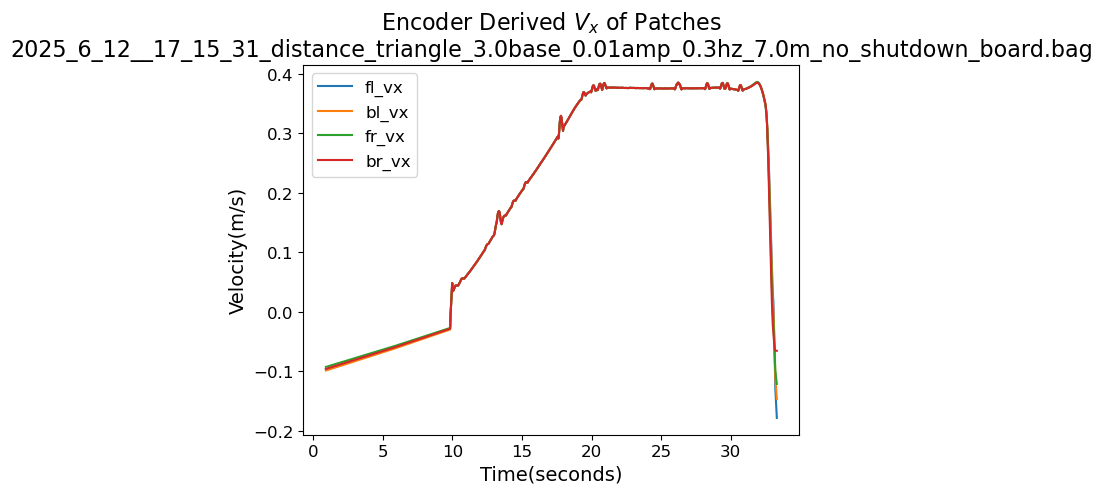

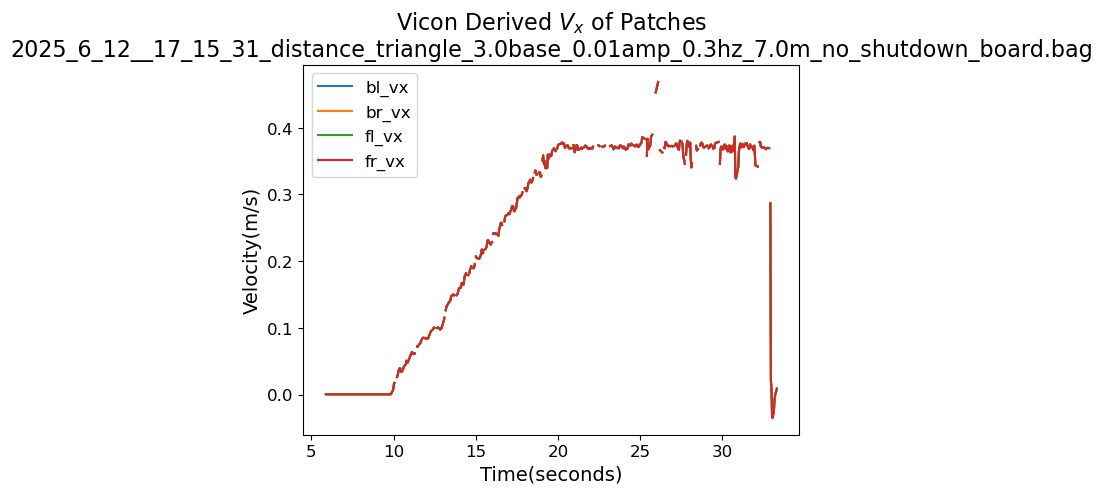

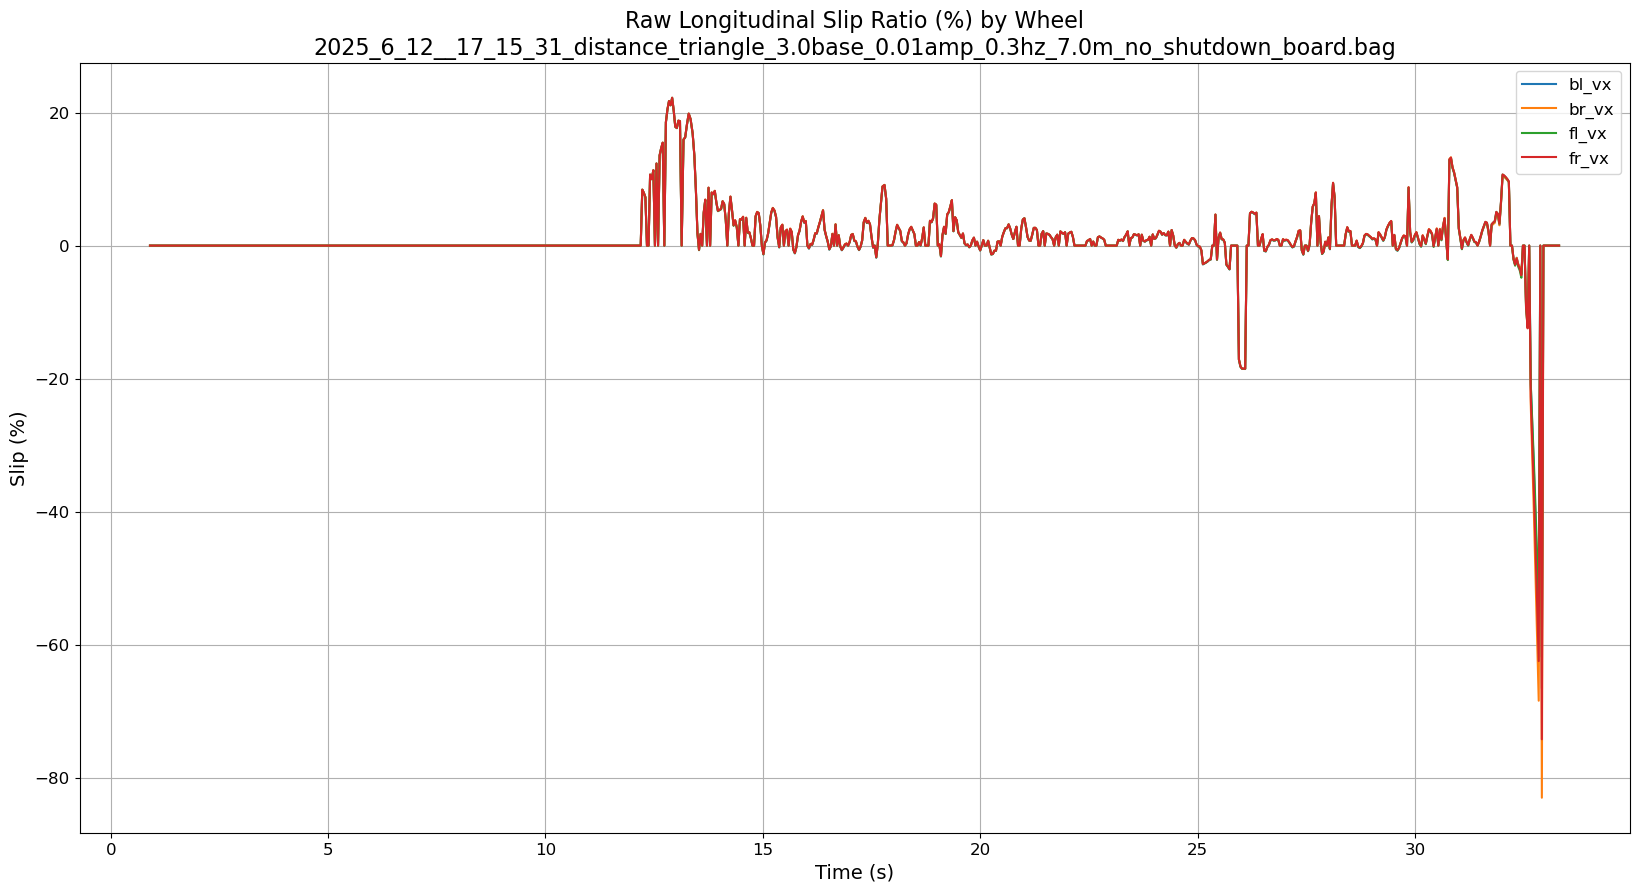

In [ ]:
from typing import Mapping

""" Find the longitudinal slip percentage.

Use our synchronized data to calculate slip for each tire. Grab only the X
component of the patch twists for this. Also let's use a velocity threshold for
the max velocity of either encoder or vicon derived velocity.
"""
radius = 0.127

# Calculate encoder derived longitudinal velocity of the wheels.
# wheel_vx_encoder = final_df["wheel_ang_vel"] * 0.127  # v = r omega
wheel_vx_encoder = final_df["wheel_ang_vel"].copy() * radius

wheel_vx_encoder.rename(
    columns={
        "bl_ang_vel": "bl_vx",
        "br_ang_vel": "br_vx",
        "fl_ang_vel": "fl_vx",
        "fr_ang_vel": "fr_vx",
    },
    inplace=True,
)

# Combine the Vx components of the four vicon derived patch twists.
all_patch_twist_true = pd.DataFrame(
    {
        "bl_vx": final_df["local_frame_bl_patch_twist"]["vx"],
        "br_vx": final_df["local_frame_br_patch_twist"]["vx"],
        "fl_vx": final_df["local_frame_fl_patch_twist"]["vx"],
        "fr_vx": final_df["local_frame_fr_patch_twist"]["vx"],
    },
    index=final_df.index,
)

# Get all non indices.
not_nan = wheel_vx_encoder.notna() & all_patch_twist_true.notna()

# display(all_patch_twist_true.describe())
# display(wheel_vx_encoder.describe())
# Plot both the encoder and vicon derived longitudinal patch velocity.
wheel_vx_encoder.plot(
    title=f"Encoder Derived $V_x$ of Patches\n{metadata['plot_subtitle']}",
    legend=True,
    xlabel="Time(seconds)",
    ylabel="Velocity(m/s)",
)
all_patch_twist_true.plot(
    title=f"Vicon Derived $V_x$ of Patches\n{metadata['plot_subtitle']}", xlabel="Time(seconds)", ylabel="Velocity(m/s)"
)

# Velocity threshold.
eps = 0.1# m/s



# Elementwise denominator,
den = wheel_vx_encoder.combine(all_patch_twist_true, np.maximum)

# valid = den >= eps
# Also not NaN
valid = (den >= eps) & not_nan

#  Numerator r\oemga - v_x
num = wheel_vx_encoder.sub(all_patch_twist_true)

# Slip ratio (fractional).
slip_longi = num.div(den)
# display(slip_longi.describe())

#mask out invalid regions
# slip_longi[~valid] = np.nan
slip_longi[~valid] = 0.0

# In percentage units.
slip_percent = slip_longi * 100

#plot
ax = slip_percent.plot(
    title=f"Raw Longitudinal Slip Ratio (%) by Wheel\n{metadata['plot_subtitle']}",
    xlabel="Time (s)",
    ylabel="Slip (%)",
    grid=True,
    legend=True,
    figsize=(20,10)
)

# This creates a multilevel to concat?
# Are multilevel df's are a pain or do I just not know how to use them?
# final_df = pd.concat(aligned, axis=1, keys=aligned.keys())

# Save it this way.
for col in slip_percent.columns:
    final_df[("slip_percent", col)] = slip_percent[col]



In [143]:
# wheel_vx_encoder = final_df["wheel_ang_vel"] * 0.127 
# all_patch_vx_vicon = pd.DataFrame(
#     {
#         "bl_vx": final_df["local_frame_bl_patch_twist"]["vx"],
#         "br_vx": final_df["local_frame_br_patch_twist"]["vx"],
#         "fl_vx": final_df["local_frame_fl_patch_twist"]["vx"],
#         "fr_vx": final_df["local_frame_fr_patch_twist"]["vx"],
#     },
#     index=final_df.index,
# )

# plt.figure()
# plt.plot(wheel_vx_encoder.index, wheel_vx_encoder, label="wheel fl_vx")
# plt.plot(all_patch_vx_vicon.index, all_patch_vx_vicon, label="patch fl_vx", alpha=0.7)
# plt.legend(); plt.title("Encoder vs Vicon on common timebase")


In [144]:
# # pick your two DataFrames
# wheel = wheel_vx_encoder       # encoder-derived Vx
# patch = all_patch_twist_true   # Vicon-derived Vx

# # 2) check for perfect index alignment
# aligned = wheel.index.equals(patch)
# print(aligned)

# # 4) quick scatter to eyeball sync
# plt.figure()
# plt.plot(wheel.index, wheel["fl_vx"], label="fl_wheel_vel encoder")
# plt.plot(patch.index, patch["fl_vx"], label="fl_wheel_vel vicon", alpha=0.7)
# plt.legend(); plt.title("Encoder vs Vicon time synchronized")


## Filter Slip
Get rid of some of the noise here too?

fs=27.77877935709973


<AxesSubplot: title={'center': 'Slip Percentage Raw cutoff=3Hz\n2025_6_12__17_15_31_distance_triangle_3.0base_0.01amp_0.3hz_7.0m_no_shutdown_board.bag'}, xlabel='seconds_since_start'>

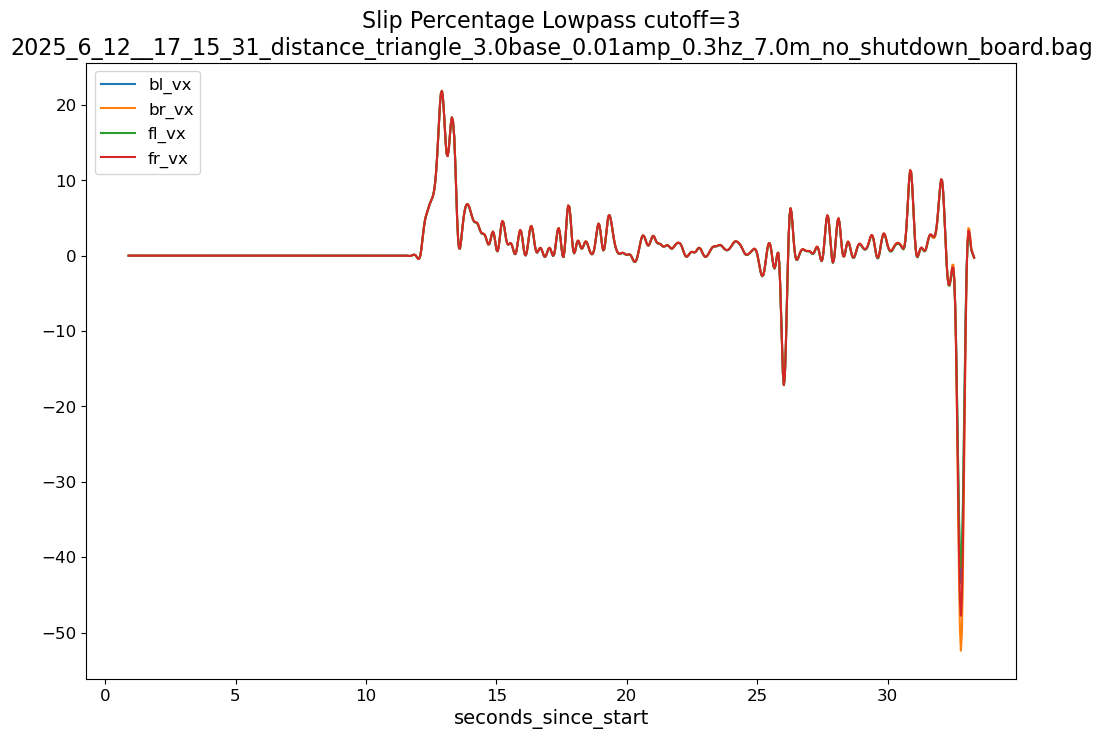

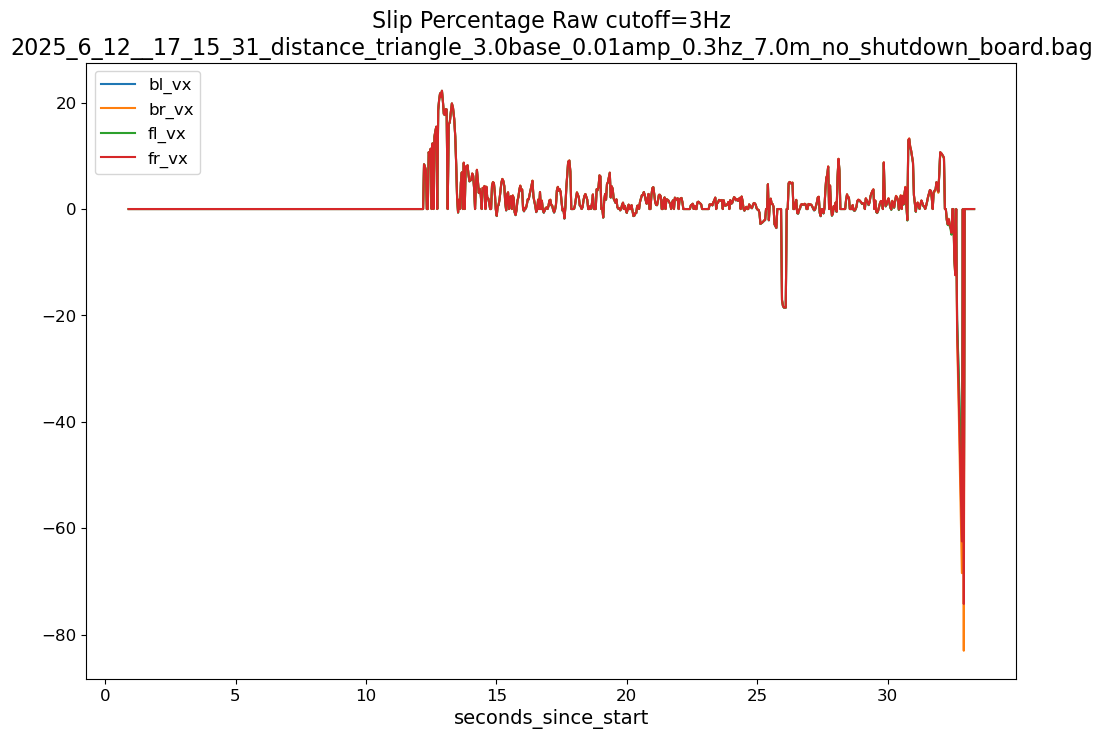

In [145]:
""" Try a generic low pass filter and see how that works

"""
from rb_analysis.filtering import low_pass_regular

slip_percent_raw = final_df["slip_percent"]

cutoff=3
slip_percent_filtered = low_pass_regular(slip_percent_raw,cutoff=cutoff,order=4)

# Save.
for col in slip_percent_filtered.columns:
    final_df[("slip_percent_filtered", col)] = slip_percent_filtered[col]

slip_percent_filtered.plot(title=f'Slip Percentage Lowpass {cutoff=}\n{metadata['plot_subtitle']}',figsize=(12,8))

slip_percent_raw.plot(title=f'Slip Percentage Raw {cutoff=}Hz\n{metadata['plot_subtitle']}',figsize=(12,8))

In [146]:
# """ Remove slip outside [5-20] range here?

# LLM slop. See if this is doing what it should.

# Maybe save this until later when we fit our line so it's more flexible.
# """
# low = 5
# high = 20

# # 1) element-wise “in band” test:  5 ≤ |slip| ≤ 20
# band_mask = (slip_percent.abs() >= low) & (slip_percent.abs() <= high)  # DataFrame[bool]

# # 2) keep rows where at least one wheel is in the band
# row_mask = band_mask.any(axis=1)

# # 3) slice and drop rows that are fully NaN (from earlier eps-masking)
# slip_5_20 = slip_percent[row_mask].dropna(how="all")
# # slip_5_20.plot(title='5-20% slip')
# slip_5_20.plot(title=f'Slip between [{low},{high}]', marker='o', linestyle='None', xlabel='Time (s)', ylabel='Slip (%)')


# # Plot before
# final_df["slip_percent"].plot(marker='o', linestyle='None', xlabel='Time (s)', ylabel='Slip (%)', title="Raw slip percent")


# # And save.
# for col in slip_5_20.columns:
#     final_df[("slip_5_20", col)] = slip_5_20[col]

# print(f"rows kept: {len(slip_5_20)} / {len(slip_percent)}")
# # display(slip_5_20.head())


In [147]:
# """
# Now find lateral slip per patch.

# We use this later to remove measurements where lateral slip is too high.
# """

# # Combine the Vx components of the four vicon derived patch twists.
# all_patch_twist_true = pd.DataFrame(
#     {
#         "bl_vx": final_df["local_frame_bl_patch_twist"]["vy"],
#         "br_vx": final_df["local_frame_br_patch_twist"]["vy"],
#         "fl_vx": final_df["local_frame_fl_patch_twist"]["vy"],
#         "fr_vx": final_df["local_frame_fr_patch_twist"]["vy"],
#     },
#     index=final_df.index,
# )

# # display(all_patch_twist_true.describe())
# # display(wheel_vx_encoder.describe())
# # Plot both the encoder and vicon derived longitudinal patch velocity.

# all_patch_twist_true.plot(
#     title=f"Vicon Derived Lateral Velocity $V_y$ of Patches\n{metadata['plot_subtitle']}",
#     xlabel="Time(seconds)",
#     ylabel="Velocity(m/s)",
# )

# # final_df["vicon_frame_marker_pose_filtered"].plot(title="Vicon Frame Marker Pose", y=["x", "y"])
# # final_df["vicon_frame_marker_twist_filtered"].plot(title="Vicon Frame Marker Twist")


## Mask Off Slip Data Where $S_\text{lateral} > \epsilon$
We can assume $\tau_\text{MOT} = \tau_\text{fric} - \tau_\text{losses}$ if we have perfectly longitudinal motion. If we are far enough from this case then the relationship of wheel torque to the lateral and longitudinal friction forces becomes more complex and requires a ground-surface friction model which we are trying to avoid.

Right now this is actually just threshold based on the y velocity reported by the vicon system.

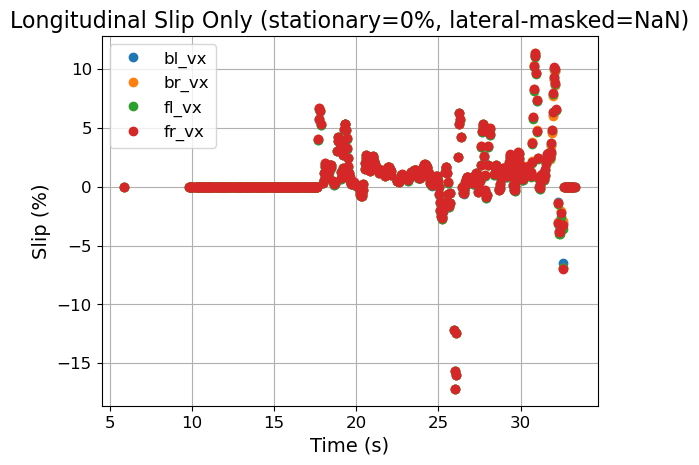

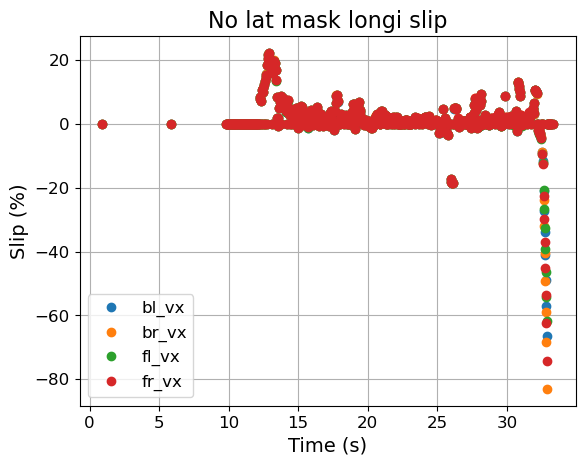

In [148]:
# 1) Build lateral‐velocity mask (only keep true longitudinal slip)
epsilon_lat = 1
epsilon_v = 0.1


lat_vel = pd.DataFrame(
    {
        "bl": final_df["local_frame_bl_patch_twist"]["vy"],
        "br": final_df["local_frame_br_patch_twist"]["vy"],
        "fl": final_df["local_frame_fl_patch_twist"]["vy"],
        "fr": final_df["local_frame_fr_patch_twist"]["vy"],
    },
    index=final_df.index,
)
longitudinal_only = lat_vel.abs().max(axis=1) < epsilon_lat

# 2) Build “moving” mask (exclude stationary, which should show zero slip)
wheel_vx_enc = final_df["wheel_ang_vel"] * 0.127  # v = r·ω
epsilon_v = 0.3
moving = wheel_vx_enc.abs().max(axis=1) > epsilon_v

# 3) Start from your slip_percent DF and apply masks
slip_longi_masked = final_df["slip_percent_filtered"].copy()
# slip_longi_masked = slip_percent.copy()

# a) set truly stationary → 0% slip
slip_longi_masked.loc[~moving] = 0

# b) mask out any non-longitudinal periods → NaN
slip_longi_masked.loc[~longitudinal_only] = np.nan

for col in slip_longi_masked.columns:
    final_df[("slip_longi_masked", col)] = slip_longi_masked[col]

# slip_5_20.plot(marker='o', linestyle='None', xlabel='Time (s)', ylabel='Slip (%)')


if logger.getEffectiveLevel() <= logging.INFO:

    # 5) plot
    slip_longi_masked.plot(
        title="Longitudinal Slip Only (stationary=0%, lateral‐masked=NaN)",
        linestyle='None',marker='o',
        xlabel="Time (s)",
        ylabel="Slip (%)",
        grid=True,
        legend=True,
    )

    final_df["slip_percent"].plot(
        title="No lat mask longi slip",
        linestyle='None',marker='o',
        xlabel="Time (s)",
        ylabel="Slip (%)",
        grid=True,
        legend=True
    )

## Remove slip bias $\delta$
Now that we have only longitudinal data we can unbias it using constant velocity driving data.

Take an average measurement of the slip ratio when the wheel is not slipping. This represents steady state wheel angle measurement error from wheel radius measurements, encoders, etc. Each rosbag begins with a constant velocity section we can use to do this.

Or maybe we can just look at the force-slip plot and determine $\delta$ as being the average slip when the motor torque>$\epsilon$. Which would be better? Well the torque is going to be non-zero and non-constant during continuous velocity driving.

Bias window (stable & constant jerk): 24.726626873 → 25.086674213 (11 samples)
usable bias samples: 11
computed bias delta: bl_vx    0.493622
br_vx    0.530829
fl_vx    0.512858
fr_vx    0.533790
dtype: float64


<AxesSubplot: xlabel='seconds_since_start'>

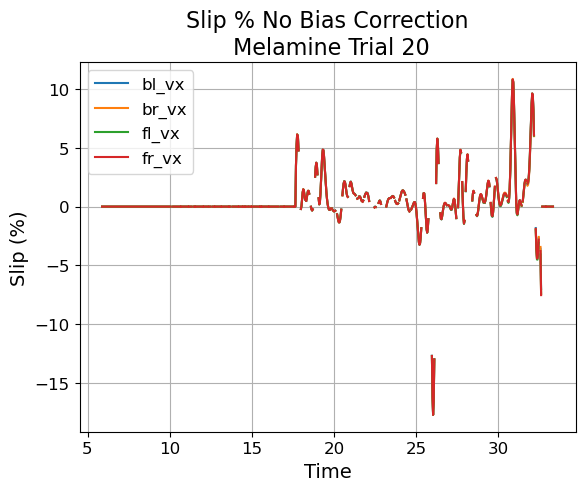

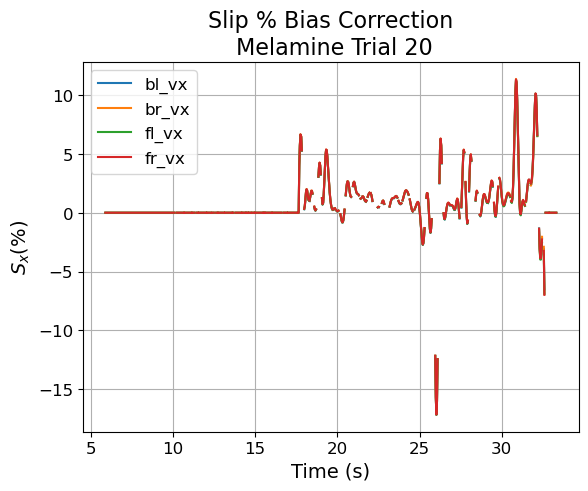

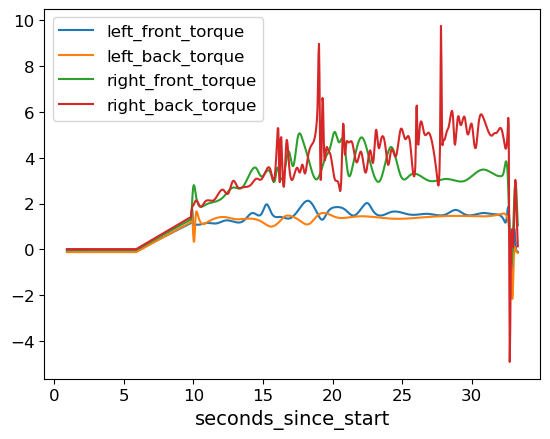

In [ ]:
import numpy as np


epsilon_jerk = 0.1
epsilon_v = 0.1

# 1) Compute jerk + constant mask
twist_body  = final_df["marker_frame_marker_twist"][["vx","vy","vz"]]
dt          = twist_body.index.to_series().diff().astype(float)
dv          = twist_body.diff().abs().divide(dt, axis=0)
jerk        = dv.max(axis=1)
is_constant = jerk < epsilon_jerk

# 2) Compute moving mask
wheel_vx = final_df["wheel_ang_vel"] * radius
moving   = wheel_vx.abs().max(axis=1) > epsilon_v

# 3) Combine for “stable motion”
stable = is_constant & moving

# 4) Find the longest continuous stable run
group_id    = (stable != stable.shift()).cumsum()
runs        = stable.groupby(group_id).agg(["first","size"])
true_runs   = runs[runs["first"]]          # only runs where stable==True
largest_grp = true_runs["size"].idxmax()
mask_run    = (group_id == largest_grp)

# get t0, t1
idxs        = twist_body.index[mask_run]
t0, t1      = idxs[0], idxs[-1]
print(f"Bias window (stable & constant jerk): {t0} → {t1} ({len(idxs)} samples)")

# 5) Pull your masked slip and restrict to that run
slip_masked   = final_df["slip_longi_masked"]
slip_segment  = slip_masked.loc[mask_run]

# 6) Exclude zero‐slip entries (stationary artifacts)
slip_segment  = slip_segment.replace(0, np.nan).dropna()

print("usable bias samples:", len(slip_segment))
if not slip_segment.empty:
    delta = slip_segment.median()
    print("computed bias delta:", delta)
else:
    print("No stable region found — using hardcoded bias delta.")
    delta = pd.Series({
        "bl_vx": 0.0,
        "br_vx": 0.0,
        "fl_vx": 0.0,
        "fr_vx": 0.0,
    })
    print("hardcoded fallback delta:", delta)



# 7) Compute delta
# delta = slip_segment.median()
# print("computed bias delta:", delta)

# 8) Subtract
# slip_unbiased = slip_masked.subtract(delta, axis=1)
# 8) Subtract bias only on non-zero slip entries
slip_unbiased = slip_masked.copy()
nonzero_mask = slip_masked != 0  # DataFrame of booleans

# apply column-wise bias subtraction only where slip_masked != 0
for col in slip_masked.columns:
    slip_unbiased.loc[nonzero_mask[col], col] = (
        slip_masked.loc[nonzero_mask[col], col] - delta[col]
    )
    slip_unbiased.loc[~nonzero_mask[col], col] = 0.0

# store & plot
for c in slip_unbiased.columns:
    final_df[("slip_unbiased",c)] = slip_unbiased[c]
    # final_df[("slip_unbiased",c)] = slip_masked[c] #TODO Don't REMOVE BIAS!

slip_unbiased.plot(
    # title=f"Slip % (bias-corrected)\n{metadata['plot_subtitle']}",
    title=f"Slip % No Bias Correction\n Melamine Trial 20",
    xlabel="Time", ylabel="Slip (%)", grid=True
)
fig.savefig(metadata['artifact_dir'] + f"/slip_bias_removed.png", dpi=300, bbox_inches="tight")


final_df["slip_longi_masked"].plot(
    # title=f"Slip % No Bias Correction\n{metadata['plot_subtitle']}",
    title=f"Slip % Bias Correction\n Melamine Trial 20",

    xlabel="Time (s)", ylabel="$S_x$ (%)", grid=True
)


# pd.DataFrame(final_df['vicon_frame_marker_pose_filtered']['x']).plot()
# fig.savefig(metadata['artifact_dir'] + f"/vicon_frame_marker_pose_filtered.png", dpi=300, bbox_inches="tight")
# pd.DataFrame(final_df['vicon_frame_marker_twist_filtered']['vx']).plot()
z = final_df['motor_torques_combined_filtered'].plot()
display(z)

In [150]:
# import numpy as np

# # Find const vel window. Use diff of twist for a rough way to do this?
# twist_body = final_df["marker_frame_marker_twist"][["vx", "vy", "vz"]]
# dt = twist_body.index.to_series().diff().astype(float)
# dv = twist_body.diff().abs().divide(dt, axis=0)
# jerk = dv.max(axis=1)
# ε_jerk = 0.1
# is_constant = jerk < ε_jerk

# # But not zero vel
# epsilon_v = 0.2
# wheel_vx = final_df["wheel_ang_vel"] * radius
# moving   = wheel_vx.abs().max(axis=1) > epsilon_v

# group_id = (is_constant != is_constant.shift()).cumsum()
# runs = is_constant.groupby(group_id).agg(["first", "size"])
# true_runs = runs[runs["first"]]
# largest_grp = true_runs["size"].idxmax()
# count = int(true_runs.loc[largest_grp, "size"])
# start_label = is_constant[group_id == largest_grp].index[0]
# start_idx = twist_body.index.get_loc(start_label)

# t0 = twist_body.index[start_idx]
# t1 = twist_body.index[start_idx + count - 1]

# print(f"Bias window: {t0} → {t1} ({count} samples)")


# slip_full = final_df["slip_longi_masked"]



# # 4) slice **un-zeroed** slip (`slip_longi`, before you forced zeros)
# time_mask    = (slip_full.index >= t0) & (slip_full.index <= t1)
# bias_samples = slip_full.loc[time_mask & moving]

# print("raw-slip index range:", slip_full.index.min(), "to", slip_full.index.max())
# print("raw-slip around t0:", slip_full.loc[[t0]].T)

# # 3) Slice that raw slip by time-mask, compute delta
# # mask_full = (slip_full.index >= t0) & (slip_full.index <= t1)
# # slip_segment = slip_full.loc[mask_full]

# # Only do for moving data.
# time_mask    = (slip_full.index >= t0) & (slip_full.index <= t1)
# bias_samples = slip_full.loc[time_mask & moving]


# print("segment length:", len(bias_samples))
# print(bias_samples.head())


# # 6) Compute bias delta per wheel
# delta = bias_samples.median()
# print("computed bias delta:", delta)

# # 7) Subtract from your masked slip
# slip_unbiased = final_df["slip_longi_masked"].subtract(delta, axis=1)

# # 5) Store & plot
# for c in slip_unbiased.columns:
#     final_df[("slip_unbiased", c)] = slip_unbiased[c]

# slip_unbiased.plot(title="Slip % (bias-corrected)", xlabel="Time", ylabel="Slip (%)", grid=True)

# pd.DataFrame(final_df['vicon_frame_marker_twist_filtered']['vx']).plot(title="Filtered Vicon Velocities")


In [151]:
# print("All slip‐related keys in final_df:")
# for key in final_df.columns:
#     # if "slip" in key[0]:
#     print(key)

In [152]:
# import numpy as np

# # 1) compute your boolean series is_constant as before
# twist_body = final_df["marker_frame_marker_twist"][["vx", "vy", "vz"]]
# dt = twist_body.index.to_series().diff().astype(float)
# dv = twist_body.diff().abs().divide(dt, axis=0)
# jerk = dv.max(axis=1)
# ε_jerk = 0.05
# is_constant = jerk < ε_jerk

# slip_percent = final_df[("slip_longi_masked", col)]

# # 1) identify group IDs
# group_id = (is_constant != is_constant.shift()).cumsum()
# runs = is_constant.groupby(group_id).agg(["first", "size"])
# # 2) filter only True‐groups and pick the largest
# true_runs = runs[runs["first"]]
# largest_group = true_runs["size"].idxmax()
# run0 = int(true_runs.loc[largest_group, "size"])
# # 3) find its start position
# start_label = is_constant[group_id == largest_group].index[0]
# start_pos = twist_body.index.get_loc(start_label)
# end_pos = start_pos + run0 - 1
# t_start_any = twist_body.index[start_pos]
# t_end_any = twist_body.index[end_pos]
# print(f"Longest constant‐vel run: {t_start_any} → {t_end_any} ({run0} samples)")

# # now pick whichever you want (initial or anywhere) for your bias window
# # t0, t1 = t_start, t_end
# t0, t1 = t_start_any, t_end_any

# # # 5) compute bias δ over [t0,t1]
# # slip_segment = slip_longi_masked.loc[t0:t1]
# # delta = slip_segment.median()
# # print(f"{delta=}")
# # # 6) subtract bias
# # slip_unbiased = slip_longi_masked.subtract(delta, axis=1)
# ####
# mask = (slip_longi_masked.index >= t0) & (slip_longi_masked.index <= t1)
# slip_segment = slip_longi_masked.loc[mask]
# print("segment length:", len(slip_segment))
# print(slip_segment.head())

# delta = slip_segment.median()
# print("delta:", delta)
# slip_unbiased = slip_longi_masked.subtract(delta, axis=1)
# #####
# # Use the unmasked slip_percent to estimate bias:
# # mask_full = (slip_percent.index >= t0) & (slip_percent.index <= t1)
# # slip_segment = slip_percent.loc[mask_full]
# # print("full-slip segment length:", len(slip_segment))
# # delta = slip_segment.median()

# # Then subtract that delta from your masked data:
# # slip_unbiased = slip_longi_masked.subtract(delta, axis=1)




# for col in slip_unbiased.columns:
#     final_df[("slip_unbiased", col)] = slip_unbiased[col]
# # tuples = [("slip_unbiased", col) for col in slip_unbiased.columns]
# # mi     = pd.MultiIndex.from_tuples(tuples, names=["group","wheel"])
# # slip_unbiased.columns = mi

# # # now concat in one go
# # final_df = pd.concat([final_df, slip_unbiased], axis=1)

# # 7) plot
# slip_unbiased.plot(
#     title="Slip % (bias‐corrected, segment)",
#     xlabel="Time",
#     ylabel="Slip (%)",
#     grid=True,
#     legend=True,
# )

# slip_longi_masked.plot(
#     title="Longitudinal Slip Only (|vy|<ε)",
#     xlabel="Time (s)",
#     ylabel="Slip (%)",
#     grid=True,
#     legend=True,
# )

# # 1122
# display(final_df["slip_longi_masked"])
# final_df["slip_longi_masked"].plot(title='why')
# display(final_df["slip_unbiased"])


# Mask Off Slip On the Sheets
Us the static transforms for the day of the sheets and their known dimensions to check if all four wheels poses were inside of the sheet area and mask off slip data that is not.

In [153]:
# Retreieve the transform for the sheets.

# Depending on trial_type flag mask differently (vinyl, concrete, melamine)

# If slip data is inside the sheet then keep it

# Save valid_slip to final_df

## Debuggin


In [154]:
# #Chatgpt Debug Blocks
# # Quick visual check on one wheel:
# ax = plt.gca()
# plt.plot(final_df.index, final_df["motor_torques_combined"]["left_front_torque"], alpha=0.5, label="τ")
# plt.plot(final_df.index, final_df["slip_unbiased"]["fl_vx"]*0 + 0, '--', color='gray')  # zero line
# plt.scatter(slip_frac[slip_frac<0.2], mu_clean[:len(slip_frac)][slip_frac<0.2], s=5, c='C1')
# plt.legend(); plt.show()

# slip_frac = final_df['slip_percent']

# # How many points have |slip| < 0.1% but |μ|>0.2?
# mask = (np.abs(slip_frac) < 0.001) & (mu_flat > 0.2)
# print("bad points:", np.count_nonzero(mask))
# print("timestamps:", final_df.index[mask[:len(final_df)]])


# window = final_df.index[(final_df.index>2)&(final_df.index<3)]
# plt.plot(window, slip_percent_filtered.loc[window, "fl_vx"], label="slip (filtered)")
# plt.plot(window, slip_percent_raw.loc[window, "fl_vx"], label="slip (raw)")
# plt.legend(); plt.show()


# # How many stationary points (pre-bias) drifted away from zero after bias subtraction?
# stationary = final_df["slip_longi_masked"]["fl_vx"]==0
# drifted   = final_df["slip_unbiased"]["fl_vx"].loc[stationary] != 0
# print("stationary drifted:", drifted.sum())

# print("K_T used:", 3.89, "radius:", radius)
# print("Raw torque stats:", motor_torques_combined.describe())


# # # small = np.abs(slip_frac) < 0.2
# # plt.scatter(slip_frac[small], mu_clean[small], s=5)
# # plt.title("Zoom μ vs slip <0.2%"); plt.show()


# # cmap = mpl.cm.viridis
# # norm = mpl.colors.Normalize(vmin=slip_frac.min(), vmax=slip_frac.max())
# # plt.scatter(slip_frac, mu_clean, c=slip_frac, cmap=cmap, norm=norm, s=5)
# # plt.colorbar(label="slip"); plt.show()


# Fit A Slip-Slope
Now let's scatter plot the normalized friction force by the normal force for each patch

Select out slip percentage ranges in this section.

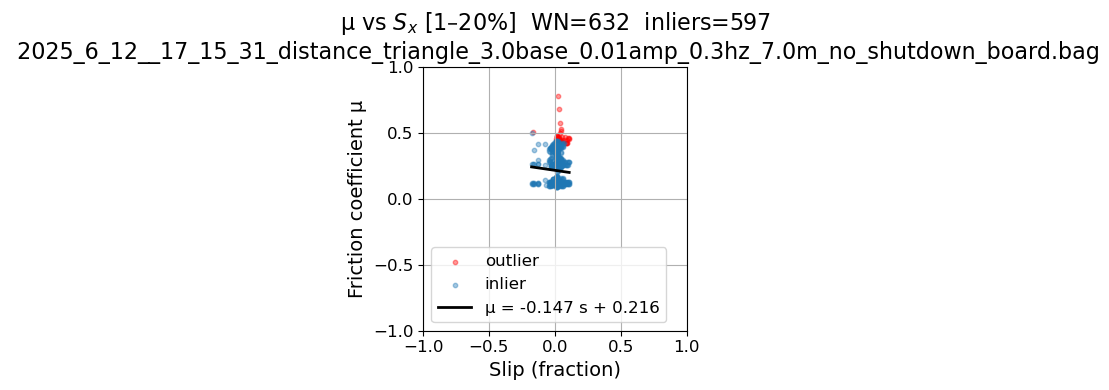

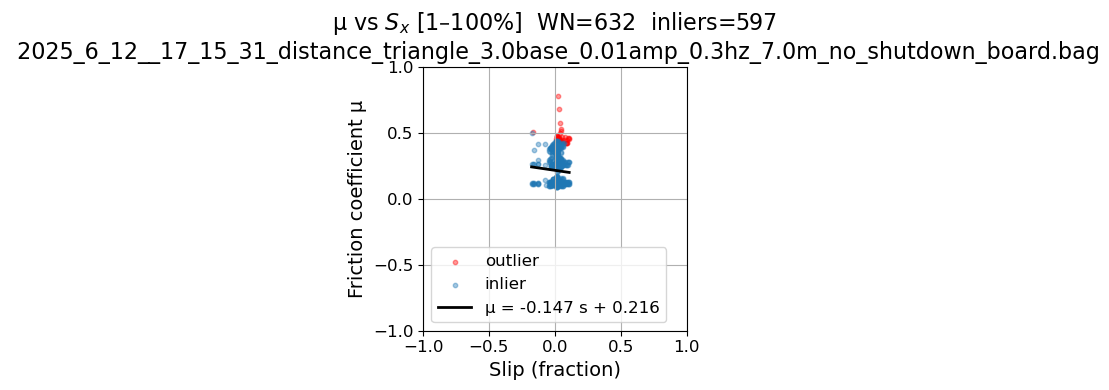

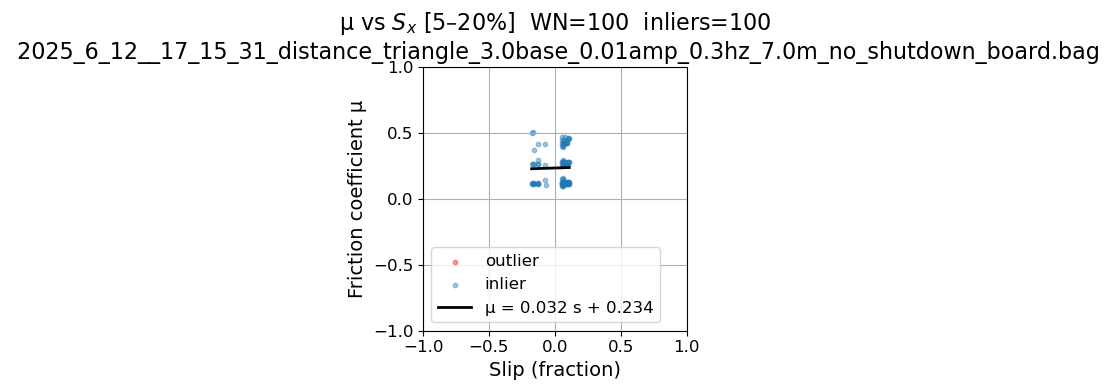

In [155]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import RANSACRegressor, LinearRegression
import statsmodels.api as sm
import sys
import os
import pickle
import pandas as pd


def slip_mu_ransac(
    mu_df: pd.DataFrame,
    slip_df: pd.DataFrame,
    pair_map: dict[str, str],
    *,
    mass: float = 40.0,
    radius: float = 0.127,
    slip_range: tuple[int, int] = (5, 100),
    max_trials: int = 100_000,
    random_state: int | None = 42,
    positive_only: bool = False,  # ← NEW ARG
    plot: bool = True,
    ax: plt.Axes | None = None,
    title: str | None = None,
    surface_name: str | None = None,
):
    """
    Robustly fit μ = k·s + b with RANSAC.

    positive_only
        True → keep only slip > 0 before fitting/plotting.
    """
    # ---------- align & filter --------------------------------------------
    if isinstance(slip_df.columns, pd.MultiIndex):
        slip_df = slip_df.droplevel(0, axis=1)

    frames = []
    for mu_col, sl_col in pair_map.items():
        μ = mu_df[mu_col].reindex(slip_df.index).interpolate("index")
        frames.append(pd.DataFrame({"slip_pct": slip_df[sl_col], "mu": μ}))

    df = (
        pd.concat(frames)
        .dropna()
        .query("mu.between(-1.5, 1.5)")
        .query("slip_pct.abs().between(@slip_range[0], @slip_range[1])")
    )
    df["slip_frac"] = df["slip_pct"] / 100.0

    if positive_only:  # ← keep only s > 0
        df = df[df["slip_frac"] > 0]

    if df.empty:
        raise ValueError("No data left after filtering.")

    n_total = len(df)

    # ---------- RANSAC -----------------------------------------------------
    X = df["slip_frac"].to_numpy()[:, None]
    y = df["mu"].to_numpy()

    lin = LinearRegression().fit(X, y)
    mad = np.median(np.abs(y - lin.predict(X)))
    thr = max(3 * mad, 1e-6)

    ransac = RANSACRegressor(
        LinearRegression(),
        residual_threshold=thr,
        max_trials=max_trials,
        random_state=random_state,
    ).fit(X, y)

    inliers = ransac.inlier_mask_
    n_in = int(inliers.sum())
    X_in, y_in = X[inliers], y[inliers]

    ols = sm.OLS(y_in, sm.add_constant(X_in)).fit()
    ci = ols.conf_int(alpha=0.00)
    resid_std = np.sqrt(ols.mse_resid)

    k, b = ransac.estimator_.coef_[0], ransac.estimator_.intercept_

    # ---------- plot -------------------------------------------------------
    fig = None
    if plot:
        if ax is None:
            fig, ax = plt.subplots(figsize=(6, 4))
        else:
            fig = ax.figure

        max_pts = 600
        in_idx, out_idx = np.flatnonzero(inliers), np.flatnonzero(~inliers)
        in_plot = np.random.choice(in_idx, min(len(in_idx), max_pts), False)
        out_plot = np.random.choice(out_idx, min(len(out_idx), max_pts), False)

        ax.scatter(X[out_plot], y[out_plot], c="red", s=10, alpha=0.4, label="outlier")
        ax.scatter(X[in_plot], y[in_plot], c="C0", s=10, alpha=0.4, label="inlier")

        xs = np.linspace(X_in.min(), X_in.max(), 200)[:, None]
        ax.plot(xs, ransac.predict(xs), "k-", lw=2, label=f"μ = {k:.3f} s + {b:.3f}")

        ax.set_xlabel("Slip (fraction)")
        ax.set_ylabel("Friction coefficient μ")
        ax.set_xlim(-1, 1)
        ax.set_ylim(-1, 1)
        ax.set_aspect("equal", adjustable="box")
        ax.grid(True)
        ax.legend()

        min_s, max_s = slip_range
        base = f"{surface_name} " if surface_name else ""
        tag = " (slip>0)" if positive_only else ""
        auto_title = f"{base}μ vs $S_x$ [{min_s}–{max_s}%]  WN={n_total}  inliers={n_in}{tag}\n {metadata['plot_subtitle']}"
        ax.set_title(title or auto_title)
        fig.tight_layout()

    return {
        "slope": k,
        "intercept": b,
        "ci_slope": tuple(ci[1]),
        "ci_intercept": tuple(ci[0]),
        "resid_std": resid_std,
        "inlier_frac": inliers.mean(),
        "paired": df,
        "inlier_mask": inliers,
        "figure": fig,
    }



# Combine Everything
pair_map = {
    "left_front_torque": "fl_vx",
    "right_front_torque": "fr_vx",
    "left_back_torque": "bl_vx",
    "right_back_torque": "br_vx",
}

torq_df = final_df["motor_torques_combined"][pair_map.keys()]

mu_df = (torq_df / radius) / F_N  # dimensionless μ
slip_df = final_df["slip_unbiased"]

if isinstance(slip_df.columns, pd.MultiIndex):
    slip_df = slip_df.droplevel(0, axis=1)
slip_df = slip_df[list(pair_map.values())]


slip_ranges = [
    # (5, 100),
    # (5, 100),
    # (2, 100),
    # (1, 5),
    # (1, 20),
    # (5, 40),
    # (0.01, 5),
    (1, 20),
    (1, 100),
    (5, 20),
]
slope_vals = {}

# Plot with all the data
for min_s, max_s in slip_ranges:
    # slip_mu_ransac_plotly_3d(
    output = slip_mu_ransac(
    # slip_mu_mean_line(
        mu_df=mu_df.sort_index(),
        slip_df=slip_df.sort_index(),
        pair_map=pair_map,
        slip_range=(min_s, max_s),
        surface_name=metadata['surface_name'],
        positive_only=False,
        # wrap_abs=True,
        # spline_s=.8
    )
    plt.savefig(f'{metadata["artifact_dir"]}/slip_slope_mins_{min_s}_maxs_{max_s}.png', dpi=200, bbox_inches="tight")
    slope_vals[f'{min_s}_{max_s}'] = output


<>:224: SyntaxWarning: invalid escape sequence '\i'
<>:224: SyntaxWarning: invalid escape sequence '\i'
/tmp/ipykernel_1588099/3793775071.py:224: SyntaxWarning: invalid escape sequence '\i'
  auto_title = f"{base}μ vs $S_x$ $\in$ [{min_s}–{max_s}%]\n  N={n_total}  inliers={n_in}"


[idx-check] mu_df: Index, len=649, dups=False, mono=True
[idx-check] slip_df: Index, len=649, dups=False, mono=True
[missing-pre] left_front_torque: 0/649 NaNs after reindex
[missing-post] left_front_torque: 0 NaNs after interpolate → DataFrame
[missing-pre] right_front_torque: 0/649 NaNs after reindex
[missing-post] right_front_torque: 0 NaNs after interpolate → DataFrame
[missing-pre] left_back_torque: 0/649 NaNs after reindex
[missing-post] left_back_torque: 0 NaNs after interpolate → DataFrame
[zap] removing 606 rows at slip=0
[slice-trim] removed 1 vertical μ outliers
[subsample] removed 7 overrepresented rows
Initial MAD: 0.0443, Threshold: 0.5000
[ransac] inliers =     17 / 17 (100.00%)   k=0.2117   b=0.1881
[saved] figures/_5-20pct_20250630_040909.png


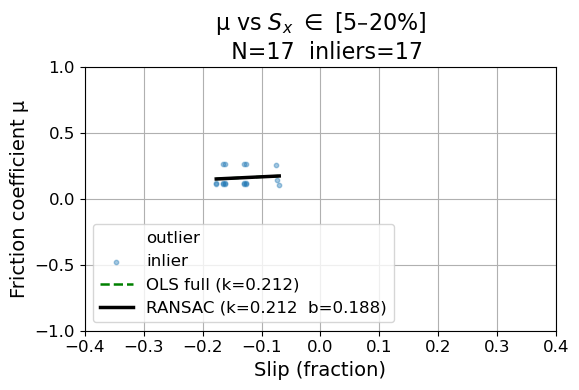

In [156]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import RANSACRegressor, LinearRegression
import statsmodels.api as sm
import sys
import os
import pickle
import plotly.graph_objects as go
from scipy.interpolate import UnivariateSpline


def slip_mu_ransac(
    mu_df: pd.DataFrame,
    slip_df: pd.DataFrame,
    pair_map: dict[str, str],
    *,
    mass: float = 40.279,
    radius: float = 0.127,
    slip_range: tuple[int, int] = (5, 100),
    max_trials: int = 100_000,
    random_state: int | None = 42,
    slip_sign: str = 'any',  # ← NEW ARG
    plot: bool = True,
    ax: plt.Axes | None = None,
    title: str | None = None,
    surface_name: str | None = None,
):
    """
    Robustly fit μ = k·s + b with RANSAC.
    """
    # ── BASIC INDEX SANITY ──────────────────────────────────────
    for name, tbl in {"mu_df": mu_df, "slip_df": slip_df}.items():
        idx = tbl.index
        print(
            f"[idx-check] {name}: {type(idx).__name__}, "
            f"len={len(idx)}, dups={idx.has_duplicates}, "
            f"mono={idx.is_monotonic_increasing}"
        )

    # ---------- align & filter --------------------------------------------
    if isinstance(slip_df.columns, pd.MultiIndex):
        slip_df = slip_df.droplevel(0, axis=1)

    frames = []
    for mu_col, sl_col in pair_map.items():
        μ = mu_df[mu_col].reindex(slip_df.index).interpolate("index")
        # ── INTERPOLATION DIAGNOSTICS ───────────────────────────
        n_missing = μ.isna().sum()
        print(f"[missing-pre] {mu_col}: {n_missing}/{len(μ)} NaNs after reindex")
        frames.append(pd.DataFrame({"slip_pct": slip_df[sl_col], "mu": μ}))
        post_interp_missing = frames[-1]["mu"].isna().sum()
        print(f"[missing-post] {mu_col}: {post_interp_missing} NaNs after interpolate → DataFrame")

    df = pd.concat(frames).dropna()

    df["slip_frac"] = df["slip_pct"] / 100.0

    if slip_sign == 'any':
        df["slip_frac"] = df["slip_frac"].abs()

    zero_rows = df["slip_frac"] == 0
    if zero_rows.any():
        print(f"[zap] removing {zero_rows.sum()} rows at slip=0")
        df = df[~zero_rows]





    bin_w = 0.01                          # 1 % slip bins
    edges = np.arange(df.slip_frac.min(), df.slip_frac.max() + bin_w, bin_w)
    df["bin"] = pd.cut(df.slip_frac, edges, right=False)

    def iqr_trim(group, fence=1.5):
        q1, q3 = group["mu"].quantile([0.25, 0.75])
        iqr = q3 - q1
        lo, hi = q1 - fence * iqr, q3 + fence * iqr
        return group[(group["mu"] >= lo) & (group["mu"] <= hi)]

    before = len(df)
    df = (
        df.groupby("bin", group_keys=False, observed=True)
        .apply(iqr_trim)
        .drop(columns="bin")
    )
    print(f"[slice-trim] removed {before - len(df):,} vertical μ outliers")
    n_total = len(df)          # update for later printout



    # ── inside slip_mu_ransac, after `df = pd.concat(frames).dropna()` ───────
    chk = df.groupby("slip_frac")["mu"].nunique()
    perm = chk[chk > 1]
    if not perm.empty:
        clash = perm.index[:5].to_list()
        print(
            f"[pair-clash] {len(perm)} slip values map to >1 μ "
            f"(e.g. {clash}) – time alignment is borked"
        )


    if slip_sign == "pos":
        df = df[df["slip_pct"] > 0]
    elif slip_sign == "neg":
        df = df[df["slip_pct"] < 0]
    elif slip_sign == "any":
        df["slip_frac"] = df["slip_frac"].abs()
        df["mu"] = df["mu"].abs()



    # Subsample 2D bins to reduce overrepresented μ bands
    df["μ_bin"] = pd.cut(df["mu"], bins=np.linspace(-1.5, 1.5, 100))
    df["s_bin"] = pd.cut(df["slip_frac"], bins=np.linspace(df["slip_frac"].min(), df["slip_frac"].max(), 100))

    def balanced_subsample(group, max_per_bin=20):
        if len(group) > max_per_bin:
            return group.sample(n=max_per_bin, random_state=42)
        return group

    before = len(df)
    df = (
        df.groupby(["μ_bin", "s_bin"], group_keys=False, observed=True)
        .apply(balanced_subsample)
        .drop(columns=["μ_bin", "s_bin"])
    )
    print(f"[subsample] removed {before - len(df):,} overrepresented rows")



    df = df.query("mu.between(-1.5, 1.5)")
    df = df[df["slip_frac"].abs().between(slip_range[0] / 100, slip_range[1] / 100)]
    if df.empty:
        raise ValueError("No data left after filtering.")
    n_total = len(df)


    # ---------- RANSAC -----------------------------------------------------
    X = df["slip_frac"].to_numpy()[:, None]
    y = df["mu"].to_numpy()

    lin = LinearRegression().fit(X, y)
    mad = np.median(np.abs(y - lin.predict(X)))
    # thr = max(3 * mad, 1e-6)
    thr = 0.5
    print(f"Initial MAD: {mad:.4f}, Threshold: {thr:.4f}")

    ransac = RANSACRegressor(
        LinearRegression(),
        residual_threshold=thr,
        max_trials=max_trials,
        random_state=random_state,
    ).fit(X, y)

    inliers = ransac.inlier_mask_

    n_in = int(inliers.sum())
    X_in, y_in = X[inliers], y[inliers]

    ols = sm.OLS(y_in, sm.add_constant(X_in)).fit()
    ci = ols.conf_int(alpha=0.05)
    resid_std = np.sqrt(ols.mse_resid)

    k, b = ransac.estimator_.coef_[0], ransac.estimator_.intercept_

    print(
        f"[ransac] inliers = {inliers.sum():>6} / {len(inliers)} "
        f"({inliers.mean():.2%})   k={k:.4f}   b={b:.4f}"
    )


    # ---------- plot -------------------------------------------------------
    fig = None
    if plot:
        if ax is None:
            fig, ax = plt.subplots(figsize=(6, 4))
        else:
            fig = ax.figure

        # --- sample points -------------------------------------------------
        max_pts = 500
        in_idx, out_idx = np.flatnonzero(inliers), np.flatnonzero(~inliers)
        in_plot = np.random.choice(in_idx, min(len(in_idx), max_pts), False)
        out_plot = np.random.choice(out_idx, min(len(out_idx), max_pts), False)

        ax.scatter(X[out_plot], y[out_plot], c="red", s=10, alpha=0.0, label="outlier")
        ax.scatter(X[in_plot], y[in_plot], c="C0", s=10, alpha=0.4, label="inlier")

        # --- x-grid for lines ---------------------------------------------
        x_grid = np.linspace(X.min(), X.max(), 200)[:, None]

        # 1) ordinary least-squares on *all* points (pre-RANSAC line)
        lin = LinearRegression().fit(X, y)  # safe even if fit earlier
        ax.plot(
            x_grid,
            lin.predict(x_grid),
            "g--",
            lw=1.8,
            label=f"OLS full (k={lin.coef_[0]:.3f})",
        )

        # 2) robust RANSAC line (post-RANSAC)
        ax.plot(
            x_grid,
            ransac.predict(x_grid),
            "k-",
            lw=2.5,
            label=f"RANSAC (k={k:.3f}  b={b:.3f})",
        )

        # --- cosmetics -----------------------------------------------------
        ax.set_xlabel("Slip (fraction)")
        ax.set_ylabel("Friction coefficient μ")
        ax.grid(True)
        ax.legend()

        min_s, max_s = slip_range
        ax.set_xlim(-max_s * 0.01 - 0.2, max_s * 0.01 + 0.2)
        ax.set_ylim(-1, 1)

        base = f"{surface_name} " if surface_name else ""
        tag = " (slip>0)" if slip_sign else ""
        auto_title = f"{base}μ vs $S_x$ $\in$ [{min_s}–{max_s}%]\n  N={n_total}  inliers={n_in}"
        ax.set_title(title or auto_title)
        fig.tight_layout()

        timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
        out_dir = "figures"
        os.makedirs(out_dir, exist_ok=True)

        filename = f"{surface_name.lower()}_{min_s}-{max_s}pct_{timestamp}.png"
        save_path = os.path.join(out_dir, filename)

        fig.savefig(save_path, dpi=300)
        print(f"[saved] {save_path}")

    return {
        "slope": k,
        "intercept": b,
        "ci_slope": tuple(ci[1]),
        "ci_intercept": tuple(ci[0]),
        "resid_std": resid_std,
        "inlier_frac": inliers.mean(),
        "paired": df,
        "inlier_mask": inliers,
        "figure": fig,
    }





# robot & patch parameters
mass = 40.279  # kg
F_N_net = 9.81 * mass  # total normal force (N)
F_N = F_N_net / 4  # per patch
radius = 0.127  # m

summary = []



# Combine Everything
pair_map = {
    "left_front_torque": "fl_vx",
    "right_front_torque": "fr_vx",
    "left_back_torque": "bl_vx",
    # "right_back_torque": "br_vx",
}


torq_df = final_df["motor_torques_combined"][pair_map.keys()]

mu_df = (torq_df / radius) / F_N  # dimensionless μ
slip_df = final_df["slip_unbiased"]

if isinstance(slip_df.columns, pd.MultiIndex):
    slip_df = slip_df.droplevel(0, axis=1)
slip_df = slip_df[list(pair_map.values())]

all_mu = mu_df.sort_index()
all_slip = slip_df.sort_index()



slip_ranges = [
    # (1, 5),
    # (0.1, 5),
    (5, 20),
    # (2, 100),
    # (3, 100),
    # (4, 100),
    # (5,20),
    # (1,20),
    # (5,100),
    # (1, 5),
    # (4, 20),
    # (1, 2),
    # (0.1, 1),
    # (1, 30),
    # (5, 80),
]

# fig, axes = plt.subplots(2, 2, figsize=(12, 10), sharex=True, sharey=True)
# fig.suptitle(f"{surface}: RANSAC fits for slip range {min_s}%–{max_s}%", fontsize=16)

# for min_s, max_s in slip_ranges:
#     results = {}
#     # iterate wheels & corresponding axes
#     for ax, (mu_col, sl_col) in zip(axes.flatten(), pair_map.items()):
#         # single‐wheel pair_map
#         single_map = {mu_col: sl_col}
#         res = slip_mu_ransac(
#             mu_df=all_mu.sort_index(),
#             slip_df=all_slip.sort_index(),
#             pair_map=single_map,
#             slip_range=(min_s, max_s),
#             # positive_only=True,
#             plot=True,
#             ax=ax,
#             title=mu_col  # wheel name as subplot title
#         )
#         results[mu_col] = res


# Plot with all the data
for min_s, max_s in slip_ranges:
    # slip_mu_ransac_plotly_3d(
    slip_mu_ransac(
        # slip_mu_mean_line(
        mu_df=all_mu.sort_index(),
        slip_df=all_slip.sort_index(),
        pair_map=pair_map,
        slip_range=(min_s, max_s),
        surface_name=metadata['surface_name'],
        slip_sign='neg'
        # positive_only=True,
        # smooth=True,
        # wrap_abs=True,
        # n_bins=30,
        # spline_s=.05
    )


In [157]:
# final_df['slip_unbiased'].iloc[0,:]
# final_df['left_motor_torques'].plot()
# final_df['slip_unbiased']

In [158]:
# # robot & patch parameters
# mass    = 40.0         # kg
# F_N_net = 9.81 * mass  # total normal force
# F_N     = F_N_net / 4  # per patch
# radius  = 0.127        # m

# # # 1) Combine left+right motor torques into one DataFrame of shape (N×4)
# # torque_df = pd.concat([
# #     final_df['left_motor_torques'],
# #     final_df['right_motor_torques']
# # ], axis=1)
# # # display(torque_df)
# # # torque_df.plot()


# torque_df = pd.concat([
#     final_df["left_motor_torques"],
#     final_df["right_motor_torques"],
# ], axis=1)  # NO dropna here!
# mu = torque_df / 0.127                   # τ/r
# mu = mu / (9.81 * 40.0 / 4)              # normalize

# # 2) compute friction force and mu
# # F_fric = torque_df / radius         # N = τ/r
# # mu     = F_fric / F_N               # μ = F_fric / F_N
# display(mu)

# # slip_df = final_df['slip_unbiased']
# # display(slip_df)
# slip_grp = final_df["slip_unbiased"]
# if isinstance(slip_grp.columns, pd.MultiIndex):
#     slip_df = slip_grp.droplevel(0, axis=1)
# else:
#     slip_df = slip_grp.copy()

# slip_s = slip_df.stack(dropna=False).rename("slip_pct")
# mu_s   = mu   .stack(dropna=False).rename("mu")

# # 1) stack & align into one DataFrame
# # slip_s = slip_df.stack().rename("slip_pct")
# # mu_s   = mu    .stack().rename("mu")
# display(slip_s,mu_s)

# # 3) Build a joint DataFrame of 4×N rows
# df_pairs = pd.concat([slip_s, mu_s], axis=1).dropna()

# # 4) Now mask to keep only rows where both slip AND mu exist
# mask = df_pairs["slip_pct"].notna() & df_pairs["mu"].notna()
# df_valid = df_pairs.loc[mask]

# print("Total pairs before mask:", len(df_pairs))
# print("Valid pairs after mask:",  len(df_valid))

# # df_pairs = pd.concat([slip_s, mu_s], axis=1, join="inner")
# display(df_pairs)
# print("All pairs (incl. NaNs):", len(df_pairs))

# # df_pairs = df_pairs.dropna()
# print("Valid (slip,μ) after dropna:", len(df_pairs))
# display(df_pairs.head())

# # 2) if no data, either abort or fallback
# if df_pairs.empty:
#     raise RuntimeError(
#         "No overlapping slip/μ data to fit! "
#         "Try loosening your epsilon or using a fixed time window."
#     )

# # 3) convert & fit
# df_pairs["slip_frac"] = df_pairs["slip_pct"] / 100.0
# k, b = np.polyfit(df_pairs["slip_frac"], df_pairs["mu"], 1)
# print(f"k = {k:.3f}, b = {b:.3f}")

# # 4) plot
# plt.scatter(df_pairs["slip_frac"], df_pairs["mu"], alpha=0.3, s=10)
# xs = np.linspace(df_pairs["slip_frac"].min(), df_pairs["slip_frac"].max(), 200)
# plt.plot(xs, k*xs + b, "r-", lw=2)
# plt.xlabel("Slip (fraction)")
# plt.ylabel("Friction μ")
# plt.title(f"μ vs Slip Fraction\nk = {k:.3f}")
# plt.grid(True)
# plt.show()


In [159]:
# # robot & patch parameters
# mass = 40.0  # kg
# F_N_net = 9.81 * mass  # total normal force (N)
# F_N = F_N_net / 4  # per patch
# radius = 0.127  # m

# min_s = 1
# max_s = 50

# # ------------------------------------------------------------
# # 0)  define how the torque columns map to the slip columns
# # ------------------------------------------------------------
# pair_map = {  # torque_col       →   slip_col
#     "left_front_torque": "fl_vx",
#     "right_front_torque": "fr_vx",
#     "left_back_torque": "bl_vx",
#     "right_back_torque": "br_vx",
# }

# # ------------------------------------------------------------
# # 1)  build μ  (same units, same index as torque)
# # ------------------------------------------------------------
# torq_df = final_df["motor_torques_combined_filtered"][pair_map.keys()]  # keep only 4 wanted cols
# mu_df = (torq_df / radius) / F_N  # dimensionless μ

# # ------------------------------------------------------------
# # 2)  slice slip table to the 4 matching cols
# # ------------------------------------------------------------
# slip_df = final_df["slip_unbiased"]
# assert slip_df.index.is_monotonic_increasing


# if isinstance(slip_df.columns, pd.MultiIndex):
#     slip_df = slip_df.droplevel(0, axis=1)
# slip_df = slip_df[list(pair_map.values())]  # ['fl_vx','fr_vx',...]

# # ------------------------------------------------------------
# # 3)  align timestamps, join each wheel’s pair
# # ------------------------------------------------------------
# records = []
# for tq_col, sl_col in pair_map.items():
#     # interpolate torque to slip times so shapes match
#     mu_align = mu_df[tq_col].reindex(slip_df.index).interpolate("index")

#     # collect rows where both are finite
#     pair = pd.DataFrame(
#         {
#             "wheel": sl_col[:-3],  # 'fl','fr','bl','br'
#             "slip_pct": slip_df[sl_col],
#             "mu": mu_align,
#         }
#     ).dropna()

#     records.append(pair)

# paired = pd.concat(records, ignore_index=True)

# # Clip?
# paired = paired[paired["mu"].between(-1.5, 1.5)]


# # Mask out slip values outside range.
# paired = paired[paired["slip_pct"].abs().between(min_s, max_s)]

# paired["slip_frac"] = paired["slip_pct"] / 100.0
# print("sample rows:", len(paired))

# # ------------------------------------------------------------
# # 4)  line fit   μ = k·s + b
# # ------------------------------------------------------------
# k, b = np.polyfit(paired["slip_frac"], paired["mu"], 1)
# final_vals['f"/{k}_all_slip_slope_min_{min_s}_max{max_s}'] = k
# print(f"k = {k:.3f},  b = {b:.3f}")

# # ------------------------------------------------------------
# # 5)  scatter
# # ------------------------------------------------------------
# plt.figure(figsize=(8, 6))
# plt.scatter(paired["slip_frac"], paired["mu"], s=10, alpha=0.3)
# x = np.linspace(paired["slip_frac"].min(), paired["slip_frac"].max(), 200)
# plt.plot(x, k * x + b, "r-", lw=2,label=f"μ = {k:.3f}s + {b:.3f}")
# plt.xlabel("Slip (fraction)")
# plt.title(f'Slip-Slope \n $s \\in [{min_s},{max_s}]\\%$,   $k =${k:.3f}   \n{metadata['plot_subtitle']}')
# # plt.title(f'Slip-Slope \n $s \\in [{min_s},{max_s}]\\%$,   $k =${k:.3f}    \n{metadata['plot_subtitle']}')
# plt.ylabel(ylabel="μ")
# plt.grid(True)
# plt.tight_layout()
# plt.axis("square")                     
# # plt.ylim((-.5,.5))
# plt.legend()

# plt.gcf().savefig(metadata['artifact_dir'] + f"/{k}_all_slip_slope_min_{min_s}_max{max_s}.png", dpi=300, bbox_inches="tight")

# plt.show()


In [160]:
# # robot & patch parameters
# mass = 40.0  # kg
# F_N_net = 9.81 * mass  # total normal force (N)
# F_N = F_N_net / 4  # per patch
# radius = 0.127  # m

# min_s = 1
# max_s = 50

# # ------------------------------------------------------------
# # 0)  define how the torque columns map to the slip columns
# # ------------------------------------------------------------
# pair_map = {  # torque_col       →   slip_col
#     "left_front_torque": "fl_vx",
#     "right_front_torque": "fr_vx",
#     "left_back_torque": "bl_vx",
#     "right_back_torque": "br_vx",
# }

# # ------------------------------------------------------------
# # 1)  build μ  (same units, same index as torque)
# # ------------------------------------------------------------
# torq_df = final_df["motor_torques_combined"][pair_map.keys()]
# mu_df = (torq_df / radius) / F_N  # dimensionless μ

# # ------------------------------------------------------------
# # 2)  slice slip table to the 4 matching cols
# # ------------------------------------------------------------
# slip_df = final_df["slip_unbiased"]
# assert slip_df.index.is_monotonic_increasing

# if isinstance(slip_df.columns, pd.MultiIndex):
#     slip_df = slip_df.droplevel(0, axis=1)
# slip_df = slip_df[list(pair_map.values())]

# # ------------------------------------------------------------
# # 3)  align timestamps, join each wheel’s pair
# # ------------------------------------------------------------
# records = []
# for tq_col, sl_col in pair_map.items():
#     mu_align = mu_df[tq_col].reindex(slip_df.index).interpolate("index")

#     pair = pd.DataFrame(
#         {
#             "wheel": sl_col[:-3],
#             "slip_pct": slip_df[sl_col],
#             "mu": mu_align,
#         }
#     ).dropna()

#     records.append(pair)

# paired = pd.concat(records, ignore_index=True)

# # ------------------------------------------------------------
# # 4)  keep only strictly positive slip and μ
# # ------------------------------------------------------------
# paired = paired[(paired["slip_pct"] > 0) & (paired["mu"] > 0)]

# # Clip to reasonable range for μ
# paired = paired[paired["mu"].between(0, 1.5)]

# # Filter slip within range (1–50%)
# paired = paired[paired["slip_pct"].between(min_s, max_s)]

# paired["slip_frac"] = paired["slip_pct"] / 100.0
# print("sample rows:", len(paired))

# # ------------------------------------------------------------
# # 5)  line fit   μ = k·s + b
# # ------------------------------------------------------------
# k, b = np.polyfit(paired["slip_frac"], paired["mu"], 1)
# print(f"k = {k:.3f},  b = {b:.3f}")
# final_vals['f"/{k}_pos_slip_slope_min_{min_s}_max{max_s}'] = k

# # ------------------------------------------------------------
# # 6)  scatter
# # ------------------------------------------------------------
# plt.figure(figsize=(6, 4))
# plt.scatter(paired["slip_frac"], paired["mu"], s=10, alpha=0.3)
# x = np.linspace(paired["slip_frac"].min(), paired["slip_frac"].max(), 200)
# plt.plot(x, k * x + b, "r-", lw=2, label=f"μ = {k:.3f}s + {b:.3f}")
# plt.xlabel("Slip (fraction)")
# plt.title(f'Slip-Slope \n $s \\in [{min_s},{max_s}]\\%$,   $k =${k:.3f}   \n{metadata["plot_subtitle"]}')
# plt.ylabel("μ")
# plt.grid(True)
# plt.tight_layout()
# plt.axis("square")                     

# # plt.ylim((-.5, .5))
# # plt.xlim((0.01*min_s,0.01*max_s))
# plt.legend()

# plt.gcf().savefig(metadata['artifact_dir'] + f"/{k}_pos_slip_slope_min_{min_s}_max{max_s}.png", dpi=300, bbox_inches="tight")
# plt.show()




In [161]:
# """
# Scatter the motor torques and slip_unbiased against each other. They should form
# a nice guassianish 2D distribution aroudn zero with a positive slip, the
# slip-slope.
# """

# # robot & patch parameters
# mass = 40.0  # kg
# F_N_net = 9.81 * mass  # total normal force (N)
# F_N = F_N_net / 4  # per patch
# radius = 0.127  # m
# min_s =5
# max_s = 20

# # 1) Compute μ for each patch from motor torques
# # torque_df = pd.concat([
# #     final_df["left_motor_torques"],
# #     final_df["right_motor_torques"],
# # ], axis=1)

# motor_torques_combined = final_df["motor_torques_combined"]
# mu = motor_torques_combined / radius  # τ → force
# mu = mu / F_N  # normalize by normal force


# # 2) Get your bias-corrected slip (dropping top level if needed)
# slip_grp = final_df["slip_unbiased"]
# if isinstance(slip_grp.columns, pd.MultiIndex):
#     slip_df = slip_grp.droplevel(0, axis=1)
# else:
#     slip_df = slip_grp.copy()

# # 3) Reindex μ to the same timestamps as slip_df, interpolating
# mu_aligned = mu.reindex(index=slip_df.index).interpolate(method="index")

# # 4) Flatten both into 1D arrays and mask out NaNs
# slip_flat = slip_df.values.flatten()
# mu_flat = mu_aligned.values.flatten()
# mask = (~np.isnan(slip_flat)) & (~np.isnan(mu_flat))
# slip_frac = slip_flat[mask] / 100.0  # percent → fraction
# mu_clean = mu_flat[mask]

# print(f"Data points used in fit: {len(slip_frac)}")



# # optional: keep only 5 – 20 % slip
# paired = paired[paired["slip_pct"].abs().between(min_s, max_s)]

# paired["slip_frac"] = paired["slip_pct"] / 100.0
# print("sample rows:", len(paired))



# # 5) Fit μ = k·s + b
# k, b = np.polyfit(slip_frac, mu_clean, 1)
# print(f"Estimated slope k = {k:.3f}, intercept b = {b:.3f}")

# # 6) Plot
# plt.figure()
# plt.scatter(slip_frac, mu_clean, alpha=0.3, s=10, label="data")
# xs = np.linspace(slip_frac.min(), slip_frac.max(), 200)
# plt.plot(xs, k * xs + b, "r-", lw=2, label=f"μ = {k:.3f}s + {b:.3f}")
# plt.xlabel("Slip (fraction)")
# plt.ylabel("Friction coefficient μ")
# # plt.title(f"μ vs Slip Fraction\nk = {k:.3f}")
# # plt.title(f"μ vs Slip Fraction\nk = {k:.3f} \n{metadata['bag_path']=}")
# plt.title(f'Slip-Slope \n $s \\in [{min_s},{max_s}]\\%$,   $k =${k:.3f}    \n{metadata['plot_subtitle']}')
# plt.legend()
# plt.grid(True)
# plt.show()


In [162]:
# # Use ABS and only remove greater?

# import numpy as np
# import matplotlib.pyplot as plt
# from sklearn.covariance import MinCovDet
# from scipy.stats import chi2

# # Robot & patch parameters
# mass = 40.0  # kg
# F_N_net = 9.81 * mass
# F_N = F_N_net / 4
# radius = 0.127  # m

# min_s = 1
# max_s = 5

# slip_threshold = 0.05

# # 1) Compute μ for each patch
# motor_torques_combined = final_df["motor_torques_combined"]
# mu = motor_torques_combined / radius
# mu = mu / F_N

# # 2) Get bias-corrected slip
# slip_grp = final_df["slip_unbiased"]
# if isinstance(slip_grp.columns, pd.MultiIndex):
#     slip_df = slip_grp.droplevel(0, axis=1)
# else:
#     slip_df = slip_grp.copy()

# # 3) Reindex μ to slip_df index
# mu_aligned = mu.reindex(index=slip_df.index).interpolate(method="index")

# # 4) Flatten, drop NaNs, and take abs
# slip_flat = np.abs(slip_df.values.flatten())
# mu_flat = np.abs(mu_aligned.values.flatten())
# mask = (~np.isnan(slip_flat)) & (~np.isnan(mu_flat))
# slip_frac = slip_flat[mask] / 100.0
# mu_clean = mu_flat[mask]

# # 5) Filter slip > slip_threshold
# valid = slip_frac > slip_threshold
# slip_frac = slip_frac[valid]
# mu_clean = mu_clean[valid]

# print(f"Data points after slip > {slip_threshold}: {len(slip_frac)}")

# # 6) Mahalanobis-based outlier rejection
# data = np.column_stack((slip_frac, mu_clean))
# mcd = MinCovDet().fit(data)
# md2 = mcd.mahalanobis(data)
# alpha = 1
# threshold = chi2.ppf(alpha, df=2)
# inlier_mask = md2 <= threshold

# slip_in = slip_frac[inlier_mask]
# mu_in = mu_clean[inlier_mask]
# print(f"Retained {len(slip_in)} inliers out of {len(slip_frac)} points")

# # 7) Fit μ = k·s + b using inliers
# k, b = np.polyfit(slip_in, mu_in, 1)
# print(f"Estimated slope k = {k:.3f}, intercept b = {b:.3f}")

# # 8) Plot
# plt.figure()
# plt.scatter(slip_frac[~inlier_mask], mu_clean[~inlier_mask],
#             color="red", s=10, alpha=0.4, label="Outliers")
# plt.scatter(slip_in, mu_in,
#             color="C0", s=10, alpha=0.4, label="Inliers")
# xs = np.linspace(slip_in.min(), slip_in.max(), 200)
# plt.plot(xs, k * xs + b, "k-", lw=2, label=f"μ = {k:.3f}s + {b:.3f}")
# plt.xlabel("Slip (fraction)")
# plt.ylabel("Friction coefficient μ")
# plt.title(f"Slip-Slope \n $s \\in [{min_s},{max_s}]\\%$,   $k =${k:.3f}   \n{metadata['bag_path']=}")
# plt.legend()
# plt.ylim((-0.2,0.5))
# plt.grid(True)
# plt.axis("square")                     
# plt.tight_layout()
# plt.show()


In [163]:
# from sklearn.covariance import MinCovDet
# from scipy.stats import chi2
# import numpy as np
# import matplotlib.pyplot as plt

# """
# Try removing outliers from scatter.
# """


# def reject_bivariate_outliers(x: np.ndarray, y: np.ndarray, alpha: float = 0.99):
#     """
#     Return boolean mask of inliers for the 2-D sample (x,y).

#     alpha : keep points whose robust-Mahalanobis² ≤ chi2.ppf(alpha, df=2)
#             0.99 ⇒ ~1 % of ideal Gaussian data would be rejected.
#     """
#     data = np.column_stack([x, y])
#     mcd = MinCovDet().fit(data)  # robust location + cov
#     md2 = mcd.mahalanobis(data)  # squared Mahalanobis dist
#     thresh = chi2.ppf(alpha, df=2)  # χ² cutoff

#     plt.hist(md2, bins=200, log=True)
#     plt.axvline(thresh, color="r")
#     plt.title("Robust Mahalanobis² distribution")
#     return md2 <= thresh  # True = inlier


# # ----------------------------------------------------------------------
# # your existing flattened arrays
# mask_inlier = reject_bivariate_outliers(slip_frac, mu_clean, alpha=0.95)

# slip_in = slip_frac[mask_inlier]
# mu_in = mu_clean[mask_inlier]

# print(
#     f"kept {mask_inlier.sum()} / {len(mask_inlier)} points "
#     f"({mask_inlier.mean() * 100:.1f} % after outlier removal)"
# )

# # robust fit after outlier removal
# k, b = np.polyfit(slip_in, mu_in, 1)
# print(f"  k={k:.3f}, b={b:.3f}")

# # ----------------------------------------------------------------------
# # plotting: outliers in red, inliers in blue
# plt.figure(figsize=(6, 4))
# plt.scatter(
#     slip_frac[~mask_inlier], mu_clean[~mask_inlier], c="red", s=10, alpha=0.4, label="outlier"
# )
# plt.scatter(slip_in, mu_in, c="C0", s=10, alpha=0.4, label="inlier")
# xs = np.linspace(slip_in.min(), slip_in.max(), 200)
# plt.plot(xs, k * xs + b, "k-", lw=2, label=f"μ = {k:.3f}s + {b:.3f}")
# plt.xlabel("Slip (fraction)")
# plt.ylabel("μ")
# plt.legend()
# plt.grid(True)
# plt.tight_layout()
# plt.show()



# # Let's see what changing the rejection percentage does to the slope.
# # 90% seems to a sweet spot for 2Hz.
# for val in np.linspace(0.1, 1, 25):
#     mask_inlier = reject_bivariate_outliers(slip_frac, mu_clean, alpha=val)
#     slip_in = slip_frac[mask_inlier]
#     mu_in = mu_clean[mask_inlier]
#     k, b = np.polyfit(slip_in, mu_in, 1)
#     print(f"  k={k:.3f}, b={b:.3f} alpha={val:.2f}")


In [164]:
# """
# Try removing outliers from 2D distribution.
# """
# # ----------------------------------------------------------------------
# # 0) slip-range mask  : keep only 5 % ≤ |slip| ≤ 20 %
# low, high = 0.05, 0.20  # fractions (5–20 %)
# mask_range = (np.abs(slip_frac) >= low) & (np.abs(slip_frac) <= high)

# # 1) robust bivariate outlier mask (already have this)
# mask_maha = reject_bivariate_outliers(slip_frac, mu_clean, alpha=0.99)

# # 2) final inlier mask = logical AND
# mask_inlier = mask_range & mask_maha
# # ----------------------------------------------------------------------

# slip_in = slip_frac[mask_inlier]
# mu_in = mu_clean[mask_inlier]

# print(
#     f"kept {mask_inlier.sum()} / {len(mask_inlier)} points "
#     f"({mask_inlier.mean() * 100:.1f} % after both filters)"
# )

# # linear fit on the surviving points
# k, b = np.polyfit(slip_in, mu_in, 1)
# print(f"  k = {k:.3f},  b = {b:.3f}")

# # ----------------------------------------------------------------------
# # scatter plot: points rejected by *either* rule in red
# plt.figure(figsize=(6, 4))
# plt.scatter(
#     slip_frac[~mask_inlier], mu_clean[~mask_inlier], c="red", s=10, alpha=0.4, label="rejected"
# )
# plt.scatter(slip_in, mu_in, c="C0", s=10, alpha=0.4, label="kept")
# xs = np.linspace(low, high, 200)
# plt.plot(xs, k * xs + b, "k-", lw=2, label=f"μ = {k:.3f}s + {b:.3f}")
# plt.xlabel("Slip (fraction)")
# plt.ylabel("μ")
# plt.legend()
# plt.grid(True)
# plt.tight_layout()
# plt.show()


In [165]:
# import numpy as np
# import matplotlib.pyplot as plt
# from sklearn.covariance import MinCovDet
# from scipy.stats import chi2

# # 0) robot & patch parameters
# mass    = 40.0    # kg
# F_N     = 9.81 * mass / 4   # per patch
# radius  = 0.127  # m
# eps     = 0.2    # minimum wheel speed [m/s] to trust slip
# s_min, s_max = 0.01, 0.5   # 5–20% slip window

# # 1) Compute μ for each patch
# motor_torques_combined = final_df["motor_torques_combined"]
# mu = motor_torques_combined / radius / F_N         # DataFrame of μ

# # 2) Pull bias-corrected slip
# slip_grp = final_df["slip_unbiased"]
# if isinstance(slip_grp.columns, pd.MultiIndex):
#     slip_df = slip_grp.droplevel(0, axis=1)
# else:
#     slip_df = slip_grp.copy()

# # 3) Align μ to slip timestamps
# mu_aligned = mu.reindex(index=slip_df.index).interpolate(method="index")

# # 4) Flatten & mask NaNs
# slip_flat = slip_df.values.flatten()    # in %
# mu_flat   = mu_aligned.values.flatten()
# valid     = (~np.isnan(slip_flat)) & (~np.isnan(mu_flat))

# slip_frac = slip_flat[valid] / 100.0    # to fraction
# mu_clean  = mu_flat[valid]

# # 5) Apply slip range filter
# range_mask = (np.abs(slip_frac) >= s_min) & (np.abs(slip_frac) <= s_max)
# slip_frac = slip_frac[range_mask]
# mu_clean  = mu_clean[range_mask]
# print(f"Using {len(slip_frac)} points with {100*s_min:.0f}–{100*s_max:.0f}% slip")

# # 6) Robust Mahalanobis-based outlier rejection
# def reject_bivariate_outliers(x, y, alpha=0.90):
#     data   = np.column_stack([x, y])
#     mcd    = MinCovDet().fit(data)
#     md2    = mcd.mahalanobis(data)
#     thresh = chi2.ppf(alpha, df=2)
#     plt.figure()
#     plt.hist(md2, bins=200, log=True)
#     plt.axvline(thresh, color="r")
#     plt.title(f"Mahalanobis² dist, α={alpha}")
#     return md2 <= thresh

# alpha = 0.99
# mask_inlier = reject_bivariate_outliers(slip_frac, mu_clean, alpha=alpha)
# slip_in = slip_frac[mask_inlier]
# mu_in   = mu_clean[mask_inlier]
# print(f"Kept {mask_inlier.sum()} / {len(mask_inlier)} points ({mask_inlier.mean()*100:.1f}% inliers)")

# # 7) Fit and plot
# k = (slip_in @ mu_in) / (slip_in @ slip_in)
# b = 0.0
# print(f"Forced‐origin fit: μ = {k:.3f}·s")



# # 8) Plot
# plt.figure(figsize=(6,4))
# plt.scatter( slip_frac[~mask_inlier], mu_clean[~mask_inlier],
#              c="red",   s=10, alpha=0.4, label="outlier" )
# plt.scatter( slip_in, mu_in,
#              c="C0",    s=10, alpha=0.4, label="inlier" )
# xs = np.linspace(slip_in.min(), slip_in.max(), 200)
# plt.plot(xs, k*xs, "k-", lw=2, label=f"μ={k:.3f}s")
# plt.xlabel("Slip (fraction)")
# plt.ylabel("Friction coefficient μ")
# plt.title(f"Origin‐constrained μ vs Slip\nα={alpha}, {int(100*s_min)}–{int(100*s_max)}%   \n{metadata['plot_subtitle']}")
# plt.legend()
# plt.grid(True)
# plt.tight_layout()
# plt.gcf().savefig(metadata['artifact_dir'] + f"/{k}_remove_outlier_slip_slope_min_{min_s}_max{max_s}.png", dpi=300, bbox_inches="tight")

# plt.show()


# k, b = np.polyfit(slip_in, mu_in, 1)
# print(f"μ = {k:.3f} · s + {b:.3f}  (α={alpha})")

# plt.figure(figsize=(6,4))
# plt.scatter( slip_frac[~mask_inlier], mu_clean[~mask_inlier],
#              c="red",   s=10, alpha=0.4, label="outlier" )
# plt.scatter( slip_in, mu_in,
#              c="C0",    s=10, alpha=0.4, label="inlier" )
# xs = np.linspace(slip_in.min(), slip_in.max(), 200)
# plt.plot(xs, k*xs + b, "k-", lw=2, label=f"μ={k:.3f}s+{b:.3f}")
# plt.xlabel("Slip (fraction)")
# plt.ylabel("Friction coefficient μ")
# plt.title(f"μ vs Slip (α={alpha}, {int(100*s_min)}–{int(100*s_max)}%)")
# plt.legend()
# plt.grid(True)
# plt.tight_layout()
# plt.show()


In [166]:
# import numpy as np
# import matplotlib.pyplot as plt
# from scipy.stats import chi2

# # --- 0) user parameters ---
# s_low, s_high = 0.05, 0.20    # absolute slip bounds
# alpha        = 0.99           # Mahalanobis inlier fraction

# # --- assume slip_frac, mu_clean are defined as before ---

# # 1) slip‐range filter on both positive and negative bands
# band_mask = (
#     ((slip_frac >=  s_low) & (slip_frac <=  s_high)) |
#     ((slip_frac <= -s_low) & (slip_frac >= -s_high))
# )
# slip1 = slip_frac[band_mask]
# mu1   = mu_clean[band_mask]
# print(f"After slip‐range: {len(slip1)} points")

# # 2) build data matrix and covariance
# data = np.column_stack([slip1, mu1])
# C    = np.cov(data, rowvar=False)
# invC = np.linalg.inv(C)

# # 3) Mahalanobis² about the ORIGIN
# md2 = np.sum((data @ invC) * data, axis=1)
# th  = chi2.ppf(alpha, df=2)

# inlier_mask = md2 <= th
# slip_in = slip1[inlier_mask]
# mu_in   = mu1[inlier_mask]
# print(f"Kept {inlier_mask.sum()} / {len(inlier_mask)} (~{inlier_mask.mean()*100:.1f}% inliers)")

# # 4) origin‐constrained fit
# k = (slip_in @ mu_in) / (slip_in @ slip_in)
# print(f"Origin‐constrained slope: μ = {k:.3f} · slip")

# # 5) plot
# plt.figure(figsize=(6,6))
# plt.scatter(slip_frac, mu_clean,    c="lightgray", s=8, label="all data")
# plt.scatter(slip1,    mu1,          c="gray",      s=8, label="in slip-bands")
# plt.scatter(slip_in,  mu_in,        c="C0",        s=12, label="Mahalanobis inliers")
# xs = np.linspace(-s_high, s_high, 200)
# plt.plot(xs, k * xs, "k-", lw=2, label=f"μ = {k:.3f}·s")
# plt.axvline(-s_low, color="k", linestyle="--", alpha=0.5)
# plt.axvline( s_low, color="k", linestyle="--", alpha=0.5)
# plt.xlabel("Slip (fraction)")
# plt.ylabel("Friction coefficient μ")
# plt.title(f"Origin‐constrained fit on slip bands ±{int(s_low*100)}–{int(s_high*100)}% & α={alpha}")
# plt.legend()
# plt.grid(True)
# plt.show()


In [167]:
# import numpy as np
# import matplotlib.pyplot as plt
# from scipy.stats import chi2

# # --- parameters ---
# s_low, s_high = 0.1, 0.3    # only keep |slip| in [5%,20%]
# alpha         = 0.90          # Mahalanobis inlier fraction

# # assume slip_frac, mu_clean are already defined 1-D numpy arrays

# # 1) band-mask only the positive slip region
# pos_mask = (slip_frac >= s_low) & (slip_frac <= s_high)
# neg_mask = (slip_frac <= -s_low) & (slip_frac >= -s_high)
# print("positive count:", np.count_nonzero(pos_mask),
#       "negative count:", np.count_nonzero(neg_mask))

# # 2) choose whether you want just positive, just negative, or both
# #    for now let’s do both:
# band_mask = pos_mask | neg_mask
# slip1 = slip_frac[band_mask]
# mu1   = mu_clean[band_mask]

# # 3) Mahalanobis-inliers about the origin
# data = np.column_stack([slip1, mu1])
# C    = np.cov(data, rowvar=False)
# invC = np.linalg.inv(C)
# md2  = np.sum((data @ invC) * data, axis=1)
# th   = chi2.ppf(alpha, df=2)
# inlier = md2 <= th

# slip_in = slip1[inlier]
# mu_in   = mu1[inlier]
# print(f"Total inliers: {inlier.sum()} / {len(inlier)}")

# # 4) Quick inspect of sign distribution
# print("slip_in signs:", np.sign(slip_in)[:10])
# print("mu_in head:", mu_in[:10])

# # 5) Compute numerator & denominator
# num = slip_in @ mu_in
# den = slip_in @ slip_in
# print("numerator =", num)
# print("denominator =", den)

# # 6) naive origin-fit
# k_raw = num / den
# print("raw k =", k_raw)

# # 7) Plot to see where the “bad” points are
# plt.figure(figsize=(6,6))
# plt.scatter(slip_frac, mu_clean,    c="lightgray", s=6, label="all data")
# plt.scatter(slip1,    mu1,          c="gray",      s=8, label="in slip-bands")
# plt.scatter(slip_in,  mu_in,        c="C0",        s=12, label="Mahalanobis inliers")
# xs = np.linspace(-s_high, s_high, 200)
# plt.plot(xs, k_raw*xs, "k-", lw=2, label=f"raw k={k_raw:.3f}")
# plt.axvline(-s_low, color="k", ls="--", alpha=0.5)
# plt.axvline( s_low, color="k", ls="--", alpha=0.5)
# plt.xlabel("Slip (fraction)")
# plt.ylabel("μ")
# plt.legend()
# plt.grid(True)
# plt.show()


# Save output to a pickle
Pickle the final_df, and a report for the $k$ value of this partiular trial. Later we will collate the seperate trials together to have more samples for our final slip-slope fit.

Where to save non-dataframe information? That is $k$. Just add it in I suppose.

In [168]:
import os
import pickle

# If you passed in bagfile_path via papermill, derive a trial name:
trial_name = os.path.splitext(os.path.basename(metadata["bag_path"]))[0]

out_dir = metadata['artifact_dir']
os.makedirs(out_dir, exist_ok=True)


# Package up everything you want to save
results = {
    "final_df": final_df,
    "k": k,
    'final_vals': final_vals,
    'slope_vals': slope_vals,
    # add more entries here if needed (e.g. metadata)
}

# Choose an output filename
output_fname = f"{trial_name}_results.pkl"

# output_path = os.path.join(out_dir, f"{trial_name}_results.pkl")

owner_dir = metadata['owner_dir']

if owner_dir:
    output_path = os.path.join(owner_dir, output_fname)
else:
    output_path = os.path.join(out_dir, output_fname)


# Write it out
with open(output_path, "wb") as f:
    pickle.dump(results, f, protocol=pickle.HIGHEST_PROTOCOL)

print(f"Saved trial results to {output_path}")


Saved trial results to artifacts/2025_06_30_04_08_48_artifacts_2025_6_12__17_15_31_distance_triangle_3.0base_0.01amp_0.3hz_7.0m_no_shutdown_board.bag/2025_6_12__17_15_31_distance_triangle_3.0base_0.01amp_0.3hz_7.0m_no_shutdown_board_results.pkl


/tmp/ipykernel_1588099/2305040132.py:35: DeprecationWarning: Pickle, copy, and deepcopy support will be removed from itertools in Python 3.14.
  pickle.dump(results, f, protocol=pickle.HIGHEST_PROTOCOL)


In [169]:
with open(
    output_path,
    "rb",
) as f:
    data = pickle.load(f)

df = data["final_df"]
# results_dict = {}
k_val = data["final_vals"]

for each, val in k_val.items():
    print(f"{each}={val}")